# Nexus AI · Tech Challenge Fase 2: Pipeline híbrido de alfabetização

Pipeline em arquitetura medalhão no Google BigQuery sobre os dados do Indicador Criança Alfabetizada (INEP, via Base dos Dados), com ingestão batch e simulação de streaming (Kafka), validações de qualidade entre as camadas, diário de execução e alerta por webhook.

**Como rodar:** menu Ambiente de execução, Reiniciar sessão e executar tudo. O notebook termina na Etapa 7, que falha de propósito para mostrar a validação de qualidade funcionando.

**Pré-requisitos:** projeto GCP com BigQuery (Sandbox atende) cujo ID é informado na célula **Configuração**, logo abaixo (ou na variável `GCP_PROJECT_ID`). Opcional: secret `ALERTA_WEBHOOK_URL` no Colab para o alerta no Discord. Durante a execução o Colab pede duas autorizações: o login da conta Google (Etapa 1) e o acesso do notebook ao secret (Etapa 1.2).

**Índice das etapas** (o índice lateral do Colab mostra as mesmas etapas):

| Etapa | Conteúdo |
|---|---|
| 1 · 1.1 · 1.2 · 1.3 | Ambiente; ferramentas de qualidade; monitoramento (alerta, diário de bordo e vigia de erros); testes das funções de qualidade |
| 2 · 2.3 · 2.4 | Bronze: ingestão das 7 tabelas + diretório de municípios, com validação de qualidade (conferência contra a fonte, 8 regras) |
| 3.0.1 – 3.10 | Silver: limpeza, tradução de códigos, metas em formato longo, medições de qualidade e investigações |
| 3.11 | Validação de qualidade da Silver (61 regras) |
| 4.0 – 4.6 | Gold: indicador, meta x resultado, evolução, validação cruzada, desigualdade e base de modelagem |
| 4.7 · 4.8 · 4.9 | Validação de qualidade da Gold (19 regras), exportação Parquet/CSV para a Fase 3 e gráficos dos resultados |
| 5.1 · 5.2 · 5.3 | Diário de bordo da execução; consumo medido e tabela de custos (FinOps); evidências do ambiente (datasets e partições) |
| 6.0 – 6.4 | Streaming: Kafka, produtor, consumidor em micro-lotes, validação da Bronze, Silver e Gold de streaming (6.3.1 a 6.3.3, mesmo caminho do lote, com validação de qualidade própria) e latência |
| 7 | Demonstração de falha |

Tabelas de controle em `quality_reports`: `conferencias`, `metricas_por_tabela`, `execucoes`, `alertas`, `eventos_rejeitados` e `metricas_streaming`.

---
## Etapa 1: Preparação do ambiente

### Configuração: ID do projeto

Rodar o notebook em outro ambiente exige apenas trocar o valor da célula abaixo pelo **ID do seu projeto no Google Cloud** (o ID, não o nome; aparece no seletor de projetos do console). O Sandbox, sem cobrança, atende. O passo a passo está no README.

In [1]:
# CONFIGURAÇÃO · ID do projeto no Google Cloud
# Troque o valor abaixo pelo ID do seu projeto (veja o passo a passo no README).
# É o ID, não o nome: por exemplo "meu-projeto-123456".
ID_DO_PROJETO = "fresh-lens-512607-c2"

In [2]:
# ETAPA 1 · Ambiente
# Faz o login no Google, conecta ao BigQuery e cria os quatro conjuntos de tabelas
# (bronze, silver, gold e quality_reports).
# Também define o código desta execução, o endereço de cada conjunto de tabelas e um
# limite de 5 GiB por consulta, para que nenhuma consulta gere custo inesperado.
# No fim, mostra as versões das bibliotecas usadas (base do requirements.txt).
import os
from datetime import datetime, timezone

from google.colab import auth
from google.api_core.exceptions import BadRequest, Forbidden, NotFound
from google.cloud import bigquery

auth.authenticate_user()

# ID do projeto: vem da célula Configuração. Se a variável de ambiente GCP_PROJECT_ID
# existir, ela vale mais.
PROJECT_ID = os.environ.get("GCP_PROJECT_ID", ID_DO_PROJETO)

# A Base dos Dados fica na região US, então os conjuntos de tabelas também ficam em US.
LOCATION = "US"

# Limite de dados lidos por consulta. Se uma consulta passar disso, ela falha antes de
# rodar, sem gerar custo. A maior consulta do trabalho lê cerca de 0,35 GiB.
LIMITE_GIB_POR_CONSULTA = 5
client = bigquery.Client(
    project=PROJECT_ID,
    location=LOCATION,
    default_query_job_config=bigquery.QueryJobConfig(
        maximum_bytes_billed=LIMITE_GIB_POR_CONSULTA * 1024**3),
)

# Confere se o projeto existe e se esta conta tem acesso, antes de criar qualquer coisa.
# Assim, um ID errado aparece já aqui, e não como erro de permissão mais adiante.
try:
    client.query("SELECT 1").result()
except (BadRequest, Forbidden, NotFound) as erro:
    raise RuntimeError(
        f"Não consegui usar o projeto '{PROJECT_ID}'. Confira o ID na célula "
        "Configuração e se você entrou com a conta Google dona do projeto. "
        f"Detalhe: {erro}") from erro

# Cria um conjunto de tabelas para cada camada e o quality_reports.
CAMADAS = ["bronze", "silver", "gold", "quality_reports"]

for camada in CAMADAS:
    dataset = bigquery.Dataset(f"{PROJECT_ID}.{camada}")
    dataset.location = LOCATION
    client.create_dataset(dataset, exists_ok=True)

# Código desta execução (data e hora). Todas as etapas usam o mesmo.
INGESTION_TIMESTAMP = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
EXECUCAO_ID = INGESTION_TIMESTAMP
INGESTION_DATE = (
    f"{INGESTION_TIMESTAMP[:4]}-{INGESTION_TIMESTAMP[4:6]}-{INGESTION_TIMESTAMP[6:8]}"
)

# Versão do pipeline, gravada em cada linha da Silver e da Gold.
PIPELINE_VERSION = "v1.0"

B = f"{PROJECT_ID}.bronze"
S = f"{PROJECT_ID}.silver"
G = f"{PROJECT_ID}.gold"
Q = f"{PROJECT_ID}.quality_reports"

print("Ambiente configurado!")
print(f"Projeto: {PROJECT_ID} | Local: {LOCATION} | Teto por consulta: {LIMITE_GIB_POR_CONSULTA} GiB")
print("Datasets:")
print("   ├── bronze/          → Dados brutos (raw)")
print("   ├── silver/          → Dados limpos e normalizados")
print("   ├── gold/            → Dados agregados para consumo")
print("   └── quality_reports/ → Relatórios de qualidade")
print(f"\nTimestamp de ingestão: {INGESTION_TIMESTAMP}")

# Versões das bibliotecas desta execução, usadas para montar o requirements.txt.
from importlib.metadata import version, PackageNotFoundError


def versao(pacote: str) -> str:
    try:
        return version(pacote)
    except PackageNotFoundError:
        return "não instalado"


print("Versões:", ", ".join(f"{p} {versao(p)}" for p in
      ["google-cloud-bigquery", "pandas", "pyarrow", "db-dtypes", "requests"]))

Ambiente configurado!
Projeto: fresh-lens-512607-c2 | Local: US | Teto por consulta: 5 GiB
Datasets:
   ├── bronze/          → Dados brutos (raw)
   ├── silver/          → Dados limpos e normalizados
   ├── gold/            → Dados agregados para consumo
   └── quality_reports/ → Relatórios de qualidade

Timestamp de ingestão: 20261024_070829
Versões: google-cloud-bigquery 3.46.2, pandas 2.2.3, pyarrow 23.0.1, db-dtypes 1.8.0, requests 2.32.4


---
## Etapas 1.1, 1.2 e 1.3: Qualidade, monitoramento e testes

Funções usadas no restante do notebook. Não leem nem gravam dados.

- **1.1:** regras bloqueantes/informativas, gravação em `quality_reports.conferencias`, validação de qualidade, `consulta()` e `simular_custo()` (dry run).
- **1.2:** alerta via webhook (`quality_reports.alertas`), diário de bordo (`metricas_por_tabela`, `execucoes`) e o vigia de erros: uma exceção em célula do notebook dispara o alerta e registra a falha (queda da sessão ou do Colab não é capturada), sem suprimir o erro.
- **1.3:** testes das funções da 1.1, para que a validação seja confiável antes de ser usada nas camadas.

### Etapa 1.1 · Ferramentas de qualidade

In [3]:
# ETAPA 1.1 · Ferramentas de qualidade
# Cria as funções de qualidade usadas no resto do notebook: montar uma regra, medir,
# gravar o resultado em quality_reports.conferencias e interromper a execução se uma
# regra bloqueante falhar. Usadas nas Etapas 2.3, 2.4, 3.11, 4.7, 6.3 e 7.
# Também define consulta() (roda uma consulta) e simular_custo() (estima quantos MB uma
# consulta vai ler, sem executá-la).
import pandas as pd
from datetime import datetime, timezone

TABELA_CONFERENCIAS = f"{Q}.conferencias"

# Guarda as conferências feitas nesta execução (o diário de bordo as resume depois).
CONFERENCIAS_DA_EXECUCAO = []

B_, I_ = "BLOQUEANTE", "INFORMATIVA"


class ErroDeQualidade(Exception):
    """Erro levantado quando uma regra bloqueante falha."""


def consulta(sql: str) -> pd.DataFrame:
    """Roda uma consulta de leitura e devolve o resultado como tabela."""
    return client.query(sql).to_dataframe()


def simular_custo(sql: str) -> float:
    """Estima quantos MB a consulta vai ler, sem executá-la e sem cobrança (dry run)."""
    config = bigquery.QueryJobConfig(dry_run=True, use_query_cache=False)
    job = client.query(sql, job_config=config)
    return round(job.total_bytes_processed / 1024**2, 2)


def percentil_sql(coluna: str, p: float) -> str:
    """Devolve o trecho de SQL que calcula um percentil exato de uma coluna.

    O resultado é sempre o mesmo: os valores são colocados em ordem e escolhe-se a
    posição do percentil. A função APPROX_QUANTILES do BigQuery é aproximada e poderia
    mudar um pouco a cada execução. Valores vazios ficam de fora; sem nenhum valor,
    devolve vazio.
    """
    posicao = f"CAST(ROUND({p} * (COUNTIF({coluna} IS NOT NULL) - 1)) AS INT64)"
    return f"ARRAY_AGG({coluna} IGNORE NULLS ORDER BY {coluna})[SAFE_OFFSET({posicao})]"


# Montagem das regras
def regra(nome, dimensao, expressao, tipo=B_, **extras):
    """Monta uma regra. 'extras' aceita limite, sentido e unidade."""
    return {"regra": nome, "dimensao": dimensao, "expressao": expressao, "tipo": tipo, **extras}


def repetidas(*colunas):
    """Devolve o trecho de SQL que conta as linhas que repetem a mesma chave.

    A chave é montada com TO_JSON_STRING(STRUCT(...)) porque, ao contrário do CONCAT,
    ela não descarta chaves com valor vazio (CONCAT com vazio devolve vazio).
    """
    campos = ", ".join(colunas)
    return f"COUNT(*) - COUNT(DISTINCT TO_JSON_STRING(STRUCT({campos})))"


def percentual_com_par(peso="1"):
    """Devolve o trecho de SQL com a porcentagem das linhas (ou do peso) que acharam par no
    cruzamento.
    """
    return f"ROUND(100 * SAFE_DIVIDE(SUM(IF(par IS NOT NULL, {peso}, 0)), SUM({peso})), 2)"


# Avaliação
def avaliar(camada: str, tabela: str, r: dict, valor) -> dict:
    """Compara o valor medido com o limite da regra e diz se passou."""
    valor = None if valor is None or pd.isna(valor) else float(valor)
    limite = float(r.get("limite", 0))
    sentido = r.get("sentido", "no maximo")
    if valor is None:
        passou = False          # sem valor medido, a regra não é considerada cumprida
    elif sentido == "no maximo":
        passou = valor <= limite
    else:
        passou = valor >= limite
    return {
        "camada": camada,
        "tabela": tabela,
        "regra": r["regra"],
        "dimensao": r["dimensao"],
        "tipo": r["tipo"],
        "valor_medido": valor,
        "sentido": sentido,
        "limite": limite,
        "unidade": r.get("unidade", "linhas"),
        "passou": passou,
    }


def medir(camada: str, tabela: str, fonte_sql: str, regras: list) -> list:
    """Mede todas as regras de uma tabela numa única consulta (uma leitura só)."""
    colunas = ",\n        ".join(f"{r['expressao']} AS m{i}" for i, r in enumerate(regras))
    linha = consulta(f"SELECT\n        {colunas}\n    FROM {fonte_sql}").iloc[0]
    return [avaliar(camada, tabela, r, linha[f"m{i}"]) for i, r in enumerate(regras)]


def conferencia_direta(camada, tabela, nome, dimensao, valor, tipo=B_, **extras) -> dict:
    """Avalia uma regra cujo valor já foi calculado em Python (ex.: contagem da Bronze)."""
    return avaliar(camada, tabela, regra(nome, dimensao, "", tipo, **extras), valor)


# Gravação, exibição e validação
def gravar_conferencias(resultados: list, cenario: str = "execucao normal") -> pd.DataFrame:
    """Acrescenta os resultados em quality_reports.conferencias e devolve a tabela."""
    df = pd.DataFrame(resultados)
    df.insert(0, "execucao_id", EXECUCAO_ID)
    df.insert(1, "executado_em", datetime.now(timezone.utc))
    df.insert(2, "cenario", cenario)
    # Colunas novas entram no fim da tabela.
    df = df[[c for c in df.columns if c != "dimensao"] + ["dimensao"]]
    config = bigquery.LoadJobConfig(
        write_disposition=bigquery.WriteDisposition.WRITE_APPEND,
        schema_update_options=[bigquery.SchemaUpdateOption.ALLOW_FIELD_ADDITION],
        schema=[
            bigquery.SchemaField("execucao_id", "STRING"),
            bigquery.SchemaField("executado_em", "TIMESTAMP"),
            bigquery.SchemaField("cenario", "STRING"),
            bigquery.SchemaField("camada", "STRING"),
            bigquery.SchemaField("tabela", "STRING"),
            bigquery.SchemaField("regra", "STRING"),
            bigquery.SchemaField("tipo", "STRING"),
            bigquery.SchemaField("valor_medido", "FLOAT"),
            bigquery.SchemaField("sentido", "STRING"),
            bigquery.SchemaField("limite", "FLOAT"),
            bigquery.SchemaField("unidade", "STRING"),
            bigquery.SchemaField("passou", "BOOLEAN"),
            bigquery.SchemaField("dimensao", "STRING"),
        ],
    )
    # Gravação por carga de arquivo (load job): é gratuita e funciona no Sandbox.
    client.load_table_from_dataframe(df, TABELA_CONFERENCIAS, job_config=config).result()
    if cenario == "execucao normal":
        CONFERENCIAS_DA_EXECUCAO.append(df)
    return df


def mostrar_conferencias(df: pd.DataFrame) -> None:
    """Mostra o resultado das conferências, com as falhas primeiro."""
    visao = df.sort_values(["passou", "camada", "tabela"])[
        ["camada", "tabela", "regra", "dimensao", "tipo", "valor_medido", "sentido", "limite", "unidade", "passou"]
    ]
    print(visao.to_string(index=False))
    bloqueantes = df[df["tipo"] == B_]
    informativas = df[df["tipo"] == I_]
    print(f"\nBloqueantes: {int(bloqueantes['passou'].sum())} de {len(bloqueantes)} passaram.")
    print(f"Informativas: {int(informativas['passou'].sum())} de {len(informativas)} passaram.")
    # Score = porcentagem de regras aprovadas.
    print(f"Score de qualidade: {round(100 * df['passou'].mean(), 1)}%")


def validacao_de_qualidade(df: pd.DataFrame, etapa: str) -> None:
    """Interrompe a execução (ErroDeQualidade) se alguma regra bloqueante falhou.

    Não usa try/except de propósito: o erro precisa parar a execução.
    """
    falhas = df[(df["tipo"] == B_) & (~df["passou"])]
    if len(falhas) > 0:
        lista = "; ".join(
            f"{f.tabela}: {f.regra} (medido "
            + ("sem medida" if pd.isna(f.valor_medido) else f"{f.valor_medido:g}")
            + f", limite {f.sentido} {f.limite:g} {f.unidade})"
            for f in falhas.itertuples()
        )
        raise ErroDeQualidade(f"[{etapa}] {len(falhas)} regra(s) bloqueante(s) falharam. {lista}")
    print(f"\nValidação de qualidade ({etapa}): todas as regras bloqueantes passaram.")


print("Ferramentas de qualidade prontas.")
print("Execução:", EXECUCAO_ID)
print("Resultados das conferências vão para:", TABELA_CONFERENCIAS)

Ferramentas de qualidade prontas.
Execução: 20261024_070829
Resultados das conferências vão para: fresh-lens-512607-c2.quality_reports.conferencias


### Etapa 1.2 · Ferramentas de monitoramento

In [4]:
# ETAPA 1.2 · Ferramentas de monitoramento
# Cria as ferramentas de monitoramento:
# - enviar_alerta: manda o aviso de erro para o Discord e registra em
#   quality_reports.alertas. O endereço do Discord fica nos Secrets do Colab
#   (ALERTA_WEBHOOK_URL), nunca no código.
# - registrar_execucao: grava o diário de bordo (tabelas metricas_por_tabela e
#   execucoes).
# - vigia de erros: quando qualquer célula dá erro, avisa e grava a falha. O erro
#   continua aparecendo na tela e a execução para normalmente.
import os
import re
import requests
from google.api_core.exceptions import NotFound

TABELA_METRICAS = f"{Q}.metricas_por_tabela"
TABELA_EXECUCOES = f"{Q}.execucoes"
TABELA_ALERTAS = f"{Q}.alertas"

# Ativa o registro de falhas e o envio de alertas durante a execução.
VIGIA_LIGADO = True

# Só vira True na Etapa 7 (demonstração de falha): o aviso sai com [TESTE] e a execução
# ganha um id próprio.
MODO_DEMONSTRACAO = False


# Aviso de erro
def ler_endereco_do_webhook():
    """Lê o endereço do Discord nos Secrets do Colab. Devolve None se não existir."""
    try:
        from google.colab import userdata
        endereco = userdata.get("ALERTA_WEBHOOK_URL")
    except Exception:
        endereco = None          # segredo não existe ou o acesso não foi liberado
    return endereco or os.environ.get("ALERTA_WEBHOOK_URL")


def enviar_alerta(titulo: str, mensagem: str, gravidade: str = "ERRO") -> str:
    """Envia o aviso pelo webhook (se houver) e sempre grava na tabela de alertas."""
    if MODO_DEMONSTRACAO:
        titulo = f"[TESTE] {titulo}"
    criado_em = datetime.now(timezone.utc)
    texto = (
        f"**[{gravidade}] {titulo}**\n"
        f"Execução: {EXECUCAO_ID}\n"
        f"Horário (UTC): {criado_em:%d/%m/%Y %H:%M:%S}\n"
        f"{mensagem}"
    )
    endereco = ler_endereco_do_webhook()
    if not endereco:
        canal, envio = "nenhum", "desligado: nenhum endereço configurado"
    else:
        canal = "webhook"
        try:
            # O Discord aceita mensagens de até 2.000 caracteres.
            resposta = requests.post(endereco, json={"content": texto[:1900]}, timeout=10)
            envio = "enviado" if resposta.status_code in (200, 204) else f"falhou: código {resposta.status_code}"
        except Exception as erro:
            # Se o envio do aviso falhar, isso não pode esconder o erro original.
            envio = f"falhou: {type(erro).__name__}"

    registro = pd.DataFrame([{
        "execucao_id": EXECUCAO_ID,
        "criado_em": criado_em,
        "gravidade": gravidade,
        "titulo": titulo,
        "mensagem": mensagem,
        "canal": canal,
        "envio_externo": envio,
    }])
    config = bigquery.LoadJobConfig(
        write_disposition=bigquery.WriteDisposition.WRITE_APPEND,
        schema=[bigquery.SchemaField(n, t) for n, t in [
            ("execucao_id", "STRING"), ("criado_em", "TIMESTAMP"), ("gravidade", "STRING"),
            ("titulo", "STRING"), ("mensagem", "STRING"), ("canal", "STRING"),
            ("envio_externo", "STRING"),
        ]],
    )
    client.load_table_from_dataframe(registro, TABELA_ALERTAS, job_config=config).result()
    print(f"Aviso gravado em {TABELA_ALERTAS} | envio externo: {envio}")
    return envio


# Quantas linhas cada consulta leu
def linhas_de_entrada(job) -> tuple:
    """Devolve as tabelas lidas por uma consulta e a soma das suas linhas.

    O número de linhas vem dos metadados da tabela (get_table, sem custo). Na Bronze,
    que guarda várias cópias, usa-se a contagem da cópia que foi lida (LINHAS_DA_COPIA,
    Etapa 3.0.6).
    """
    copias = globals().get("LINHAS_DA_COPIA", {})
    total, lidas = 0, []
    for ref in job.referenced_tables or []:
        lidas.append(f"{ref.dataset_id}.{ref.table_id}")
        if ref.project == PROJECT_ID and ref.dataset_id == "bronze" and ref.table_id in copias:
            total += copias[ref.table_id]
        else:
            total += client.get_table(ref).num_rows or 0
    return total, ", ".join(sorted(set(lidas)))


# Diário de bordo
CAMPOS_DIARIO_TABELAS = [
    ("execucao_id", "STRING"), ("registrado_em", "TIMESTAMP"), ("camada", "STRING"),
    ("tabela", "STRING"), ("linhas", "INTEGER"), ("mb_estimados", "FLOAT"),
    ("mb_lidos", "FLOAT"), ("duracao_s", "FLOAT"), ("job_id", "STRING"),
    # Colunas novas entram no fim da tabela (ALLOW_FIELD_ADDITION).
    ("linhas_entrada", "INTEGER"), ("tabelas_lidas", "STRING"), ("status", "STRING"),
]
CAMPOS_DIARIO_EXECUCOES = [
    ("execucao_id", "STRING"), ("registrado_em", "TIMESTAMP"), ("tabelas_gravadas", "INTEGER"),
    ("linhas_gravadas", "INTEGER"), ("mb_lidos", "FLOAT"), ("duracao_s", "FLOAT"),
    ("regras_medidas", "INTEGER"), ("regras_que_passaram", "INTEGER"),
    ("bloqueantes_que_falharam", "INTEGER"), ("situacao", "STRING"),
    # Colunas novas entram no fim da tabela.
    ("etapa_da_falha", "STRING"), ("erro", "STRING"),
]


def _config_acrescimo(campos: list):
    """Carga em modo de acréscimo, aceitando colunas novas no fim da tabela."""
    return bigquery.LoadJobConfig(
        write_disposition=bigquery.WriteDisposition.WRITE_APPEND,
        schema_update_options=[bigquery.SchemaUpdateOption.ALLOW_FIELD_ADDITION],
        schema=[bigquery.SchemaField(nome, tipo) for nome, tipo in campos],
    )


def _valores_ja_gravados(tabela: str, coluna: str, execucao: str) -> set:
    """Devolve os valores de uma coluna já gravados para esta execução (para não gravar
    duas vezes).
    """
    try:
        sql = f"SELECT DISTINCT {coluna} AS v FROM `{tabela}` WHERE execucao_id = '{execucao}'"
        return set(consulta(sql)["v"].dropna())
    except NotFound:
        return set()     # a tabela ainda não existe: é a primeira gravação


def medicoes_da_sessao() -> pd.DataFrame:
    """Junta as medições que a Bronze, a Silver e a Gold guardaram nesta sessão."""
    linhas = []
    for camada, lista in [("bronze", "metricas_bronze"), ("silver", "metricas_silver"),
                          ("gold", "metricas_gold")]:
        for m in globals().get(lista, []):
            if not m.get("job_id"):
                continue     # tabela que não foi gravada nesta execução
            nome = m["tabela"] if "." in m["tabela"] else f"{camada}.{m['tabela']}"
            linhas.append({
                "camada": camada,
                "tabela": nome,
                "linhas": m.get("linhas", m.get("linhas_gravadas")),
                "mb_estimados": m.get("mb_estimados"),
                "mb_lidos": m.get("mb_lidos"),
                "duracao_s": m.get("duracao_s"),
                "job_id": m.get("job_id"),
                "linhas_entrada": m.get("linhas_entrada"),
                "tabelas_lidas": m.get("tabelas_lidas"),
                "status": m.get("status", "OK"),
            })
    colunas = [nome for nome, _ in CAMPOS_DIARIO_TABELAS if nome not in ("execucao_id", "registrado_em")]
    df = pd.DataFrame(linhas, columns=colunas)
    # Se uma etapa rodou mais de uma vez na sessão, vale a última medição.
    df = df.drop_duplicates(subset="tabela", keep="last").reset_index(drop=True)
    for coluna in ["linhas", "linhas_entrada"]:
        df[coluna] = df[coluna].astype("Int64")        # aceita campo vazio
    for coluna in ["mb_estimados", "mb_lidos", "duracao_s"]:
        df[coluna] = df[coluna].astype("float64")
    return df


def registrar_execucao(situacao: str, etapa_da_falha: str = None, erro: str = None):
    """Grava o diário de bordo desta execução e devolve (tabelas, resumo).

    - Uma linha por tabela gravada em quality_reports.metricas_por_tabela
      (só as que ainda não estavam lá, pelo job_id).
    - Uma linha de resumo em quality_reports.execucoes, com a situação
      ("sucesso" ou "falha") e, na falha, a etapa e a mensagem do erro.
    """
    execucao = f"{EXECUCAO_ID}_teste" if MODO_DEMONSTRACAO else EXECUCAO_ID
    agora = datetime.now(timezone.utc)

    # Tabelas gravadas nesta sessão (na demonstração, nenhuma).
    df_tabelas = medicoes_da_sessao()
    if MODO_DEMONSTRACAO:
        df_tabelas = df_tabelas.iloc[0:0]
    novas = df_tabelas[~df_tabelas["job_id"].isin(_valores_ja_gravados(TABELA_METRICAS, "job_id", execucao))]
    if len(novas) > 0:
        novas = novas.copy()
        novas.insert(0, "execucao_id", execucao)
        novas.insert(1, "registrado_em", agora)
        client.load_table_from_dataframe(
            novas, TABELA_METRICAS, job_config=_config_acrescimo(CAMPOS_DIARIO_TABELAS)).result()

    # Regras medidas nesta execução (de todas as camadas), sem repetir a mesma regra.
    if CONFERENCIAS_DA_EXECUCAO and not MODO_DEMONSTRACAO:
        regras = (pd.concat(CONFERENCIAS_DA_EXECUCAO)
                  .drop_duplicates(subset=["camada", "tabela", "regra"], keep="last"))
        n_regras, n_passaram = len(regras), int(regras["passou"].sum())
        n_bloq = int(((regras["tipo"] == B_) & (~regras["passou"])).sum())
    else:
        n_regras = n_passaram = n_bloq = None

    df_execucao = pd.DataFrame([{
        "execucao_id": execucao,
        "registrado_em": agora,
        "tabelas_gravadas": int(len(df_tabelas)),
        "linhas_gravadas": int(df_tabelas["linhas"].sum()) if len(df_tabelas) else 0,
        "mb_lidos": round(float(df_tabelas["mb_lidos"].sum()), 2) if len(df_tabelas) else 0.0,
        "duracao_s": round(float(df_tabelas["duracao_s"].sum()), 2) if len(df_tabelas) else 0.0,
        "regras_medidas": n_regras,
        "regras_que_passaram": n_passaram,
        "bloqueantes_que_falharam": n_bloq,
        "situacao": situacao,
        "etapa_da_falha": etapa_da_falha,
        "erro": erro,
    }])
    for coluna in ["regras_medidas", "regras_que_passaram", "bloqueantes_que_falharam"]:
        df_execucao[coluna] = df_execucao[coluna].astype("Int64")

    if situacao == "sucesso" and "sucesso" in _valores_ja_gravados(TABELA_EXECUCOES, "situacao", execucao):
        print(f"A execução {execucao} já estava no diário como sucesso. Resumo não regravado.")
    else:
        client.load_table_from_dataframe(
            df_execucao, TABELA_EXECUCOES, job_config=_config_acrescimo(CAMPOS_DIARIO_EXECUCOES)).result()
        print(f"Diário gravado: {len(novas)} tabela(s) em {TABELA_METRICAS} "
              f"e 1 resumo ({situacao}) em {TABELA_EXECUCOES}")
    return df_tabelas, df_execucao


# Vigia de erros
def etapa_da_celula(shell) -> str:
    """Lê a primeira linha ("# ETAPA ...") da célula que estava rodando, para saber em que
    etapa o erro ocorreu.
    """
    entradas = shell.user_ns.get("In") or [""]
    for linha in entradas[-1].splitlines():
        achou = re.match(r"\s*#\s*(ETAPA\s+[\d.]+.*)", linha)
        if achou:
            return achou.group(1).strip()
    return "célula sem cabeçalho de etapa"


def vigia_de_erros(shell, etype, value, tb, tb_offset=None):
    """Função chamada pelo IPython sempre que uma célula dá erro: mostra o erro, envia o
    aviso e grava a falha.

    O try/except protege só o registro da falha; o erro original já foi exibido e a
    célula termina com erro.
    """
    shell.showtraceback((etype, value, tb), tb_offset=tb_offset)
    if not VIGIA_LIGADO:
        return None
    etapa = etapa_da_celula(shell)
    mensagem = f"{etype.__name__}: {value}"
    try:
        enviar_alerta("Pipeline de alfabetização: execução interrompida", f"Etapa: {etapa}\n{mensagem}")
        registrar_execucao("falha", etapa_da_falha=etapa, erro=mensagem[:1500])
    except Exception as erro_do_vigia:
        print(f"[vigia] não foi possível registrar a falha: {type(erro_do_vigia).__name__}: {erro_do_vigia}")
    return None


get_ipython().set_custom_exc((Exception,), vigia_de_erros)

print("Ferramentas de monitoramento prontas.")
print("Endereço de webhook configurado?", "Sim" if ler_endereco_do_webhook() else "Não")
print("Vigia de erros:", "ligado" if VIGIA_LIGADO else "desligado")

Ferramentas de monitoramento prontas.
Endereço de webhook configurado? Sim
Vigia de erros: ligado


### Etapa 1.3 · Testes das funções de qualidade
Verificam o comportamento das regras antes de qualquer dado ser avaliado: limite máximo e mínimo, medida ausente, validação que para na bloqueante e deixa passar a informativa, e as expressões SQL de unicidade e correspondência.

In [5]:
# ETAPA 1.3 · Testes das funções de qualidade
# Testes automáticos (unittest) das funções que decidem se um dado passa ou falha:
# avaliar, repetidas, percentual_com_par e validacao_de_qualidade.
# Rodam sem consultar o BigQuery. Se algum teste falhar, a execução para aqui.
import contextlib
import io
import sys
import unittest


class TestesDeQualidade(unittest.TestCase):
    """Verifica se as regras e a validação se comportam como esperado."""

    def test_limite_maximo(self):
        r = regra("linhas repetidas", "Unicidade", "")          # limite 0: no máximo zero linhas repetidas
        self.assertTrue(avaliar("silver", "t", r, 0)["passou"])
        self.assertFalse(avaliar("silver", "t", r, 1)["passou"])

    def test_limite_minimo(self):
        r = regra("linhas que acharam par", "Consistência", "", limite=95,
                  sentido="no minimo", unidade="%")
        self.assertTrue(avaliar("silver", "t", r, 95.0)["passou"])
        self.assertFalse(avaliar("silver", "t", r, 94.99)["passou"])

    def test_sem_medida_reprova(self):
        # Sem valor medido, a regra não é considerada cumprida.
        r = regra("qualquer regra", "Validade", "")
        self.assertFalse(avaliar("silver", "t", r, None)["passou"])
        self.assertFalse(avaliar("silver", "t", r, float("nan"))["passou"])

    def test_validacao_para_na_bloqueante(self):
        reprovada = pd.DataFrame([avaliar("silver", "t", regra("r", "Validade", ""), 3)])
        with contextlib.redirect_stdout(io.StringIO()):
            with self.assertRaises(ErroDeQualidade):
                validacao_de_qualidade(reprovada, "teste")

    def test_validacao_deixa_passar_informativa_reprovada(self):
        info = pd.DataFrame([avaliar("silver", "t", regra("r", "Validade", "", tipo=I_), 3)])
        with contextlib.redirect_stdout(io.StringIO()):
            validacao_de_qualidade(info, "teste")                   # não pode levantar erro

    def test_expressoes_sql(self):
        self.assertIn("TO_JSON_STRING(STRUCT(ano, sigla_uf))", repetidas("ano", "sigla_uf"))
        self.assertIn("SUM(alunos)", percentual_com_par("alunos"))


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestesDeQualidade)
resultado_dos_testes = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
if not resultado_dos_testes.wasSuccessful():
    raise ErroDeQualidade("Os testes das funções de qualidade falharam. Pipeline interrompido.")
print("\nTestes das funções de qualidade: todos passaram.")

test_expressoes_sql (__main__.TestesDeQualidade.test_expressoes_sql) ... ok
test_limite_maximo (__main__.TestesDeQualidade.test_limite_maximo) ... ok
test_limite_minimo (__main__.TestesDeQualidade.test_limite_minimo) ... ok
test_sem_medida_reprova (__main__.TestesDeQualidade.test_sem_medida_reprova) ... ok
test_validacao_deixa_passar_informativa_reprovada (__main__.TestesDeQualidade.test_validacao_deixa_passar_informativa_reprovada) ... ok
test_validacao_para_na_bloqueante (__main__.TestesDeQualidade.test_validacao_para_na_bloqueante) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.038s

OK

Testes das funções de qualidade: todos passaram.


---
## Etapa 2: Bronze

Cópia fiel da fonte, sem alterar valores, particionada por data (`_ingestion_date`) e com colunas de rastreio (as que começam com `_`). São 8 tabelas: as 7 do conjunto de alfabetização e o diretório de municípios (2.4). As Etapas 2.3 e 2.4 comparam a contagem com a fonte; divergência interrompe a execução.

**Política da Bronze.** A Bronze preserva uma cópia por dia de execução: cada dia tem uma partição (uma "pasta" por data dentro da tabela) com uma única cópia. Rodar de novo no mesmo dia troca só a cópia daquele dia (`WRITE_TRUNCATE` em `tabela$AAAAMMDD`), sem duplicar dados nem mexer nos outros dias, que permanecem durante a retenção configurada (59 dias no Sandbox). A Silver lê a cópia mais recente, e filtrar por `_ingestion_date` faz o BigQuery ler só a partição pedida, o que reduz o custo. A política foi escolhida para a cadência mensal prevista, sem necessidade de preservar múltiplas execuções no mesmo dia.

**Prazo das partições.** O Sandbox só aceita prazo menor que 60 dias. Quando o BigQuery recusa, a Etapa 2 fixa 59 dias, o máximo permitido, e avisa na saída. Em um projeto com cobrança ativada, o prazo é removido. O teto de 10 GiB do Sandbox limita quantos dias cabem, porque cada cópia ocupa cerca de 0,75 GiB (limitações registradas no README).

**Fonte.** A cópia lê direto do BigQuery da Base dos Dados, sem baixar arquivo: o dado está mais atualizado que o download (Investigação 1). Fonte e destino ficam na mesma região (US), então não há cobrança de transferência. O custo é só a leitura, cerca de 260 MB por execução, quase todos da tabela `alunos`. Quando a fonte for atualizada, a próxima execução grava uma nova cópia na partição do dia e as anteriores continuam consultáveis para ver o que mudou. A Etapa 2.3 compara a contagem de cada tabela com a fonte a cada execução.


### Etapa 2 · Bronze: ingestão batch

In [6]:
# ETAPA 2 · Bronze: ingestão batch
# Copia as tabelas da fonte (Base dos Dados) para a camada Bronze sem alterar os dados.
# Cada linha ganha colunas de rastreio (data e hora da cópia, tabela de origem, hash da
# linha etc.).
# Cada dia tem a sua cópia: rodar de novo no mesmo dia substitui só a cópia de hoje, e
# os outros dias não são mexidos, durante a retenção configurada. No Sandbox o BigQuery
# exige prazo menor que 60 dias; nesse caso usamos 59 dias, o máximo aceito, e o notebook
# avisa. Com cobrança ativada, a expiração é removida.
import pandas as pd
from google.api_core.exceptions import Forbidden, NotFound

# Fonte: Base dos Dados no BigQuery.
DATASET_ORIGEM = "basedosdados.br_inep_avaliacao_alfabetizacao"

# As 6 entidades do trabalho + o dicionário de códigos.
TABELAS_ORIGEM = [
    "uf",
    "municipio",
    "alunos",
    "meta_alfabetizacao_brasil",
    "meta_alfabetizacao_uf",
    "meta_alfabetizacao_municipio",
    "dicionario",
]


# Limite do Sandbox: o prazo de expiração da partição tem de ser menor que 60 dias.
RETENCAO_SANDBOX_MS = 59 * 24 * 60 * 60 * 1000
ambiente = {"sandbox": False}   # vira True quando o BigQuery recusa partição sem prazo (Sandbox)


def _atualizar_expiracao(tabela, expiracao_ms) -> None:
    """Define o prazo de expiração das partições da tabela."""
    particao = tabela.time_partitioning
    particao.expiration_ms = expiracao_ms
    tabela.time_partitioning = particao
    client.update_table(tabela, ["time_partitioning"])


def sem_expiracao(destino: str) -> None:
    """Remove o prazo de expiração das partições, para manter as cópias diárias pelo maior tempo permitido.

    Em projeto com cobrança, o prazo é removido. No Sandbox o BigQuery recusa (erro 403
    Forbidden); nesse caso usamos 59 dias, o máximo aceito, e avisamos.
    """
    tabela = client.get_table(destino)
    particao = tabela.time_partitioning
    if particao is None or particao.expiration_ms is None:
        return                                    # já está sem prazo

    if not ambiente["sandbox"]:
        try:
            _atualizar_expiracao(tabela, None)
            return
        except Forbidden as erro:
            # Só a recusa do Sandbox é tratada aqui; qualquer outro erro 403 continua
            # sendo erro.
            if "sandbox" not in str(erro).lower():
                raise
            ambiente["sandbox"] = True
            print("[sandbox] O BigQuery Sandbox não aceita partição sem expiração. "
                  "As partições da Bronze ficam 59 dias (o máximo permitido). "
                  "Com cobrança ativada, a expiração é removida.")
            tabela = client.get_table(destino)    # estado atual, antes de tentar de novo

    if tabela.time_partitioning.expiration_ms != RETENCAO_SANDBOX_MS:
        _atualizar_expiracao(tabela, RETENCAO_SANDBOX_MS)


def gravar_copia_do_dia(sql: str, destino: str):
    """Grava o resultado de uma consulta na partição de hoje da tabela e devolve o job.

    - Tabela nova: é criada particionada por _ingestion_date, sem prazo de expiração (no
      Sandbox, 59 dias).
    - Tabela existente: troca só a cópia de hoje (WRITE_TRUNCATE na partição
      tabela$AAAAMMDD) e preserva os outros dias. Para isso, todas as linhas precisam
      ter _ingestion_date igual à data da partição, o que vale aqui porque a data vem de
      INGESTION_DATE.
    """
    try:
        client.get_table(destino)
        tabela_existe = True
    except NotFound:
        tabela_existe = False

    if tabela_existe:
        config = bigquery.QueryJobConfig(
            destination=f"{destino}${INGESTION_DATE.replace('-', '')}",
            write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE,
        )
    else:
        config = bigquery.QueryJobConfig(
            destination=destino,
            write_disposition=bigquery.WriteDisposition.WRITE_APPEND,
            time_partitioning=bigquery.TimePartitioning(field="_ingestion_date"),
        )

    # Sem try/except de propósito: se a cópia falhar, a execução para aqui.
    job = client.query(sql, job_config=config)
    job.result()
    sem_expiracao(destino)
    return job


def execucao_ja_gravada(tabela_destino: str) -> bool:
    """Diz se esta execução já foi gravada na tabela (evita duplicar)."""
    try:
        client.get_table(tabela_destino)
    except NotFound:
        # A tabela ainda não existe: é a primeira cópia.
        return False

    sql = f"""
        SELECT COUNT(*) AS total
        FROM `{tabela_destino}`
        WHERE _ingestion_date = DATE '{INGESTION_DATE}'
          AND _ingestion_timestamp = '{INGESTION_TIMESTAMP}'
    """
    total = list(client.query(sql).result())[0].total
    return total > 0


def ingerir_para_bronze(tabela: str) -> dict:
    """Copia uma tabela da fonte para a Bronze, sem transformar os dados."""
    origem = f"{DATASET_ORIGEM}.{tabela}"
    destino = f"{B}.{tabela}"

    if execucao_ja_gravada(destino):
        print(f"[{tabela}] esta execução já estava gravada. Nada foi duplicado.")
        return {"tabela": tabela, "status": "JA_GRAVADA"}

    # Só na Bronze usamos t.* (cópia fiel da fonte); Silver e Gold listam as colunas.
    sql = f"""
        SELECT
            t.*,
            '{INGESTION_TIMESTAMP}'        AS _ingestion_timestamp,
            DATE '{INGESTION_DATE}'        AS _ingestion_date,
            '{origem}'                     AS _source_table,
            'basedosdados_bigquery'        AS _source_system,
            TO_HEX(MD5(TO_JSON_STRING(t))) AS _record_hash
        FROM `{origem}` AS t
    """

    # Dry run: estima quantos MB a cópia vai ler, antes de executar.
    mb_estimados = simular_custo(sql)

    job = gravar_copia_do_dia(sql, destino)

    sql_contagem = f"""
        SELECT COUNT(*) AS total
        FROM `{destino}`
        WHERE _ingestion_date = DATE '{INGESTION_DATE}'
          AND _ingestion_timestamp = '{INGESTION_TIMESTAMP}'
    """
    linhas = list(client.query(sql_contagem).result())[0].total

    # Linhas de entrada pelos metadados da tabela; a Etapa 2.3 troca pela contagem
    # exata.
    entrada, lidas = linhas_de_entrada(job)

    print(f"[{tabela}] copiada: {linhas:,} linhas | simulação: {mb_estimados} MB")
    return {
        "tabela": tabela,
        "status": "OK",
        "linhas_gravadas": linhas,
        "linhas_entrada": entrada,
        "tabelas_lidas": lidas,
        "mb_estimados": mb_estimados,
        "mb_lidos": round(job.total_bytes_processed / 1024**2, 2),
        "duracao_s": round((job.ended - job.started).total_seconds(), 2),
        "job_id": job.job_id,
    }


print("=" * 60)
print(f"INGESTÃO BRONZE | execução {INGESTION_TIMESTAMP}")
print(f"Partição de hoje: {INGESTION_DATE}")
print("=" * 60)

# Métricas de cada tabela, usadas no diário de bordo e no cálculo de custo.
metricas_bronze = [ingerir_para_bronze(tabela) for tabela in TABELAS_ORIGEM]

print("\nINGESTÃO CONCLUÍDA")
# Tira as colunas tabelas_lidas e mb_estimados só da tela (continuam no diário de bordo).
display(pd.DataFrame(metricas_bronze).drop(columns=["tabelas_lidas", "mb_estimados"]))

INGESTÃO BRONZE | execução 20261024_070829
Partição de hoje: 2026-10-24
[sandbox] O BigQuery Sandbox não aceita partição sem expiração. As partições da Bronze ficam 59 dias (o máximo permitido). Com cobrança ativada, a expiração é removida.
[uf] copiada: 145 linhas | simulação: 0.01 MB
[municipio] copiada: 23,995 linhas | simulação: 1.75 MB
[alunos] copiada: 3,867,999 linhas | simulação: 256.1 MB
[meta_alfabetizacao_brasil] copiada: 3 linhas | simulação: 0.0 MB
[meta_alfabetizacao_uf] copiada: 81 linhas | simulação: 0.01 MB
[meta_alfabetizacao_municipio] copiada: 10,704 linhas | simulação: 1.1 MB
[dicionario] copiada: 27 linhas | simulação: 0.0 MB

INGESTÃO CONCLUÍDA


,tabela,status,linhas_gravadas,linhas_entrada,mb_lidos,duracao_s,job_id
0,uf,OK,145,145,0.01,1.04,fcf3c62c-3420-4aef-b3c2-71b620b9f7cf
1,municipio,OK,23995,23995,1.75,1.39,dca152c4-d245-4296-8ba6-e5dfb5189362
2,alunos,OK,3867999,3867999,256.10,9.58,e4090eeb-6efe-4ba6-b75b-e045e58e0e88
3,meta_alfabetizacao_brasil,OK,3,3,0.00,1.03,9b197c7e-466e-445e-8081-01389f339740
4,meta_alfabetizacao_uf,OK,81,81,0.01,0.96,b020b989-76cf-49f2-aa11-f17254f8afec
5,meta_alfabetizacao_municipio,OK,10704,10704,1.10,1.46,36d02fa3-81d1-42a9-acc3-168f7f9f9060
6,dicionario,OK,27,27,0.00,1.01,d9907146-2b2a-4823-8b7f-b7c9b61f864c


### Etapas 2.3 e 2.4 · Bronze: validação de qualidade

A Bronze tem 8 regras de qualidade, todas bloqueantes: o número de linhas da cópia precisa ser igual ao da fonte. A 2.3 confere as 7 tabelas do dataset e a 2.4 confere o diretório de municípios (tabela de apoio). Se uma regra falhar, a execução é interrompida e a Silver não é construída.

In [7]:
# ETAPA 2.3 · Conferência da cópia (fonte x Bronze)
# Compara o número de linhas de cada tabela da fonte com o da cópia feita hoje na
# Bronze, numa única consulta.
# Qualquer diferença bloqueia a execução. O resultado é gravado em
# quality_reports.conferencias.
contagem_fonte = "\nUNION ALL\n".join(
    f"SELECT '{t}' AS tabela, COUNT(*) AS linhas_origem FROM `{DATASET_ORIGEM}.{t}`"
    for t in TABELAS_ORIGEM
)
# O filtro por _ingestion_date lê só a cópia de hoje.
contagem_copia = "\nUNION ALL\n".join(
    f"SELECT '{t}' AS tabela, COUNT(*) AS linhas_bronze FROM `{B}.{t}` "
    f"WHERE _ingestion_date = DATE '{INGESTION_DATE}' "
    f"AND _ingestion_timestamp = '{INGESTION_TIMESTAMP}'"
    for t in TABELAS_ORIGEM
)
df_conferencia = consulta(f"""
    WITH fonte AS (
        {contagem_fonte}
    ),
    copia AS (
        {contagem_copia}
    )
    SELECT f.tabela, f.linhas_origem, c.linhas_bronze
    FROM fonte AS f
    INNER JOIN copia AS c
        ON c.tabela = f.tabela
    ORDER BY f.tabela
""")
display(df_conferencia)

# A contagem exata da fonte entra no diário de bordo como linhas de entrada.
origem_por_tabela = dict(zip(df_conferencia.tabela, df_conferencia.linhas_origem))
for m in metricas_bronze:
    if m["tabela"] in origem_por_tabela:
        m["linhas_entrada"] = int(origem_por_tabela[m["tabela"]])

# Uma regra por tabela: diferença entre fonte e cópia (o esperado é zero).
resultados_bronze = [
    conferencia_direta("bronze", r.tabela, "linhas diferentes da fonte", "Completude",
                       abs(int(r.linhas_origem) - int(r.linhas_bronze)))
    for r in df_conferencia.itertuples()
]
df_conferencia_bronze = gravar_conferencias(resultados_bronze)
print(f"{len(df_conferencia_bronze)} resultados gravados em {TABELA_CONFERENCIAS}")
validacao_de_qualidade(df_conferencia_bronze, "2.3 conferência da cópia")


,tabela,linhas_origem,linhas_bronze
0,alunos,3867999,3867999
1,dicionario,27,27
2,meta_alfabetizacao_brasil,3,3
3,meta_alfabetizacao_municipio,10704,10704
4,meta_alfabetizacao_uf,81,81
5,municipio,23995,23995
6,uf,145,145


7 resultados gravados em fresh-lens-512607-c2.quality_reports.conferencias

Validação de qualidade (2.3 conferência da cópia): todas as regras bloqueantes passaram.


In [8]:
# ETAPA 2.3.1 · Investigação 1: metas por UF (só leitura)
# Só leitura. Mostra quantas linhas e quantos estados a tabela meta_alfabetizacao_uf tem
# por ano na cópia de hoje. O resultado é explicado no texto logo abaixo.
print("\nMetas por UF — linhas por ano:")
display(consulta(f"""
    SELECT
        ano,
        COUNT(*)                 AS linhas,
        COUNT(DISTINCT sigla_uf) AS estados
    FROM `{B}.meta_alfabetizacao_uf`
    WHERE _ingestion_date = DATE '{INGESTION_DATE}'
      AND _ingestion_timestamp = '{INGESTION_TIMESTAMP}'
    GROUP BY ano
    ORDER BY ano
"""))



Metas por UF — linhas por ano:


,ano,linhas,estados
0,2023,27,27
1,2024,27,27
2,2025,27,27


### Investigação 1: meta_alfabetizacao_uf
O arquivo baixado do site da Base dos Dados tinha 54 linhas (2023 e 2024), mas a mesma tabela no BigQuery tem 81 (2023, 2024 e 2025, com 27 UFs por ano). Ou seja, o BigQuery está mais atualizado que o download. Por isso todas as tabelas são lidas do BigQuery, que passa a ser a fonte única do pipeline. Outra vantagem: não existe arquivo para esquecer de baixar de novo, e a contagem de cada execução é comparada com a fonte (Etapa 2.3).

Para a Gold: as tabelas de resultado por UF e por município só vão até 2024. O ano de 2025 existe apenas nas tabelas de meta.

### Etapa 2.4 · Bronze: tabela de apoio territorial

A cópia do diretório de municípios passa pela mesma validação de qualidade da 2.3.

In [9]:
# ETAPA 2.4 · Bronze: tabela de apoio territorial
# Copia também a tabela de municípios da Base dos Dados. As tabelas de alfabetização só
# trazem o código IBGE da cidade; esta tabela dá o nome, a UF e a região.
# A coluna centroide, que não é usada, fica de fora.
from google.api_core.exceptions import NotFound

ORIGEM_APOIO = "basedosdados.br_bd_diretorios_brasil.municipio"
DESTINO_APOIO = f"{B}.diretorio_municipio"


def apoio_ja_copiado() -> bool:
    """Não grava de novo se esta execução já gravou a tabela (a célula pode ser rodada duas
    vezes).
    """
    try:
        client.get_table(DESTINO_APOIO)
    except NotFound:
        return False
    sql = f"""
        SELECT COUNT(*) AS total
        FROM `{DESTINO_APOIO}`
        WHERE _ingestion_date = DATE '{INGESTION_DATE}'
          AND _ingestion_timestamp = '{INGESTION_TIMESTAMP}'
    """
    return list(client.query(sql).result())[0].total > 0


job_apoio = None
if apoio_ja_copiado():
    print("[diretorio_municipio] esta execução já estava gravada. Nada foi duplicado.")
else:
    sql = f"""
        SELECT
            t.* EXCEPT (centroide),
            '{INGESTION_TIMESTAMP}'  AS _ingestion_timestamp,
            DATE '{INGESTION_DATE}'  AS _ingestion_date,
            '{ORIGEM_APOIO}'         AS _source_table,
            'basedosdados_bigquery'  AS _source_system,
            -- Hash (impressão digital) das colunas usadas.
            TO_HEX(MD5(CONCAT(t.id_municipio, '|', t.nome, '|', t.sigla_uf))) AS _record_hash
        FROM `{ORIGEM_APOIO}` AS t
    """
    mb_estimados_apoio = simular_custo(sql)
    # Mesma regra da Etapa 2: cópia na partição do dia, com a expiração tratada por
    # sem_expiracao().
    job_apoio = gravar_copia_do_dia(sql, DESTINO_APOIO)
    print(f"[diretorio_municipio] copiada | simulação: {mb_estimados_apoio} MB | job_id: {job_apoio.job_id}")

# Conta as linhas da origem e as da cópia desta execução na Bronze.
r = consulta(f"""
    WITH fonte AS (
        SELECT COUNT(*) AS linhas_origem
        FROM `{ORIGEM_APOIO}`
    ),
    copia AS (
        SELECT COUNT(*) AS linhas_bronze
        FROM `{DESTINO_APOIO}`
        WHERE _ingestion_date = DATE '{INGESTION_DATE}'
          AND _ingestion_timestamp = '{INGESTION_TIMESTAMP}'
    )
    SELECT f.linhas_origem, c.linhas_bronze
    FROM fonte AS f
    CROSS JOIN copia AS c
""").iloc[0]
print(f"Origem: {int(r.linhas_origem)} linhas | Bronze: {int(r.linhas_bronze)} linhas")

# Métricas para o diário de bordo.
if job_apoio is not None:
    metricas_bronze.append({
        "tabela": "diretorio_municipio",
        "status": "OK",
        "linhas_gravadas": int(r.linhas_bronze),
        "linhas_entrada": int(r.linhas_origem),
        "tabelas_lidas": "br_bd_diretorios_brasil.municipio",
        "mb_estimados": mb_estimados_apoio,
        "mb_lidos": round(job_apoio.total_bytes_processed / 1024**2, 2),
        "duracao_s": round((job_apoio.ended - job_apoio.started).total_seconds(), 2),
        "job_id": job_apoio.job_id,
    })

# Bloqueante: a cópia precisa ter o mesmo número de linhas da origem.
df_conferencia_apoio = gravar_conferencias([
    conferencia_direta("bronze", "diretorio_municipio", "linhas diferentes da fonte", "Completude",
                       abs(int(r.linhas_origem) - int(r.linhas_bronze)))
])
validacao_de_qualidade(df_conferencia_apoio, "2.4 tabela de apoio")

[diretorio_municipio] copiada | simulação: 1.25 MB | job_id: 451e2a25-a22e-4a9a-8809-6e813018d0bf
Origem: 5571 linhas | Bronze: 5571 linhas

Validação de qualidade (2.4 tabela de apoio): todas as regras bloqueantes passaram.


**Resultado da Bronze.** As 7 tabelas do dataset e o diretório de municípios (5.571 linhas) têm exatamente o mesmo número de linhas da fonte: 8 de 8 regras aprovadas. A cópia de hoje foi gravada na partição do dia, sem tocar nos dias anteriores (o histórico aparece na Etapa 3.0.6).

---
## Etapa 3: Silver

| Etapas | Bloco | Conteúdo |
|---|---|---|
| 3.0.1 – 3.0.6 | Preparação | Como achar a cópia mais recente, reconhecimento do dicionário, da tabela de apoio e dos alunos, funções comuns e escolha da cópia completa da Bronze |
| 3.1 | Apoio | Dicionário e território |
| 3.2 – 3.7 | Fase 1 | Uma célula por tabela da fonte |
| 3.8 | Fase 2 | Metas em formato longo (uma linha por ano) |
| 3.9.1 – 3.9.5 | Medições | Medição das regras por tabela, tipos das chaves de join, correspondência dos joins e coerência entre tabelas |
| 3.10 | Investigações | Apuração das anomalias |
| 3.11 | Validação de qualidade | Regras gravadas e decididas num só lugar; bloqueante reprovada interrompe antes da Gold |

Regras gerais da Silver: códigos traduzidos apenas pelo dicionário oficial (sem tradução → `desconhecido`); nulos preservados; nenhuma linha removida; código original mantido ao lado da descrição.

### Etapas 3.0.1 a 3.0.6 · Silver: preparação
Não gravam dados: descobrem a cópia mais recente da Bronze (3.0.1), reconhecem o dicionário (3.0.2), preparam as funções da Silver (3.0.3), reconhecem a tabela de apoio das cidades (3.0.4) e os alunos (3.0.5) e escolhem a cópia completa da Bronze que a Silver vai usar (3.0.6).

In [10]:
# ETAPA 3.0.1 · Como achar a cópia mais recente da Bronze
# Define as 7 tabelas do conjunto de alfabetização e as funções que descobrem a cópia
# mais recente de cada uma, sem ler todo o histórico (só os metadados das partições).
# Não mostra nada na tela.
import pandas as pd

TABELAS_DADOS = [
    "uf",
    "municipio",
    "alunos",
    "meta_alfabetizacao_brasil",
    "meta_alfabetizacao_uf",
    "meta_alfabetizacao_municipio",
]

# As tabelas do conjunto de alfabetização na Bronze (as 6 entidades + dicionário).
TABELAS_BRONZE = TABELAS_DADOS + ["dicionario"]


def copias_por_data(tabelas: list) -> pd.DataFrame:
    """Linhas de cada cópia da Bronze, por tabela e por data.

    Cada partição é uma cópia diária. As linhas vêm de INFORMATION_SCHEMA.PARTITIONS
    (metadados: não lê os dados e não é cobrado), então o custo não cresce com o
    histórico. Como esse metadado pode demorar a refletir uma gravação recém-feita, a
    cópia de hoje é contada direto na tabela (o filtro por partição conta as linhas sem
    ler dados).
    """
    lista = ", ".join(f"'{t}'" for t in tabelas)
    historico = consulta(f"""
        SELECT table_name AS tabela,
               FORMAT_DATE('%F', PARSE_DATE('%Y%m%d', partition_id)) AS data_copia,
               total_rows AS linhas
        FROM `{B}.INFORMATION_SCHEMA.PARTITIONS`
        WHERE table_name IN ({lista})
          AND partition_id NOT IN ('__NULL__', '__UNPARTITIONED__')
    """)
    hoje = consulta("\nUNION ALL\n".join(
        f"SELECT '{t}' AS tabela, '{INGESTION_DATE}' AS data_copia, COUNT(*) AS linhas "
        f"FROM `{B}.{t}` WHERE _ingestion_date = DATE '{INGESTION_DATE}'"
        for t in tabelas
    ))
    # A contagem direta de hoje vale mais que o metadado; cópia vazia não conta.
    hoje = hoje[hoje["linhas"] > 0]
    historico = historico[historico["data_copia"] != INGESTION_DATE]
    return pd.concat([historico, hoje], ignore_index=True)


def carimbos_da_data(data: str, tabelas: list) -> dict:
    """Data e hora (_ingestion_timestamp) da cópia de cada tabela numa data.

    O filtro por _ingestion_date lê só a partição desse dia.
    """
    df = consulta("\nUNION ALL\n".join(
        f"SELECT '{t}' AS tabela, MAX(_ingestion_timestamp) AS carimbo "
        f"FROM `{B}.{t}` WHERE _ingestion_date = DATE '{data}'"
        for t in tabelas
    ))
    return dict(zip(df["tabela"], df["carimbo"]))


# Data da cópia mais recente de cada tabela (uma partição por dia).
_copias = copias_por_data(TABELAS_BRONZE)
DATA_DA_COPIA = _copias.groupby("tabela")["data_copia"].max().to_dict()


def da_ultima_copia(tabela: str) -> str:
    """Devolve o trecho de SQL que lê só a cópia mais recente de uma tabela da Bronze.

    O filtro por _ingestion_date faz o BigQuery ler uma partição só, e não todo o
    histórico.
    """
    return (
        f"FROM `{B}.{tabela}` "
        f"WHERE _ingestion_date = DATE '{DATA_DA_COPIA[tabela]}'"
    )


In [11]:
# ETAPA 3.0.2 · Reconhecimento do dicionário (só leitura)
# Só leitura. Mostra o dicionário de códigos e como ano, série e rede estão escritos em
# cada tabela.
# Também mostra, tabela por tabela, em quais colunas o dicionário atua e se ele traduz
# todos os códigos que aparecem nos dados.
# Dicionário completo: a tradução oficial dos códigos.
print("=== 1) DICIONARIO ===")
sql = (
    "SELECT id_tabela, nome_coluna, chave, valor, cobertura_temporal "
    f"{da_ultima_copia('dicionario')} ORDER BY 1, 2, 3"
)
print(client.query(sql).to_dataframe().to_string(index=False))

# Colunas de cada tabela. Serve só para saber quais colunas existem; não é impresso.
sql = f"""
    SELECT table_name, column_name, data_type
    FROM `{B}.INFORMATION_SCHEMA.COLUMNS`
    WHERE NOT STARTS_WITH(column_name, '_')
    ORDER BY table_name, ordinal_position
"""
df_formatos = client.query(sql).to_dataframe()

# Como ano, série e rede estão escritos em cada tabela.
print("\n=== 2) VALORES DE ANO, SERIE E REDE ===")
for tabela in TABELAS_DADOS:
    colunas_da_tabela = set(
        df_formatos.loc[df_formatos["table_name"] == tabela, "column_name"]
    )
    # Usa só as colunas que existem naquela tabela.
    colunas = [c for c in ("ano", "serie", "rede") if c in colunas_da_tabela]
    selecao = ", ".join(f"CAST({c} AS STRING) AS {c}" for c in colunas)
    posicoes = ", ".join(str(i + 1) for i in range(len(colunas)))
    sql = f"""
        SELECT {selecao}, COUNT(*) AS linhas
        {da_ultima_copia(tabela)}
        GROUP BY {posicoes}
        ORDER BY {posicoes}
    """
    print(f"\n--- {tabela} ---")
    print(client.query(sql).to_dataframe().to_string(index=False))

# Onde o dicionário atua: o próprio dicionário diz quais colunas de cada tabela ele
# traduz (id_tabela + nome_coluna). Para cada uma, conta quantos códigos diferentes
# existem nos dados e quantos deles o dicionário não conhece (esses virariam
# "desconhecido" na Silver).
print("\n=== 3) ONDE O DICIONARIO ATUA (colunas que ele traduz, tabela por tabela) ===")
sql = f"""
    SELECT DISTINCT TRIM(id_tabela) AS id_tabela, TRIM(nome_coluna) AS nome_coluna
    {da_ultima_copia('dicionario')}
    ORDER BY 1, 2
"""
df_colunas_do_dicionario = client.query(sql).to_dataframe()
linhas_dic = []
for tabela in TABELAS_DADOS:
    colunas_da_tabela = set(
        df_formatos.loc[df_formatos["table_name"] == tabela, "column_name"]
    )
    colunas_traduzidas_pelo_dic = df_colunas_do_dicionario.loc[
        df_colunas_do_dicionario["id_tabela"] == tabela, "nome_coluna"
    ]
    for coluna in colunas_traduzidas_pelo_dic:
        # Se o dicionário citar uma coluna que a tabela não tem, aparece como aviso.
        if coluna not in colunas_da_tabela:
            linhas_dic.append({"tabela": tabela, "coluna": coluna,
                               "codigos_distintos": None,
                               "codigos_no_dicionario": None,
                               "codigos_sem_traducao": None})
            continue
        # Os dois lados são comparados como texto e sem espaços, que é como a Silver faz o
        # cruzamento (TRIM do código da tabela = código do dicionário).
        df_dic = consulta(f"""
            WITH dic AS (
                SELECT DISTINCT TRIM(CAST(chave AS STRING)) AS cod
                {da_ultima_copia('dicionario')}
                  AND TRIM(id_tabela) = '{tabela}'
                  AND TRIM(nome_coluna) = '{coluna}'
            ),
            codigos AS (
                SELECT DISTINCT TRIM(CAST({coluna} AS STRING)) AS cod
                {da_ultima_copia(tabela)}
                  AND {coluna} IS NOT NULL
            )
            SELECT
                COUNT(*)                 AS codigos_distintos,
                COUNTIF(dic.cod IS NULL) AS codigos_sem_traducao,
                (SELECT COUNT(*) FROM dic) AS codigos_no_dicionario
            FROM codigos
            LEFT JOIN dic ON dic.cod = codigos.cod
        """)
        linhas_dic.append({
            "tabela": tabela,
            "coluna": coluna,
            "codigos_distintos": int(df_dic.loc[0, "codigos_distintos"]),
            "codigos_no_dicionario": int(df_dic.loc[0, "codigos_no_dicionario"]),
            "codigos_sem_traducao": int(df_dic.loc[0, "codigos_sem_traducao"]),
        })
print(pd.DataFrame(linhas_dic).to_string(index=False))



=== 1) DICIONARIO ===
id_tabela           nome_coluna chave                                          valor cobertura_temporal
   alunos          alfabetizado     0                                            Não                (1)
   alunos          alfabetizado     1                                            Sim                (1)
   alunos preenchimento_caderno     0                           Prova não preenchida                (1)
   alunos preenchimento_caderno     1                               Prova preenchida                (1)
   alunos              presenca     0                                        Ausente                (1)
   alunos              presenca     1                                       Presente                (1)
   alunos                  rede     1                                        Federal                (1)
   alunos                  rede     2                                       Estadual                (1)
   alunos                  rede     3     

In [12]:
# ETAPA 3.0.3 · Preparação da Silver
# Prepara as funções que a Silver usa: bronze() lê a cópia escolhida da Bronze e
# gravar_silver() grava a tabela.
# Mostra só qual cópia da Bronze ficou escolhida neste ponto.
import pandas as pd

# Cópia mais recente de cada tabela. A leitura filtra por _ingestion_date, então só uma
# partição por tabela é lida.
ULTIMA_COPIA = {}
for data in sorted(set(DATA_DA_COPIA.values())):
    tabelas_da_data = [t for t in TABELAS_BRONZE if DATA_DA_COPIA[t] == data]
    ULTIMA_COPIA.update(carimbos_da_data(data, tabelas_da_data))
print("Cópia da Bronze usada:", sorted(set(ULTIMA_COPIA.values())))


def bronze(tabela: str, colunas: list) -> str:
    """Devolve o SQL que lê a cópia escolhida de uma tabela da Bronze, só com as colunas
    pedidas.

    O filtro por _ingestion_date faz o BigQuery ler só a partição do dia. Nomear as
    colunas evita o SELECT *, que leria todas as colunas (no BigQuery o custo vem dos
    dados lidos).
    """
    carimbo = ULTIMA_COPIA[tabela]
    data = f"{carimbo[:4]}-{carimbo[4:6]}-{carimbo[6:8]}"
    return (
        f"SELECT {', '.join(colunas)} FROM `{B}.{tabela}` "
        f"WHERE _ingestion_date = DATE '{data}' "
        f"AND _ingestion_timestamp = '{carimbo}'"
    )


# Números de cada tabela gravada na Silver (linhas, MB, duração).
metricas_silver = []


def gravar_silver(nome: str, sql: str) -> int:
    """Estima o custo (dry run), grava em silver.<nome> (WRITE_TRUNCATE) e devolve as
    linhas.

    A Silver é refeita a cada execução, a partir da cópia mais recente da Bronze.
    """
    mb_estimados = simular_custo(sql)
    destino = f"{S}.{nome}"
    config = bigquery.QueryJobConfig(
        destination=destino,
        write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE,
    )
    job = client.query(sql, job_config=config)
    job.result()
    linhas = client.get_table(destino).num_rows
    # Entrada: as tabelas que o job leu e quantas linhas elas têm.
    entrada, lidas = linhas_de_entrada(job)
    metricas_silver.append({
        "tabela": f"silver.{nome}",
        "linhas": linhas,
        "linhas_entrada": entrada,
        "tabelas_lidas": lidas,
        "status": "OK",
        "mb_estimados": mb_estimados,
        "mb_lidos": round(job.total_bytes_processed / 1024**2, 2),
        "duracao_s": round((job.ended - job.started).total_seconds(), 2),
        "job_id": job.job_id,
    })
    print(f"[silver.{nome}] gravada: {linhas:,} linhas (entrada: {entrada:,}) | simulação: {mb_estimados} MB")
    return linhas


Cópia da Bronze usada: ['20261024_070829']


In [13]:
# ETAPA 3.0.4 · Reconhecimento da tabela de apoio (só leitura)
# Só leitura. Lê a tabela de apoio das cidades (cópia da Bronze) e mostra como o dado
# está escrito, se há defeitos e onde ela atua em cada tabela.
# Usa bronze(), definida na Etapa 3.0.3.
# Leitura A: tabela de apoio territorial (nome, UF e região das cidades), lida da cópia
# que está na Bronze, a mesma que a Silver vai usar. Ela funciona como um dicionário de
# cidades: entra o código, sai o nome. Aqui só se olha; o tratamento fica para a Etapa 3.1.
print("\n=== A) TABELA DE APOIO TERRITORIAL (cópia da Bronze) ===")

# Descobre a cópia mais recente da tabela de apoio. Ela tem partição própria (Etapa 2.4),
# e a Etapa 3.0.6 repete esta mesma escolha para a Silver.
copia_apoio_atual = copias_por_data(["diretorio_municipio"]).sort_values("data_copia").iloc[-1]
ULTIMA_COPIA.update(carimbos_da_data(copia_apoio_atual["data_copia"], ["diretorio_municipio"]))

# Só as colunas que a Silver usa (sem SELECT *, que leria colunas desnecessárias).
COLUNAS_LEITURA_APOIO = ["id_municipio", "nome", "sigla_uf", "nome_uf", "nome_regiao", "capital_uf"]
sql_apoio = bronze("diretorio_municipio", COLUNAS_LEITURA_APOIO)

# A1) Cinco linhas, para ver como o dado está escrito (em ordem de código, para mostrar sempre
# as mesmas).
print("A1) Amostra:")
print(consulta(f"SELECT * FROM ({sql_apoio}) ORDER BY id_municipio LIMIT 5").to_string(index=False))

# A2) Contagens que mostram o que pode precisar de tratamento. Aqui só se conta; as
# regras de qualidade equivalentes são medidas na Etapa 3.9.
print("\nA2) O que pode precisar de tratamento:")
print(consulta(f"""
    WITH apoio AS ({sql_apoio})
    SELECT
        COUNT(*)                                   AS linhas,
        COUNT(DISTINCT id_municipio)               AS codigos_distintos,
        COUNTIF(id_municipio IS NULL
                OR LENGTH(CAST(id_municipio AS STRING)) != 7) AS codigo_sem_7_digitos,
        COUNTIF(nome IS NULL)                      AS nome_vazio,
        COUNTIF(nome != TRIM(nome))                AS nome_com_espaco_sobrando,
        COUNTIF(sigla_uf != UPPER(TRIM(sigla_uf))) AS sigla_fora_do_padrao
    FROM apoio
""").to_string(index=False))

# A3) Como a coluna capital_uf vem escrita. A Etapa 3.1 a transforma em verdadeiro/falso.
print("\nA3) Como capital_uf está escrita:")
print(consulta(f"""
    WITH apoio AS ({sql_apoio})
    SELECT capital_uf, COUNT(*) AS linhas
    FROM apoio
    GROUP BY capital_uf
    ORDER BY capital_uf
""").to_string(index=False))

# A4) Onde a tabela de apoio atua. A Etapa 3.0.2 mostra, tabela por tabela, onde o
# dicionário vai traduzir códigos. Aqui a tabela de apoio faz o mesmo para o código da
# cidade (id_municipio) e para a sigla do estado (sigla_uf): para cada tabela que tem uma
# dessas colunas, conta quantos códigos diferentes existem e quantos não aparecem na
# tabela de apoio (esses ficariam sem nome quando a Silver ligar as tabelas).
print("\nA4) Onde a tabela de apoio atua (tabelas com id_municipio ou sigla_uf):")
CHAVES_DE_APOIO = ["id_municipio", "sigla_uf"]
linhas_a4 = []
for tabela in TABELAS_DADOS:
    colunas_da_tabela = set(
        df_formatos.loc[df_formatos["table_name"] == tabela, "column_name"]
    )
    for coluna in CHAVES_DE_APOIO:
        # Só as tabelas que realmente têm essa coluna.
        if coluna not in colunas_da_tabela:
            continue
        # Os dois lados são comparados como texto, sem espaços e em maiúsculas, que é o
        # formato que a Silver vai usar nas chaves.
        df_a4 = consulta(f"""
            WITH apoio AS (
                SELECT DISTINCT UPPER(TRIM(CAST({coluna} AS STRING))) AS cod
                FROM ({sql_apoio})
            ),
            codigos AS (
                SELECT DISTINCT UPPER(TRIM(CAST({coluna} AS STRING))) AS cod
                {da_ultima_copia(tabela)}
                  AND {coluna} IS NOT NULL
            )
            SELECT
                COUNT(*)                   AS codigos_distintos,
                COUNTIF(apoio.cod IS NULL) AS codigos_sem_par_na_apoio
            FROM codigos
            LEFT JOIN apoio ON apoio.cod = codigos.cod
        """)
        linhas_a4.append({
            "tabela": tabela,
            "chave": coluna,
            "codigos_distintos": int(df_a4.loc[0, "codigos_distintos"]),
            "codigos_sem_par_na_apoio": int(df_a4.loc[0, "codigos_sem_par_na_apoio"]),
        })
print(pd.DataFrame(linhas_a4).to_string(index=False))



=== A) TABELA DE APOIO TERRITORIAL (cópia da Bronze) ===
A1) Amostra:
id_municipio                  nome sigla_uf  nome_uf nome_regiao  capital_uf
     1100015 Alta Floresta D'Oeste       RO Rondônia       Norte           0
     1100023             Ariquemes       RO Rondônia       Norte           0
     1100031                Cabixi       RO Rondônia       Norte           0
     1100049                Cacoal       RO Rondônia       Norte           0
     1100056            Cerejeiras       RO Rondônia       Norte           0

A2) O que pode precisar de tratamento:
 linhas  codigos_distintos  codigo_sem_7_digitos  nome_vazio  nome_com_espaco_sobrando  sigla_fora_do_padrao
   5571               5571                     0           0                         0                     0

A3) Como capital_uf está escrita:
 capital_uf  linhas
       <NA>       1
          0    5543
          1      27

A4) Onde a tabela de apoio atua (tabelas com id_municipio ou sigla_uf):
                     

In [14]:
# ETAPA 3.0.5 · Reconhecimento dos alunos (só leitura)
# Só leitura. Lê a cópia de alunos na Bronze e mostra, para cada combinação de presença,
# preenchimento do caderno e alfabetizado, quantos alunos têm nota e peso. Serve para
# decidir o tratamento dos alunos na Etapa 3.4: quem foi avaliado e o que fica vazio.
# Usa bronze(), definida na Etapa 3.0.3.
print("=== ALUNOS: PRESENCA x PREENCHIMENTO x ALFABETIZADO ===")
COLUNAS_LEITURA_ALUNOS = [
    "ano", "presenca", "preenchimento_caderno", "alfabetizado", "proficiencia", "peso_aluno",
]
print(consulta(f"""
    WITH alunos AS ({bronze('alunos', COLUNAS_LEITURA_ALUNOS)})
    SELECT
        ano,
        presenca,
        preenchimento_caderno,
        alfabetizado,
        COUNT(*)                         AS linhas,
        COUNTIF(proficiencia IS NULL)    AS sem_nota,
        COUNTIF(peso_aluno IS NULL)      AS sem_peso,
        COUNTIF(peso_aluno <= 0)         AS peso_zero_ou_negativo,
        ROUND(MIN(proficiencia), 1)      AS menor_nota,
        ROUND(MAX(proficiencia), 1)      AS maior_nota,
        COUNTIF(proficiencia >= 743)     AS nota_743_ou_mais
    FROM alunos
    GROUP BY ano, presenca, preenchimento_caderno, alfabetizado
    ORDER BY ano, presenca, preenchimento_caderno, alfabetizado
""").to_string(index=False))

=== ALUNOS: PRESENCA x PREENCHIMENTO x ALFABETIZADO ===
 ano presenca preenchimento_caderno alfabetizado  linhas  sem_nota  sem_peso  peso_zero_ou_negativo  menor_nota  maior_nota  nota_743_ou_mais
2023        0                     0            0  244381    244381    244381                      0         NaN         NaN                 0
2023        1                     0            0     249       249       249                      0         NaN         NaN                 0
2023        1                     1            0  625382         0         0                      0       578.5       743.0                 0
2023        1                     1            1  877427         0         0                      0       743.0       904.4            877427
2024        0                     0            0  267772    267772    267772                      0         NaN         NaN                 0
2024        1                     0            0     936       936       936                

In [15]:
# ETAPA 3.0.6 · Cópia da Bronze usada pela Silver
# Escolhe qual cópia da Bronze a Silver vai usar: a data mais recente em que as 7
# tabelas existem. Assim, toda a Silver vem do mesmo momento da fonte.
# As datas vêm dos metadados das partições (INFORMATION_SCHEMA.PARTITIONS), sem ler os
# dados.
historico_bronze = (
    copias_por_data(TABELAS_BRONZE)
    .pivot(index="data_copia", columns="tabela", values="linhas")
    .reindex(columns=TABELAS_BRONZE)
    .fillna(0).astype(int).sort_index()
)
print("=== HISTÓRICO DA BRONZE (linhas por data de cópia e por tabela) ===")
print(historico_bronze.to_string())

completas = historico_bronze[(historico_bronze > 0).all(axis=1)]
if completas.empty:
    raise ValueError("Nenhuma cópia completa na Bronze. Pipeline interrompido.")

COPIA_COMPLETA = completas.index.max()          # data (AAAA-MM-DD) da cópia usada
carimbos = carimbos_da_data(COPIA_COMPLETA, TABELAS_BRONZE)
if len(set(carimbos.values())) != 1:
    raise ValueError(f"As tabelas da cópia de {COPIA_COMPLETA} vêm de execuções "
                     f"diferentes: {carimbos}. Rode a Etapa 2 de novo.")
ULTIMA_COPIA = carimbos
# Linhas da cópia usada (entrada da Silver no diário).
LINHAS_DA_COPIA = {t: int(historico_bronze.loc[COPIA_COMPLETA, t]) for t in TABELAS_BRONZE}

# A tabela de apoio tem partição própria (Etapa 2.4).
copia_apoio = copias_por_data(["diretorio_municipio"]).sort_values("data_copia").iloc[-1]
ULTIMA_COPIA.update(carimbos_da_data(copia_apoio["data_copia"], ["diretorio_municipio"]))
LINHAS_DA_COPIA["diretorio_municipio"] = int(copia_apoio["linhas"])

print(f"\nCópias guardadas: {len(historico_bronze)} | completas: {len(completas)}")
print(f"Cópia usada pela Silver: {COPIA_COMPLETA} (execução {ULTIMA_COPIA['alunos']})")

=== HISTÓRICO DA BRONZE (linhas por data de cópia e por tabela) ===
tabela       uf  municipio   alunos  meta_alfabetizacao_brasil  meta_alfabetizacao_uf  meta_alfabetizacao_municipio  dicionario
data_copia                                                                                                                     
2026-10-24  145      23995  3867999                          3                     81                         10704          27

Cópias guardadas: 1 | completas: 1
Cópia usada pela Silver: 2026-10-24 (execução 20261024_070829)


### Etapa 3.1 · Silver: apoio
`dicionario` (uma das 7 tabelas da fonte) e as tabelas novas `territorio_municipio` e `territorio_uf`, derivadas do diretório de municípios (2.4).

In [16]:
# ETAPA 3.1 · Silver: dicionário e território
# Cria na Silver o dicionário de códigos (codigo/descricao, sem espaços sobrando) e as
# tabelas de território: territorio_municipio (nome, UF e região de cada cidade; só 6
# das 27 colunas da fonte são lidas) e territorio_uf.
# As colunas de controle abaixo são gravadas em toda tabela da Silver.
METADADOS = (
    "CURRENT_TIMESTAMP() AS _silver_processed_at,\n"
    f"        '{PIPELINE_VERSION}' AS _pipeline_version"
)


def juncao_dicionario(apelido: str, tabela_dic: str, coluna: str) -> str:
    """Faz LEFT JOIN com o dicionário para traduzir o código de uma coluna."""
    return (
        f"LEFT JOIN `{S}.dicionario` AS {apelido}\n"
        f"        ON {apelido}.id_tabela = '{tabela_dic}'\n"
        f"       AND {apelido}.nome_coluna = '{coluna}'\n"
        f"       AND {apelido}.codigo = TRIM(o.{coluna})"
    )


def nome_traduzido(apelido: str, coluna: str) -> str:
    """Código vazio continua vazio; código sem tradução vira 'desconhecido'."""
    return (
        f"CASE WHEN o.{coluna} IS NULL THEN NULL "
        f"ELSE COALESCE({apelido}.descricao, 'desconhecido') END"
    )


COLUNAS_DICIONARIO = [
    "id_tabela", "nome_coluna", "chave", "valor", "cobertura_temporal",
    "_ingestion_timestamp",
]
COLUNAS_DIRETORIO = [
    "id_municipio", "nome", "sigla_uf", "nome_uf", "nome_regiao", "capital_uf",
    "_ingestion_timestamp",
]

gravar_silver("dicionario", f"""
    WITH o AS ({bronze('dicionario', COLUNAS_DICIONARIO)})
    SELECT
        TRIM(o.id_tabela)   AS id_tabela,
        TRIM(o.nome_coluna) AS nome_coluna,
        TRIM(o.chave)       AS codigo,
        TRIM(o.valor)       AS descricao,
        o.cobertura_temporal,
        o._ingestion_timestamp AS _bronze_ingestion_timestamp,
        {METADADOS}
    FROM o
""")

gravar_silver("territorio_municipio", f"""
    WITH o AS ({bronze('diretorio_municipio', COLUNAS_DIRETORIO)})
    SELECT
        TRIM(o.id_municipio)       AS id_municipio,
        TRIM(o.nome)               AS nome_municipio,
        UPPER(TRIM(o.sigla_uf))    AS sigla_uf,
        TRIM(o.nome_uf)            AS nome_uf,
        TRIM(o.nome_regiao)        AS nome_regiao,
        -- Na fonte, capital vem como 0, 1 ou vazio. Só o 1 é capital; 0 e vazio viram "não é capital".
        IFNULL(o.capital_uf = 1, FALSE) AS eh_capital,
        o._ingestion_timestamp AS _bronze_ingestion_timestamp,
        {METADADOS}
    FROM o
""")

gravar_silver("territorio_uf", f"""
    SELECT DISTINCT
        sigla_uf,
        nome_uf,
        nome_regiao
    FROM `{S}.territorio_municipio`
""")

print("\nExemplo do dicionário tratado:")
print(consulta(f"""
    SELECT id_tabela, nome_coluna, codigo, descricao
    FROM `{S}.dicionario`
    WHERE id_tabela = 'uf'
    ORDER BY nome_coluna, codigo
""").to_string(index=False))

print("\nEstados por região:")
print(consulta(f"""
    SELECT nome_regiao, COUNT(*) AS estados, STRING_AGG(sigla_uf, ', ' ORDER BY sigla_uf) AS siglas
    FROM `{S}.territorio_uf`
    GROUP BY nome_regiao
    ORDER BY nome_regiao
""").to_string(index=False))

[silver.dicionario] gravada: 27 linhas (entrada: 27) | simulação: 0.0 MB
[silver.territorio_municipio] gravada: 5,571 linhas (entrada: 5,571) | simulação: 0.43 MB
[silver.territorio_uf] gravada: 27 linhas (entrada: 5,571) | simulação: 0.13 MB

Exemplo do dicionário tratado:
id_tabela nome_coluna codigo                                      descricao
       uf        rede      0 Total (Federal, Estadual, Municipal e Privada)
       uf        rede      1                                        Federal
       uf        rede      2                                       Estadual
       uf        rede      3                                      Municipal
       uf        rede      4                                        Privada
       uf        rede      5                 Pública (Estadual e Municipal)
       uf        rede      6        Pública (Federal, Estadual e Municipal)
       uf       serie      2                   2° ano do Ensino Fundamental

Estados por região:
 nome_regiao  estado

### Etapas 3.2 a 3.7 · Silver, fase 1: tabelas da fonte

| Etapa | Bronze | Silver | Principais colunas novas |
|---|---|---|---|
| 3.2 | uf | resultado_uf | nome da UF, região, nome da rede, `comparavel_com_meta`, `tem_distribuicao_niveis` |
| 3.3 | municipio | resultado_municipio | nome da cidade, UF, região, nome da rede, `comparavel_com_meta` |
| 3.4 | alunos | alunos | descrições dos códigos, território, `foi_avaliado`, `esta_alfabetizado`, `rede_publica` |
| 3.5 | meta_alfabetizacao_brasil | meta_brasil | `rede_codigo`, `meta_do_ano`, `tem_meta_do_ano` |
| 3.6 | meta_alfabetizacao_uf | meta_uf | idem + nome da UF e região |
| 3.7 | meta_alfabetizacao_municipio | meta_municipio | idem + nome da cidade, UF e região |

In [17]:
# ETAPA 3.2 · Silver: resultado_uf
# Traduz os códigos com o dicionário, padroniza a sigla da UF e acrescenta o nome da UF
# e a região.
# A coluna comparavel_com_meta marca a rede que tem meta no nível estadual (Pública, 5).
# Valores vazios são mantidos (nunca viram zero).
COLUNAS_NIVEL = [f"proporcao_aluno_nivel_{n}" for n in range(9)]

# Rede que tem meta em cada nível (vem da leitura das tabelas de meta).
REDE_COM_META = {"uf": "5", "municipio": "3"}


def sql_resultado(tabela: str, coluna_chave: str, chave_sql: str,
                  colunas_territorio: str, juncao_territorio: str) -> str:
    """Receita comum às duas tabelas de resultado (UF e município)."""
    # Só as colunas usadas são lidas da Bronze (sem SELECT *).
    colunas_bronze = (
        ["ano", coluna_chave, "serie", "rede", "taxa_alfabetizacao", "media_portugues"]
        + COLUNAS_NIVEL + ["_ingestion_timestamp"]
    )
    niveis = ",\n        ".join(f"o.{c}" for c in COLUNAS_NIVEL)
    todos_niveis = " AND ".join(f"o.{c} IS NOT NULL" for c in COLUNAS_NIVEL)
    return f"""
    WITH origem AS ({bronze(tabela, colunas_bronze)})
    SELECT
        o.ano,
        {chave_sql},
        {colunas_territorio},
        TRIM(o.serie) AS serie_codigo,
        {nome_traduzido('d_serie', 'serie')} AS serie_nome,
        TRIM(o.rede) AS rede_codigo,
        {nome_traduzido('d_rede', 'rede')} AS rede_nome,
        -- Só esta rede tem meta correspondente neste nível.
        IFNULL(TRIM(o.rede) = '{REDE_COM_META[tabela]}', FALSE) AS comparavel_com_meta,
        o.taxa_alfabetizacao,
        o.media_portugues,
        {niveis},
        ({todos_niveis}) AS tem_distribuicao_niveis,
        o._ingestion_timestamp AS _bronze_ingestion_timestamp,
        {METADADOS}
    FROM origem AS o
    {juncao_dicionario('d_serie', tabela, 'serie')}
    {juncao_dicionario('d_rede', tabela, 'rede')}
    {juncao_territorio}
    """


gravar_silver("resultado_uf", sql_resultado(
    tabela="uf",
    coluna_chave="sigla_uf",
    chave_sql="UPPER(TRIM(o.sigla_uf)) AS sigla_uf",
    colunas_territorio="t.nome_uf,\n        t.nome_regiao",
    juncao_territorio=(
        f"LEFT JOIN `{S}.territorio_uf` AS t\n"
        "        ON t.sigla_uf = UPPER(TRIM(o.sigla_uf))"
    ),
))

print("\nExemplo: Amazonas")
print(consulta(f"""
    SELECT ano, sigla_uf, nome_regiao, rede_codigo, rede_nome, comparavel_com_meta,
           taxa_alfabetizacao, tem_distribuicao_niveis
    FROM `{S}.resultado_uf`
    WHERE sigla_uf = 'AM'
    ORDER BY ano, rede_codigo
""").to_string(index=False))

[silver.resultado_uf] gravada: 145 linhas (entrada: 199) | simulação: 0.01 MB

Exemplo: Amazonas
 ano sigla_uf nome_regiao rede_codigo                      rede_nome  comparavel_com_meta  taxa_alfabetizacao  tem_distribuicao_niveis
2023       AM       Norte           2                       Estadual                False               62.63                    False
2023       AM       Norte           3                      Municipal                False               49.20                    False
2023       AM       Norte           5 Pública (Estadual e Municipal)                 True               52.20                    False
2024       AM       Norte           2                       Estadual                False               58.18                     True
2024       AM       Norte           3                      Municipal                False               46.47                     True
2024       AM       Norte           5 Pública (Estadual e Municipal)                 True    

In [18]:
# ETAPA 3.3 · Silver: resultado_municipio
# Mesma transformação da Etapa 3.2. Nome, UF e região vêm da tabela de território.
# A rede que pode ser comparada com a meta municipal é a Municipal (3).
gravar_silver("resultado_municipio", sql_resultado(
    tabela="municipio",
    coluna_chave="id_municipio",
    chave_sql="TRIM(o.id_municipio) AS id_municipio",
    colunas_territorio=(
        "t.nome_municipio,\n        t.sigla_uf,\n        t.nome_uf,\n        t.nome_regiao"
    ),
    juncao_territorio=(
        f"LEFT JOIN `{S}.territorio_municipio` AS t\n"
        "        ON t.id_municipio = TRIM(o.id_municipio)"
    ),
))

print("\nExemplo: Rio de Janeiro (3304557) e Costa Marques (1100080)")
print(consulta(f"""
    SELECT ano, id_municipio, nome_municipio, sigla_uf, rede_nome, comparavel_com_meta,
           taxa_alfabetizacao
    FROM `{S}.resultado_municipio`
    WHERE id_municipio IN ('3304557', '1100080')
    ORDER BY id_municipio, ano, rede_codigo
""").to_string(index=False))

[silver.resultado_municipio] gravada: 23,995 linhas (entrada: 29,593) | simulação: 2.58 MB

Exemplo: Rio de Janeiro (3304557) e Costa Marques (1100080)
 ano id_municipio nome_municipio sigla_uf                      rede_nome  comparavel_com_meta  taxa_alfabetizacao
2023      1100080  Costa Marques       RO                      Municipal                 True               80.68
2023      1100080  Costa Marques       RO Pública (Estadual e Municipal)                False               80.68
2024      1100080  Costa Marques       RO                      Municipal                 True               59.63
2024      1100080  Costa Marques       RO Pública (Estadual e Municipal)                False               59.63
2023      3304557 Rio de Janeiro       RJ                      Municipal                 True               56.19
2023      3304557 Rio de Janeiro       RJ Pública (Estadual e Municipal)                False               56.19
2024      3304557 Rio de Janeiro       RJ         

In [19]:
# ETAPA 3.4 · Silver: alunos
# Alunos ausentes vêm da fonte com alfabetizado = 0. Para isso não distorcer a taxa:
# - foi_avaliado: o aluno esteve presente, preencheu e tem nota (é o denominador da
#   taxa);
# - esta_alfabetizado: fica vazio para quem não foi avaliado;
# - alfabetizado_pelo_corte (nota >= 743): serve para conferir a regra do INEP.
NOTA_DE_CORTE = 743          # corte definido pelo INEP
REDES_PUBLICAS = ("1", "2", "3")  # Federal, Estadual e Municipal (dicionário)

# Colunas lidas da Bronze (todas as que a Silver usa; sem SELECT *).
COLUNAS_ALUNOS = [
    "ano", "id_municipio", "id_escola", "id_aluno", "caderno", "serie", "rede",
    "presenca", "preenchimento_caderno", "alfabetizado", "proficiencia",
    "peso_aluno", "_ingestion_timestamp",
]
colunas_base = ",\n            ".join(f"o.{c}" for c in COLUNAS_ALUNOS)

codificadas = ["serie", "rede", "presenca", "preenchimento_caderno", "alfabetizado"]
colunas_traduzidas = ",\n        ".join(
    f"TRIM(o.{c}) AS {c}_codigo,\n        {nome_traduzido('d_' + c, c)} AS {c}_nome"
    for c in codificadas
)
juncoes_dicionario = "\n    ".join(
    juncao_dicionario("d_" + c, "alunos", c) for c in codificadas
)
redes_publicas_sql = ", ".join(f"'{r}'" for r in REDES_PUBLICAS)

gravar_silver("alunos", f"""
    WITH origem AS ({bronze('alunos', COLUNAS_ALUNOS)}),
    base AS (
        SELECT
            {colunas_base},
            -- Quem entra no denominador da taxa de alfabetização.
            IFNULL(
                o.presenca = '1'
                AND o.preenchimento_caderno = '1'
                AND o.proficiencia IS NOT NULL,
                FALSE
            ) AS foi_avaliado
        FROM origem AS o
    )
    SELECT
        o.ano,
        TRIM(o.id_municipio) AS id_municipio,
        t.nome_municipio,
        t.sigla_uf,
        t.nome_regiao,
        o.id_escola,
        o.id_aluno,
        o.caderno,
        {colunas_traduzidas},
        CASE o.presenca WHEN '1' THEN TRUE WHEN '0' THEN FALSE END AS esta_presente,
        CASE o.preenchimento_caderno WHEN '1' THEN TRUE WHEN '0' THEN FALSE END AS preencheu_caderno,
        o.foi_avaliado,
        -- Vazio para quem não foi avaliado (não vira "falso").
        CASE
            WHEN NOT o.foi_avaliado THEN NULL
            WHEN o.alfabetizado = '1' THEN TRUE
            WHEN o.alfabetizado = '0' THEN FALSE
        END AS esta_alfabetizado,
        -- Mesma informação, calculada pela nota. Serve para conferir a regra.
        CASE
            WHEN o.proficiencia IS NULL THEN NULL
            ELSE o.proficiencia >= {NOTA_DE_CORTE}
        END AS alfabetizado_pelo_corte,
        IFNULL(TRIM(o.rede) IN ({redes_publicas_sql}), FALSE) AS rede_publica,
        o.proficiencia,
        o.peso_aluno,
        o._ingestion_timestamp AS _bronze_ingestion_timestamp,
        {METADADOS}
    FROM base AS o
    {juncoes_dicionario}
    LEFT JOIN `{S}.territorio_municipio` AS t
        ON t.id_municipio = TRIM(o.id_municipio)
""")

print("\nResumo por ano:")
print(consulta(f"""
    SELECT
        ano,
        COUNT(*) AS alunos,
        COUNTIF(foi_avaliado) AS avaliados,
        COUNTIF(NOT foi_avaliado) AS nao_avaliados,
        COUNTIF(esta_alfabetizado) AS alfabetizados,
        COUNTIF(NOT rede_publica) AS rede_privada
    FROM `{S}.alunos`
    GROUP BY ano
    ORDER BY ano
""").to_string(index=False))

[silver.alunos] gravada: 3,867,999 linhas (entrada: 3,873,597) | simulação: 348.52 MB

Resumo por ano:
 ano  alunos  avaliados  nao_avaliados  alfabetizados  rede_privada
2023 1747439    1502809         244630         877427             0
2024 2120560    1851852         268708        1107119            25


In [20]:
# ETAPA 3.5 · Silver: meta_brasil
# Trata a tabela de meta do Brasil. A rede vem escrita por extenso ("Pública") e é
# convertida para o código usado nas tabelas de resultado (5).
# Colunas renomeadas: ano -> ano_referencia e taxa -> taxa_observada. Cria meta_do_ano e
# as marcas tem_meta_do_ano e tem_meta_2030.
ANOS_META = list(range(2024, 2031))
COLUNAS_META = [f"meta_alfabetizacao_{ano}" for ano in ANOS_META]

# O dicionário não cobre as tabelas de meta. Esta conversão foi conferida na Etapa 3.9:
# as taxas coincidem com as das tabelas de resultado.
MAPA_REDE_META = {"Pública": "5", "Municipal": "3"}


def sql_meta(tabela: str, colunas_chave: list = (), chave_sql: str = "",
             colunas_territorio: str = "", juncao_territorio: str = "",
             extras: str = "") -> str:
    """Receita comum às três tabelas de meta."""
    # Só as colunas usadas são lidas da Bronze (sem SELECT *).
    colunas_bronze = (
        ["ano", *colunas_chave, "rede", "taxa_alfabetizacao"] + COLUNAS_META
        + ["percentual_participacao", "_ingestion_timestamp"]
    )
    casos_rede = " ".join(
        f"WHEN TRIM(o.rede) = '{nome}' THEN '{codigo}'"
        for nome, codigo in MAPA_REDE_META.items()
    )
    metas = ",\n        ".join(f"o.{c}" for c in COLUNAS_META)
    meta_do_ano = "CASE o.ano " + " ".join(
        f"WHEN {ano} THEN o.meta_alfabetizacao_{ano}" for ano in ANOS_META
    ) + " END"
    return f"""
    WITH origem AS ({bronze(tabela, colunas_bronze)})
    SELECT
        o.ano AS ano_referencia,
        {chave_sql}{colunas_territorio}CASE WHEN o.rede IS NULL THEN NULL {casos_rede}
             ELSE 'desconhecido' END AS rede_codigo,
        TRIM(o.rede) AS rede_nome_fonte,
        o.taxa_alfabetizacao AS taxa_observada,
        {metas},
        -- Meta do próprio ano da linha. Para 2023 não existe meta: fica vazio.
        {meta_do_ano} AS meta_do_ano,
        ({meta_do_ano}) IS NOT NULL AS tem_meta_do_ano,
        o.meta_alfabetizacao_2030 IS NOT NULL AS tem_meta_2030,
        {extras}o.percentual_participacao,
        o._ingestion_timestamp AS _bronze_ingestion_timestamp,
        {METADADOS}
    FROM origem AS o
    {juncao_territorio}
    """


gravar_silver("meta_brasil", sql_meta("meta_alfabetizacao_brasil"))

print("\nMetas do país, tratadas:")
print(consulta(f"""
    SELECT ano_referencia, rede_codigo, rede_nome_fonte, taxa_observada,
           meta_do_ano, tem_meta_do_ano, meta_alfabetizacao_2030
    FROM `{S}.meta_brasil`
    ORDER BY ano_referencia
""").to_string(index=False))

[silver.meta_brasil] gravada: 3 linhas (entrada: 3) | simulação: 0.0 MB

Metas do país, tratadas:
 ano_referencia rede_codigo rede_nome_fonte  taxa_observada  meta_do_ano  tem_meta_do_ano  meta_alfabetizacao_2030
           2023           5         Pública            55.9          NaN            False                     80.0
           2024           5         Pública            59.2         59.9             True                     80.0
           2025           5         Pública            66.0         64.0             True                     80.0


In [21]:
# ETAPA 3.6 · Silver: meta_uf
# Mesma regra da Etapa 3.5, com sigla padronizada, nome da UF e região.
# Roraima tem todas as metas em branco: vira "sem meta", e não zero.
gravar_silver("meta_uf", sql_meta(
    tabela="meta_alfabetizacao_uf",
    colunas_chave=["sigla_uf"],
    chave_sql="UPPER(TRIM(o.sigla_uf)) AS sigla_uf,\n        ",
    colunas_territorio="t.nome_uf,\n        t.nome_regiao,\n        ",
    juncao_territorio=(
        f"LEFT JOIN `{S}.territorio_uf` AS t\n"
        "        ON t.sigla_uf = UPPER(TRIM(o.sigla_uf))"
    ),
))

print("\nExemplo: Amazonas, Ceará e Roraima")
print(consulta(f"""
    SELECT ano_referencia, sigla_uf, rede_codigo, taxa_observada, meta_do_ano,
           tem_meta_do_ano, tem_meta_2030
    FROM `{S}.meta_uf`
    WHERE sigla_uf IN ('AM', 'CE', 'RR')
    ORDER BY sigla_uf, ano_referencia
""").to_string(index=False))

[silver.meta_uf] gravada: 81 linhas (entrada: 108) | simulação: 0.01 MB

Exemplo: Amazonas, Ceará e Roraima
 ano_referencia sigla_uf rede_codigo  taxa_observada  meta_do_ano  tem_meta_do_ano  tem_meta_2030
           2023       AM           5           52.20          NaN            False           True
           2024       AM           5           49.17         56.8             True           True
           2025       AM           5           57.00         61.0             True           True
           2023       CE           5           84.50          NaN            False           True
           2024       CE           5           85.31         80.0             True           True
           2025       CE           5           84.00         80.0             True           True
           2023       RR           5             NaN          NaN            False          False
           2024       RR           5             NaN          NaN            False          False
          

In [22]:
# ETAPA 3.7 · Silver: meta_municipio
# Mesma regra da Etapa 3.5 (Municipal -> 3), com nome da cidade, UF e região.
# A coluna nivel_alfabetizacao não tem tradução no dicionário e fica como veio.
gravar_silver("meta_municipio", sql_meta(
    tabela="meta_alfabetizacao_municipio",
    colunas_chave=["id_municipio", "nivel_alfabetizacao"],
    chave_sql="TRIM(o.id_municipio) AS id_municipio,\n        ",
    colunas_territorio=(
        "t.nome_municipio,\n        t.sigla_uf,\n        t.nome_uf,\n        t.nome_regiao,\n        "
    ),
    juncao_territorio=(
        f"LEFT JOIN `{S}.territorio_municipio` AS t\n"
        "        ON t.id_municipio = TRIM(o.id_municipio)"
    ),
    extras="o.nivel_alfabetizacao,\n        ",
))

print("\nExemplo: Rio de Janeiro (3304557) e Costa Marques (1100080)")
print(consulta(f"""
    SELECT ano_referencia, id_municipio, nome_municipio, sigla_uf, rede_codigo,
           taxa_observada, meta_do_ano, tem_meta_do_ano, nivel_alfabetizacao
    FROM `{S}.meta_municipio`
    WHERE id_municipio IN ('3304557', '1100080')
    ORDER BY id_municipio, ano_referencia
""").to_string(index=False))

[silver.meta_municipio] gravada: 10,704 linhas (entrada: 16,275) | simulação: 1.61 MB

Exemplo: Rio de Janeiro (3304557) e Costa Marques (1100080)
 ano_referencia id_municipio nome_municipio sigla_uf rede_codigo  taxa_observada  meta_do_ano  tem_meta_do_ano  nivel_alfabetizacao
           2023      1100080  Costa Marques       RO           3           80.70          NaN            False                    5
           2024      1100080  Costa Marques       RO           3           59.63        80.00             True                    2
           2023      3304557 Rio de Janeiro       RJ           3           56.20          NaN            False                    2
           2024      3304557 Rio de Janeiro       RJ           3           63.75        60.14             True                    3


### Etapa 3.8 · Silver, fase 2: tabelas novas

| Tabela | Etapa | Origem | Uso |
|---|---|---|---|
| territorio_municipio | 3.1 | diretório de municípios (6 das 26 colunas copiadas na Bronze; a fonte tem 27, sem `centroide`) | nome, UF e região das cidades |
| territorio_uf | 3.1 | territorio_municipio | nome e região das UFs |
| meta_brasil_trajetoria | 3.8 | meta_brasil | metas em formato longo |
| meta_uf_trajetoria | 3.8 | meta_uf | idem |
| meta_municipio_trajetoria | 3.8 | meta_municipio | idem |

In [23]:
# ETAPA 3.8 · Silver: trajetória das metas
# As metas de 2024 a 2030 vêm em 7 colunas. Aqui cada ano vira uma linha (UNPIVOT), em
# três tabelas novas: meta_brasil_trajetoria, meta_uf_trajetoria e
# meta_municipio_trajetoria.
# Usadas na Etapa 4.3.
def sql_trajetoria(tabela_silver: str, chaves: str = "") -> str:
    """Metas 'em pé': uma linha por ano de meta (UNPIVOT)."""
    colunas = ", ".join(COLUNAS_META)
    return f"""
    WITH larga AS (
        SELECT ano_referencia, {chaves}rede_codigo, {colunas}
        FROM `{S}.{tabela_silver}`
    )
    SELECT
        ano_referencia,
        {chaves}rede_codigo,
        CAST(REGEXP_EXTRACT(coluna_meta, r'[0-9]+$') AS INT64) AS ano_meta,
        meta,
        {METADADOS}
    FROM larga
    UNPIVOT INCLUDE NULLS (meta FOR coluna_meta IN ({colunas}))
    """


gravar_silver("meta_brasil_trajetoria", sql_trajetoria("meta_brasil"))
gravar_silver("meta_uf_trajetoria", sql_trajetoria("meta_uf", "sigla_uf, "))
gravar_silver("meta_municipio_trajetoria", sql_trajetoria("meta_municipio", "id_municipio, "))

print("\nANTES · metas 'deitadas' (silver.meta_brasil, ano de referência 2024):")
print(consulta(f"""
    SELECT ano_referencia, meta_alfabetizacao_2024, meta_alfabetizacao_2025,
           meta_alfabetizacao_2026, meta_alfabetizacao_2027, meta_alfabetizacao_2028,
           meta_alfabetizacao_2029, meta_alfabetizacao_2030
    FROM `{S}.meta_brasil`
    WHERE ano_referencia = 2024
""").to_string(index=False))

print("\nDEPOIS · metas 'em pé' (silver.meta_brasil_trajetoria, ano de referência 2024):")
print(consulta(f"""
    SELECT ano_referencia, rede_codigo, ano_meta, meta
    FROM `{S}.meta_brasil_trajetoria`
    WHERE ano_referencia = 2024
    ORDER BY ano_meta
""").to_string(index=False))

print("\nTodas as tabelas da Silver gravadas nesta sessão:")
# Tira as colunas tabelas_lidas e mb_estimados só da tela (continuam no diário de bordo).
print(pd.DataFrame(metricas_silver).drop(columns=["tabelas_lidas", "mb_estimados"]).to_string(index=False))

[silver.meta_brasil_trajetoria] gravada: 21 linhas (entrada: 3) | simulação: 0.0 MB
[silver.meta_uf_trajetoria] gravada: 567 linhas (entrada: 81) | simulação: 0.01 MB
[silver.meta_municipio_trajetoria] gravada: 74,928 linhas (entrada: 10,704) | simulação: 0.77 MB

ANTES · metas 'deitadas' (silver.meta_brasil, ano de referência 2024):
 ano_referencia  meta_alfabetizacao_2024  meta_alfabetizacao_2025  meta_alfabetizacao_2026  meta_alfabetizacao_2027  meta_alfabetizacao_2028  meta_alfabetizacao_2029  meta_alfabetizacao_2030
           2024                     59.9                    63.77                    67.47                    70.97                    74.23                    77.24                     80.0

DEPOIS · metas 'em pé' (silver.meta_brasil_trajetoria, ano de referência 2024):
 ano_referencia rede_codigo  ano_meta  meta
           2024           5      2024 59.90
           2024           5      2025 63.77
           2024           5      2026 67.47
           2024          

### Etapas 3.9.1 a 3.9.5 · Silver: medições de qualidade
Mede, tabela por tabela, os números que as regras da Etapa 3.11 vão avaliar (uma consulta por tabela), confere o tipo das chaves de join, calcula a taxa de correspondência de cada join e compara as taxas das tabelas de meta e de resultado. Não decide nada: a decisão e o registro ficam na validação da 3.11.

In [24]:
# ETAPA 3.9.1 · Medições de qualidade da Silver: regras por tabela
# Mede as regras de qualidade da Silver: uma consulta por tabela (cada regra vira uma
# coluna da consulta). Aqui só se mede e se mostra; a Etapa 3.11 grava os resultados e
# decide se a Gold pode rodar.
import pandas as pd

soma_niveis = " + ".join(f"proporcao_aluno_nivel_{n}" for n in range(9))
queda_de_meta = " OR ".join(
    f"meta_alfabetizacao_{ano + 1} < meta_alfabetizacao_{ano}" for ano in range(2024, 2030)
)
CODIGO_CIDADE_INVALIDO = "COUNTIF(id_municipio IS NULL OR LENGTH(id_municipio) != 7)"

regras_silver = {}      # tabela -> lista de regras

# Tabelas de resultado: chave (ano, lugar, série, rede) e coluna com o nome do lugar.
for tabela, chave, nome_do_lugar in [
    ("resultado_uf", ["ano", "sigla_uf", "serie_codigo", "rede_codigo"], "nome_uf"),
    ("resultado_municipio", ["ano", "id_municipio", "serie_codigo", "rede_codigo"], "nome_municipio"),
]:
    regras_silver[tabela] = [
        regra("linhas repetidas na chave", "Unicidade", repetidas(*chave)),
        regra("codigo sem traducao", "Validade",
              "COUNTIF(rede_nome = 'desconhecido' OR serie_nome = 'desconhecido')"),
        regra("serie diferente de 2 (2o ano)", "Validade",
              "COUNTIF(serie_codigo IS NULL OR serie_codigo != '2')"),
        regra("taxa fora de 0 a 100", "Validade",
              "COUNTIF(taxa_alfabetizacao < 0 OR taxa_alfabetizacao > 100)"),
        regra("lugar sem nome", "Completude", f"COUNTIF({nome_do_lugar} IS NULL)"),
        # As nove proporções de cada nível somam 100 (tolerância de 0,5 por
        # arredondamento).
        regra("proporcoes por nivel nao somam 100", "Consistência",
              f"COUNTIF(tem_distribuicao_niveis AND ABS(({soma_niveis}) - 100) > 0.5)", tipo=I_),
    ]
regras_silver["resultado_municipio"].append(
    regra("codigo da cidade sem 7 digitos", "Validade", CODIGO_CIDADE_INVALIDO, tipo=I_))

regras_silver["alunos"] = [
    regra("linhas repetidas na chave", "Unicidade", repetidas("ano", "id_aluno")),
    regra("codigo sem traducao", "Validade", (
        "COUNTIF(rede_nome = 'desconhecido' OR serie_nome = 'desconhecido' "
        "OR presenca_nome = 'desconhecido' OR preenchimento_caderno_nome = 'desconhecido' "
        "OR alfabetizado_nome = 'desconhecido')")),
    regra("serie diferente de 2 (2o ano)", "Validade",
          "COUNTIF(serie_codigo IS NULL OR serie_codigo != '2')"),
    regra("aluno avaliado sem peso", "Completude",
          "COUNTIF(foi_avaliado AND (peso_aluno IS NULL OR peso_aluno <= 0))"),
    regra("aluno nao avaliado com nota", "Consistência",
          "COUNTIF(NOT foi_avaliado AND proficiencia IS NOT NULL)"),
    regra("alfabetizado diferente da nota de corte", "Consistência",
          "COUNTIF(foi_avaliado AND esta_alfabetizado != alfabetizado_pelo_corte)"),
    regra("nota fora de 0 a 1000", "Validade",
          "COUNTIF(proficiencia < 0 OR proficiencia > 1000)", tipo=I_),
    regra("cidade sem nome", "Completude", "COUNTIF(nome_municipio IS NULL)", tipo=I_),
    regra("codigo da cidade sem 7 digitos", "Validade", CODIGO_CIDADE_INVALIDO, tipo=I_),
]

# Tabelas de meta: chave, intervalo de valores, trajetória e território.
for tabela, chave, nome_do_lugar in [
    ("meta_brasil", ["ano_referencia", "rede_codigo"], None),
    ("meta_uf", ["ano_referencia", "sigla_uf", "rede_codigo"], "nome_uf"),
    ("meta_municipio", ["ano_referencia", "id_municipio", "rede_codigo"], "nome_municipio"),
]:
    regras = [
        regra("linhas repetidas na chave", "Unicidade", repetidas(*chave)),
        regra("rede sem codigo", "Validade",
              "COUNTIF(rede_codigo IS NULL OR rede_codigo = 'desconhecido')"),
        regra("taxa ou meta do ano fora de 0 a 100", "Validade", (
            "COUNTIF(taxa_observada < 0 OR taxa_observada > 100 "
            "OR meta_do_ano < 0 OR meta_do_ano > 100)")),
        regra("meta de 2030 diferente de 80", "Consistência",
              "COUNTIF(ABS(meta_alfabetizacao_2030 - 80) > 0.001)", tipo=I_),
        regra("meta que diminui de um ano para o seguinte", "Consistência",
              f"COUNTIF({queda_de_meta})", tipo=I_),
    ]
    if nome_do_lugar:
        regras.append(regra("lugar sem nome", "Completude",
                            f"COUNTIF({nome_do_lugar} IS NULL)", tipo=I_))
    if tabela == "meta_municipio":
        regras.append(regra("codigo da cidade sem 7 digitos", "Validade",
                            CODIGO_CIDADE_INVALIDO, tipo=I_))
    regras_silver[tabela] = regras

regras_silver["dicionario"] = [
    regra("traducao repetida", "Unicidade", repetidas("id_tabela", "nome_coluna", "codigo")),
    # A tradução da Silver não olha a coluna cobertura_temporal. Isso só está certo
    # enquanto ela for sempre "(1)"; outro valor exigiria considerar o ano na tradução.
    regra("cobertura temporal diferente de (1)", "Validade",
          "COUNTIF(cobertura_temporal IS NULL OR cobertura_temporal != '(1)')"),
]
regras_silver["territorio_municipio"] = [
    regra("codigo da cidade sem 7 digitos", "Validade", CODIGO_CIDADE_INVALIDO, tipo=I_),
]

# Uma consulta por tabela.
medicoes_silver = []
for tabela, regras in regras_silver.items():
    medicoes_silver += medir("silver", tabela, f"`{S}.{tabela}`", regras)

df_medicoes_silver = pd.DataFrame(medicoes_silver)
# A lista com o resultado de cada regra é impressa na Etapa 3.11 (validação da Silver).
print(f"=== REGRAS DA SILVER: {len(df_medicoes_silver)} medidas em "
      f"{df_medicoes_silver['tabela'].nunique()} tabelas (o esperado é zero linhas violando) ===")

reprovadas = df_medicoes_silver[(df_medicoes_silver["tipo"] == B_) & (~df_medicoes_silver["passou"])]
print(f"\nRegras bloqueantes reprovadas nesta medição: {len(reprovadas)}. "
      "A decisão é da validação da Etapa 3.11.")


=== REGRAS DA SILVER: 43 medidas em 8 tabelas (o esperado é zero linhas violando) ===

Regras bloqueantes reprovadas nesta medição: 0. A decisão é da validação da Etapa 3.11.


In [25]:
# ETAPA 3.9.2 · Medições de qualidade da Silver: tipos das chaves
# Mostra o tipo da coluna usada como chave em cada tabela que se cruza.
# Uma mesma coluna pode ter tipos diferentes em tabelas do mesmo dataset, e o cruzamento
# com tipos diferentes falha ou perde linhas. Por isso a chave precisa ter o mesmo tipo
# em todas as tabelas em que aparece.
CHAVES_DE_JOIN = {
    "ano": [("resultado_uf", "ano"), ("resultado_municipio", "ano"), ("alunos", "ano"),
            ("meta_brasil", "ano_referencia"), ("meta_uf", "ano_referencia"),
            ("meta_municipio", "ano_referencia")],
    "id_municipio": [(t, "id_municipio") for t in
                     ["territorio_municipio", "resultado_municipio", "meta_municipio", "alunos"]],
    "sigla_uf": [(t, "sigla_uf") for t in ["territorio_uf", "resultado_uf", "meta_uf"]],
    "rede_codigo": [(t, "rede_codigo") for t in
                    ["resultado_uf", "resultado_municipio", "meta_brasil", "meta_uf",
                     "meta_municipio", "alunos"]],
}
tipos_das_colunas = consulta(f"""
    SELECT table_name, column_name, data_type
    FROM `{S}.INFORMATION_SCHEMA.COLUMNS`
    WHERE column_name IN ('ano', 'ano_referencia', 'id_municipio', 'sigla_uf', 'rede_codigo')
""")
tipos_por_chave = []
for chave, colunas in CHAVES_DE_JOIN.items():
    achadas = tipos_das_colunas.merge(
        pd.DataFrame(colunas, columns=["table_name", "column_name"]),
        on=["table_name", "column_name"])
    tipos_por_chave.append({
        "chave": chave,
        "colunas_conferidas": len(achadas),
        "tipos": ", ".join(sorted(achadas["data_type"].unique())),
        # violações = tipos diferentes a mais + colunas não encontradas
        "violacoes": max(achadas["data_type"].nunique() - 1, 0) + (len(colunas) - len(achadas)),
    })
print("\n=== TIPO DAS CHAVES NAS TABELAS QUE SE CRUZAM ===")
print(pd.DataFrame(tipos_por_chave).to_string(index=False))



=== TIPO DAS CHAVES NAS TABELAS QUE SE CRUZAM ===
       chave  colunas_conferidas  tipos  violacoes
         ano                   6  INT64          0
id_municipio                   4 STRING          0
    sigla_uf                   3 STRING          0
 rede_codigo                   6 STRING          0


In [26]:
# ETAPA 3.9.3 · Medições de qualidade da Silver: correspondência dos cruzamentos
# Mede, em cada cruzamento entre tabelas, a porcentagem de linhas que encontra par.
def taxa_de_correspondencia(descricao, esquerda, direita, pares, filtro="TRUE"):
    """Conta quantas linhas da tabela da esquerda acham par na da direita.

    pares: lista de (coluna_da_esquerda, coluna_da_direita).
    """
    colunas_direita = ", ".join(d for _, d in pares)
    condicao = " AND ".join(f"e.{a} = d.{b}" for a, b in pares)
    df = consulta(f"""
        WITH direita AS (SELECT DISTINCT {colunas_direita} FROM `{S}.{direita}`)
        SELECT COUNT(*) AS linhas,
               COUNTIF(d.{pares[0][1]} IS NOT NULL) AS com_par
        FROM `{S}.{esquerda}` AS e
        LEFT JOIN direita AS d ON {condicao}
        WHERE {filtro}
    """)
    linhas, com_par = int(df.linhas[0]), int(df.com_par[0])
    return {
        "cruzamento": descricao,
        "linhas": linhas,
        "com_par": com_par,
        "sem_par": linhas - com_par,
        "taxa_%": round(100 * com_par / linhas, 2) if linhas else None,
    }


print("\n=== TAXA DE CORRESPONDÊNCIA DOS CRUZAMENTOS ===")
df_cruzamentos = pd.DataFrame([
    taxa_de_correspondencia(
        "resultado_uf (com meta) -> meta_uf", "resultado_uf", "meta_uf",
        [("ano", "ano_referencia"), ("sigla_uf", "sigla_uf"), ("rede_codigo", "rede_codigo")],
        "e.comparavel_com_meta"),
    taxa_de_correspondencia(
        "meta_uf (anos da tabela uf) -> resultado_uf", "meta_uf", "resultado_uf",
        [("ano_referencia", "ano"), ("sigla_uf", "sigla_uf"), ("rede_codigo", "rede_codigo")],
        # EXISTS no lugar de IN: para na primeira linha que satisfaz a condição.
        f"EXISTS (SELECT 1 FROM `{S}.resultado_uf` AS anos WHERE anos.ano = e.ano_referencia)"),
    taxa_de_correspondencia(
        "resultado_municipio (com meta) -> meta_municipio", "resultado_municipio",
        "meta_municipio",
        [("ano", "ano_referencia"), ("id_municipio", "id_municipio"),
         ("rede_codigo", "rede_codigo")],
        "e.comparavel_com_meta"),
    taxa_de_correspondencia(
        "meta_municipio -> resultado_municipio", "meta_municipio", "resultado_municipio",
        [("ano_referencia", "ano"), ("id_municipio", "id_municipio"),
         ("rede_codigo", "rede_codigo")]),
    taxa_de_correspondencia(
        "alunos -> resultado_municipio", "alunos", "resultado_municipio",
        [("ano", "ano"), ("id_municipio", "id_municipio"), ("rede_codigo", "rede_codigo")]),
])
print(df_cruzamentos.to_string(index=False))



=== TAXA DE CORRESPONDÊNCIA DOS CRUZAMENTOS ===
                                      cruzamento  linhas  com_par  sem_par  taxa_%
              resultado_uf (com meta) -> meta_uf      49       49        0  100.00
     meta_uf (anos da tabela uf) -> resultado_uf      54       49        5   90.74
resultado_municipio (com meta) -> meta_municipio   10896    10654      242   97.78
           meta_municipio -> resultado_municipio   10704    10654       50   99.53
                   alunos -> resultado_municipio 3867999  3863800     4199   99.89


In [27]:
# ETAPA 3.9.4 · Medições de qualidade da Silver: coerência das taxas
# Confere se a taxa da tabela de meta é igual à da tabela de resultado.
# Tolerância de 0,06 porque, em 2023, as tabelas de meta trazem a taxa com uma casa
# decimal (56,2) e as de resultado com duas (56,19).
print("\n=== COERÊNCIA DAS TAXAS ENTRE TABELAS ===")
coerencia = []
for descricao, resultado, meta, chave in [
    ("resultado_uf x meta_uf", "resultado_uf", "meta_uf", "sigla_uf"),
    ("resultado_municipio x meta_municipio", "resultado_municipio", "meta_municipio",
     "id_municipio"),
]:
    df = consulta(f"""
        SELECT
            r.ano,
            COUNT(*) AS pares,
            COUNTIF(r.taxa_alfabetizacao IS NOT NULL
                    AND m.taxa_observada IS NOT NULL) AS com_as_duas_taxas,
            COUNTIF(ABS(r.taxa_alfabetizacao - m.taxa_observada) <= 0.06) AS taxas_iguais,
            ROUND(MAX(ABS(r.taxa_alfabetizacao - m.taxa_observada)), 2) AS maior_diferenca
        FROM `{S}.{resultado}` AS r
        INNER JOIN `{S}.{meta}` AS m
            ON r.ano = m.ano_referencia
           AND r.{chave} = m.{chave}
           AND r.rede_codigo = m.rede_codigo
        WHERE r.comparavel_com_meta
        GROUP BY r.ano
        ORDER BY r.ano
    """)
    df.insert(0, "comparacao", descricao)
    coerencia.append(df)
df_coerencia = pd.concat(coerencia, ignore_index=True)
print(df_coerencia.to_string(index=False))



=== COERÊNCIA DAS TAXAS ENTRE TABELAS ===
                          comparacao  ano  pares  com_as_duas_taxas  taxas_iguais  maior_diferenca
              resultado_uf x meta_uf 2023     24                 24            24             0.05
              resultado_uf x meta_uf 2024     25                 25            25             0.00
resultado_municipio x meta_municipio 2023   5302               5232          5229            36.07
resultado_municipio x meta_municipio 2024   5352               5352          5352             0.00


In [28]:
# ETAPA 3.9.5 · Medições de qualidade da Silver: cobertura de estados
# Lista os estados sem resultado da rede pública, por ano.
print("\n=== ESTADOS SEM RESULTADO DA REDE PÚBLICA, POR ANO ===")
print(consulta(f"""
    WITH anos AS (SELECT DISTINCT ano FROM `{S}.resultado_uf`)
    SELECT
        a.ano,
        COUNT(*) AS estados_ausentes,
        STRING_AGG(t.sigla_uf, ', ' ORDER BY t.sigla_uf) AS siglas
    FROM anos AS a
    CROSS JOIN `{S}.territorio_uf` AS t
    LEFT JOIN `{S}.resultado_uf` AS r
        ON r.ano = a.ano
       AND r.sigla_uf = t.sigla_uf
       AND r.comparavel_com_meta
    WHERE r.sigla_uf IS NULL
    GROUP BY a.ano
    ORDER BY a.ano
""").to_string(index=False))



=== ESTADOS SEM RESULTADO DA REDE PÚBLICA, POR ANO ===
 ano  estados_ausentes     siglas
2023                 3 AC, DF, RR
2024                 2     DF, RR


### Etapa 3.10 · Silver: investigações

In [29]:
# ETAPA 3.10 · Investigações da Silver (só leitura)
# Só leitura. Investiga quatro pontos que apareceram nas verificações:
# A) 3 cidades têm taxa de 2023 diferente entre a tabela de resultado e a de meta;
# B) pares em que uma das duas taxas está vazia;
# C) 4.199 alunos não aparecem em resultado_municipio;
# D) cidades que têm resultado mas não têm meta, e cidades que têm meta mas não têm
# resultado.
CRUZA_MUNICIPIO = """
        ON r.ano = m.ano_referencia
       AND r.id_municipio = m.id_municipio
       AND r.rede_codigo = m.rede_codigo
"""

print("=== A) CIDADES COM TAXA DIFERENTE ENTRE AS DUAS TABELAS ===")
print(consulta(f"""
    SELECT
        r.ano,
        r.id_municipio,
        r.nome_municipio,
        r.sigla_uf,
        r.taxa_alfabetizacao AS taxa_na_tabela_de_resultado,
        m.taxa_observada     AS taxa_na_tabela_de_meta,
        ROUND(ABS(r.taxa_alfabetizacao - m.taxa_observada), 2) AS diferenca
    FROM `{S}.resultado_municipio` AS r
    INNER JOIN `{S}.meta_municipio` AS m
    {CRUZA_MUNICIPIO}
    WHERE r.comparavel_com_meta
      AND ABS(r.taxa_alfabetizacao - m.taxa_observada) > 0.06
    ORDER BY diferenca DESC
""").to_string(index=False))

print("\n=== B) PARES COM UMA DAS TAXAS VAZIA ===")
print(consulta(f"""
    SELECT
        r.ano,
        COUNT(*) AS pares,
        COUNTIF(r.taxa_alfabetizacao IS NULL) AS vazia_na_tabela_de_resultado,
        COUNTIF(m.taxa_observada IS NULL)     AS vazia_na_tabela_de_meta
    FROM `{S}.resultado_municipio` AS r
    INNER JOIN `{S}.meta_municipio` AS m
    {CRUZA_MUNICIPIO}
    WHERE r.comparavel_com_meta
    GROUP BY r.ano
    ORDER BY r.ano
""").to_string(index=False))

print("\n=== C) ALUNOS SEM LINHA EM resultado_municipio ===")
print(consulta(f"""
    WITH chaves AS (
        SELECT DISTINCT ano, id_municipio, rede_codigo
        FROM `{S}.resultado_municipio`
    ),
    sem_par AS (
        SELECT a.ano, a.rede_nome, a.id_municipio, a.foi_avaliado
        FROM `{S}.alunos` AS a
        LEFT JOIN chaves AS c
            ON a.ano = c.ano
           AND a.id_municipio = c.id_municipio
           AND a.rede_codigo = c.rede_codigo
        WHERE c.ano IS NULL
    ),
    por_cidade AS (
        SELECT ano, rede_nome, id_municipio,
               COUNT(*) AS alunos, COUNTIF(foi_avaliado) AS avaliados
        FROM sem_par
        GROUP BY ano, rede_nome, id_municipio
    )
    SELECT
        ano,
        rede_nome,
        COUNT(*)       AS cidades,
        SUM(alunos)    AS alunos,
        SUM(avaliados) AS avaliados,
        MAX(avaliados) AS maior_numero_de_avaliados_em_uma_cidade
    FROM por_cidade
    GROUP BY ano, rede_nome
    ORDER BY ano, rede_nome
""").to_string(index=False))

print("\n=== D1) CIDADES COM RESULTADO (rede municipal) E SEM LINHA NA TABELA DE META ===")
print(consulta(f"""
    SELECT
        r.ano,
        COUNT(*) AS cidades,
        COUNTIF(r.taxa_alfabetizacao IS NULL) AS sem_taxa
    FROM `{S}.resultado_municipio` AS r
    LEFT JOIN `{S}.meta_municipio` AS m
    {CRUZA_MUNICIPIO}
    WHERE r.comparavel_com_meta
      AND m.id_municipio IS NULL
    GROUP BY r.ano
    ORDER BY r.ano
""").to_string(index=False))

print("\n=== D2) CIDADES COM LINHA NA TABELA DE META E SEM RESULTADO ===")
print(consulta(f"""
    SELECT
        m.ano_referencia,
        COUNT(*) AS cidades,
        COUNTIF(m.taxa_observada IS NULL) AS sem_taxa_observada,
        COUNTIF(NOT m.tem_meta_2030)      AS sem_meta_2030
    FROM `{S}.meta_municipio` AS m
    LEFT JOIN `{S}.resultado_municipio` AS r
    {CRUZA_MUNICIPIO}
       AND r.comparavel_com_meta
    WHERE r.id_municipio IS NULL
    GROUP BY m.ano_referencia
    ORDER BY m.ano_referencia
""").to_string(index=False))

=== A) CIDADES COM TAXA DIFERENTE ENTRE AS DUAS TABELAS ===
 ano id_municipio   nome_municipio sigla_uf  taxa_na_tabela_de_resultado  taxa_na_tabela_de_meta  diferenca
2023      2305100     Guaramiranga       CE                        91.67                    55.6      36.07
2023      2304905         Groaíras       CE                        99.15                    83.1      16.05
2023      5106752 Pontes e Lacerda       MT                        65.94                    68.0       2.06

=== B) PARES COM UMA DAS TAXAS VAZIA ===
 ano  pares  vazia_na_tabela_de_resultado  vazia_na_tabela_de_meta
2023   5302                             0                       70
2024   5352                             0                        0

=== C) ALUNOS SEM LINHA EM resultado_municipio ===
 ano rede_nome  cidades  alunos  avaliados  maior_numero_de_avaliados_em_uma_cidade
2023  Estadual        9     422        148                                      101
2023 Municipal        4     632         15   

### Investigação 2: taxas diferentes entre tabelas oficiais (2023)
- Em 3 cidades, a taxa de 2023 difere entre `municipio` e `meta_alfabetizacao_municipio`: Guaramiranga/CE (91,67 x 55,6), Groaíras/CE (99,15 x 83,1) e Pontes e Lacerda/MT (65,94 x 68,0).
- Nas demais 5.229 cidades comparáveis de 2023 e em todas as 5.352 de 2024, as taxas coincidem.
- Próximo passo: recalcular a taxa dessas cidades a partir da tabela de alunos (feito na Etapa 4.4).

### Investigação 3: alunos sem resultado publicado
- 4.199 alunos (0,11%) pertencem a combinações de ano, cidade e rede sem linha em `municipio`.
- São 23 combinações, quase todas com pouquíssimos avaliados (ex.: 18 avaliados entre 2.784 alunos da rede municipal em 2024).
- Hipótese: o resultado não é publicado quando há poucos avaliados. Não confirmado na documentação da fonte.
- Exceção sem explicação: uma cidade com 101 avaliados na rede estadual em 2023.
- A rede privada (25 alunos em 2024) não tem resultado publicado em nenhuma cidade.

### Investigação 4: cidades sem par entre resultado e meta
- 242 cidades-ano têm resultado da rede municipal e não têm linha de meta (146 em 2023, 96 em 2024).
- 50 cidades têm linha de meta em 2023 e não têm resultado; todas com meta de 2030 definida.
- 70 cidades têm a taxa de 2023 preenchida na tabela de resultado e vazia na tabela de meta.
- Decisão: a comparação com a meta, na Gold, separa "sem meta" e "sem resultado" de "não atingiu".

### Investigação 6: trajetória de metas com valores arredondados em 2025
- Na tabela de metas do país, as linhas de 2023 e 2024 trazem a trajetória 59,9 → 63,77 → 67,47 → ... → 80.
- A linha de 2025 traz 60 → 64 → 67 → 71 → 74 → 77 → 80: a mesma trajetória, arredondada.
- Decisão: a Silver guarda o ano de referência junto de cada meta. Na Gold (Etapa 4.3), para cada ano usa-se a meta publicada no próprio ano e, na falta dela, a da publicação mais recente.

### Limitações da fonte encontradas na Silver
- Sem resultado da rede Pública: AC, DF e RR em 2023; DF e RR em 2024.
- A coluna `nivel_alfabetizacao` não tem tradução no dicionário e foi mantida como veio.
- O dicionário não cobre as tabelas de meta; a correspondência de rede ("Pública" = 5, "Municipal" = 3) foi validada pela coincidência das taxas.
- As tabelas de resultado vão até 2024; o ano de 2025 existe só nas metas do país e dos estados.

### Etapa 3.11 · Silver: validação de qualidade
61 regras: medições por tabela, contagem de linhas contra a Bronze, tipo das chaves de join e taxa de correspondência dos 3 joins principais. Os resultados são gravados em `quality_reports.conferencias` antes da decisão. Limites dos joins definidos a partir do medido na 3.9: UF 100%, municípios 95% (medido 97,78%), alunos 99% (medido 99,89%).

In [30]:
# ETAPA 3.11 · Validação de qualidade da Silver
# Junta as medições da Etapa 3.9 com as regras que não leem tabela (contagem de linhas e
# tipos das chaves) e com os limites de correspondência dos cruzamentos.
# Grava tudo em quality_reports.conferencias e só depois decide: regra bloqueante
# reprovada = a Gold não roda.
# Limites de correspondência (valor medido na 3.9 -> limite): UF 100% -> 100%,
# municípios 97,78% -> 95%, alunos 99,89% -> 99%.
resultados_silver = list(medicoes_silver)

# Limpar os dados não pode criar nem perder linhas: compara a Silver com a cópia da
# Bronze usada.
# A contagem da cópia vem da Etapa 3.0.6 e a da Silver, dos metadados da tabela.
PARES_BRONZE_SILVER = {
    "dicionario": "dicionario",
    "territorio_municipio": "diretorio_municipio",
    "resultado_uf": "uf",
    "resultado_municipio": "municipio",
    "alunos": "alunos",
    "meta_brasil": "meta_alfabetizacao_brasil",
    "meta_uf": "meta_alfabetizacao_uf",
    "meta_municipio": "meta_alfabetizacao_municipio",
}
for silver, tabela_bronze in PARES_BRONZE_SILVER.items():
    linhas_silver = client.get_table(f"{S}.{silver}").num_rows
    resultados_silver.append(conferencia_direta(
        "silver", silver, "linhas diferentes da Bronze", "Completude",
        abs(linhas_silver - LINHAS_DA_COPIA[tabela_bronze])))

# Tabelas de metas em formato longo: cada meta vira uma linha por ano (2024 a 2030).
for nivel in ["brasil", "uf", "municipio"]:
    linhas_longas = client.get_table(f"{S}.meta_{nivel}_trajetoria").num_rows
    linhas_largas = client.get_table(f"{S}.meta_{nivel}").num_rows
    resultados_silver.append(conferencia_direta(
        "silver", f"meta_{nivel}_trajetoria", "linhas diferentes de uma por ano de meta",
        "Consistência", abs(linhas_longas - len(ANOS_META) * linhas_largas)))

# Tipos das colunas usadas nos cruzamentos (medidos na 3.9).
for linha in tipos_por_chave:
    resultados_silver.append(conferencia_direta(
        "silver", "chaves dos joins", f"tipo diferente na chave {linha['chave']}",
        "Validade", linha["violacoes"]))

# Taxa de correspondência dos cruzamentos, com limite mínimo.
LIMITES_DOS_JOINS = [
    ("resultado_uf (com meta) -> meta_uf", "resultado_uf com meta_uf", 100),
    ("resultado_municipio (com meta) -> meta_municipio",
     "resultado_municipio com meta_municipio", 95),
    ("alunos -> resultado_municipio", "alunos com resultado_municipio", 99),
]
for cruzamento, nome, limite in LIMITES_DOS_JOINS:
    taxa = df_cruzamentos.loc[df_cruzamentos["cruzamento"] == cruzamento, "taxa_%"].iloc[0]
    resultados_silver.append(conferencia_direta(
        "cruzamento", nome, "linhas que acharam par", "Consistência", taxa,
        limite=limite, sentido="no minimo", unidade="%"))

# Grava antes de decidir, para a reprovação também ficar registrada.
df_validacao_silver = gravar_conferencias(resultados_silver)
mostrar_conferencias(df_validacao_silver)
print(f"\n{len(df_validacao_silver)} resultados gravados em {TABELA_CONFERENCIAS}")
validacao_de_qualidade(df_validacao_silver, "3.11 validação da Silver")

    camada                                 tabela                                      regra     dimensao        tipo  valor_medido   sentido  limite unidade  passou
cruzamento         alunos com resultado_municipio                     linhas que acharam par Consistência  BLOQUEANTE         99.89 no minimo    99.0       %    True
cruzamento resultado_municipio com meta_municipio                     linhas que acharam par Consistência  BLOQUEANTE         97.78 no minimo    95.0       %    True
cruzamento               resultado_uf com meta_uf                     linhas que acharam par Consistência  BLOQUEANTE        100.00 no minimo   100.0       %    True
    silver                                 alunos                  linhas repetidas na chave    Unicidade  BLOQUEANTE          0.00 no maximo     0.0  linhas    True
    silver                                 alunos                        codigo sem traducao     Validade  BLOQUEANTE          0.00 no maximo     0.0  linhas    True
    

**Resultado da validação da Silver.** As 61 regras passaram (45 bloqueantes e 16 informativas). Taxas de correspondência medidas: UF 100%, municípios 97,78% e alunos 99,89%, todas acima dos limiares. Com a validação aprovada, a Gold pode ser construída.

---
## Etapa 4: Gold

Seis tabelas analíticas, todas com `origem = 'oficial'`. Cada gravação é precedida de dry run. Silver e Gold não são particionadas: são pequenas e reconstruídas a cada execução (`WRITE_TRUNCATE`); o histórico e a partição por data ficam na Bronze.

| Etapa | Tabela | Pergunta |
|---|---|---|
| 4.1 | indicador_municipio | Como está a alfabetização na cidade? |
| 4.2 | meta_vs_resultado | O lugar atingiu a meta do ano? |
| 4.3 | evolucao_temporal | Melhorou ou piorou? Quanto falta para 2030? |
| 4.4 | validacao_taxa | A taxa recalculada pelos microdados bate com a oficial? |
| 4.5 | desigualdade_regional | Onde a situação é pior? |
| 4.6 | base_modelagem | Dados de 2023 permitem prever 2024? |

**Onde cada entidade é usada.** `uf` e as três tabelas de meta alimentam `meta_vs_resultado` e `evolucao_temporal`; `municipio` entra em todas as tabelas municipais; `alunos` entra em `indicador_municipio` (com o número de alunos avaliados que sustenta cada taxa) e em `validacao_taxa`. Como os microdados permitem recalcular a taxa, a Gold pode ser conferida contra o número oficial.

**Qual meta é usada.** O plano nacional fala em chegar a 100% de alfabetizados, mas o trabalho usa a meta que a própria fonte publica: 80% em 2030 para a rede Pública. Assim, o "quanto falta" é o mesmo número divulgado pelo INEP, e não um número criado pelo grupo.

### Etapa 4.0 · Gold: preparação

In [31]:
# ETAPA 4.0 · Preparação da Gold
# Prepara a Gold. gravar_gold() estima o custo (dry run) antes de cada gravação e
# registra linhas, MB lidos, duração e job_id.
# A célula também confere se as tabelas da Silver existem (get_table lê só metadados,
# sem custo) e guarda a composição das redes, usada nas Etapas 4.1 e 4.4.
import pandas as pd

# Colunas de controle gravadas em todas as tabelas da Gold.
# A coluna origem separa o dado oficial do simulado (Etapa 6).
METADADOS_GOLD = (
    "'oficial' AS origem,\n"
    "        CURRENT_TIMESTAMP() AS _gold_processed_at,\n"
    f"        '{PIPELINE_VERSION}' AS _pipeline_version"
)


# Quais redes da tabela de alunos formam cada rede da tabela de resultado.
# Vem das descrições do dicionário: 5 = "Pública (Estadual e Municipal)", 0 = "Total
# (Federal, Estadual, Municipal e Privada)", e assim por diante.
# Usada nas Etapas 4.1 (indicador_municipio) e 4.4 (validacao_taxa).
COMPOSICAO_DA_REDE = {
    "2": ["2"],
    "3": ["3"],
    "5": ["2", "3"],
    "6": ["1", "2", "3"],
    "0": ["1", "2", "3", "4"],
}
pares_rede = [
    (rede_resultado, rede_aluno)
    for rede_resultado, redes in COMPOSICAO_DA_REDE.items()
    for rede_aluno in redes
]
# Monta a lista de pares no formato que o SQL entende.
mapa_rede_sql = ",\n            ".join(
    (f"STRUCT('{r}' AS rede_resultado, '{a}' AS rede_aluno)" if i == 0
     else f"STRUCT('{r}', '{a}')")
    for i, (r, a) in enumerate(pares_rede)
)

# Números de cada tabela gravada na Gold.
metricas_gold = []


def gravar_gold(nome: str, sql: str) -> int:
    """Dry run + gravação em gold.<nome> (WRITE_TRUNCATE). Retorna as linhas."""
    mb_estimados = simular_custo(sql)
    destino = f"{G}.{nome}"
    config = bigquery.QueryJobConfig(
        destination=destino,
        write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE,
    )
    job = client.query(sql, job_config=config)
    job.result()
    linhas = client.get_table(destino).num_rows
    # Entrada: as tabelas da Silver que o job leu e quantas linhas têm.
    entrada, lidas = linhas_de_entrada(job)
    metricas_gold.append({
        "tabela": f"gold.{nome}",
        "linhas": linhas,
        "linhas_entrada": entrada,
        "tabelas_lidas": lidas,
        "status": "OK",
        "mb_estimados": mb_estimados,
        "mb_lidos": round(job.total_bytes_processed / 1024**2, 2),
        "duracao_s": round((job.ended - job.started).total_seconds(), 2),
        "job_id": job.job_id,
    })
    print(f"[gold.{nome}] gravada: {linhas:,} linhas | simulação: {mb_estimados} MB")
    return linhas


# Pré-condição: as tabelas da Silver existem (get_table lê só metadados).
TABELAS_SILVER = [
    "territorio_municipio", "territorio_uf",
    "resultado_uf", "resultado_municipio", "alunos",
    "meta_brasil", "meta_uf", "meta_municipio",
    "meta_brasil_trajetoria", "meta_uf_trajetoria", "meta_municipio_trajetoria",
]
situacao_silver = []
for tabela in TABELAS_SILVER:
    info = client.get_table(f"{S}.{tabela}")
    situacao_silver.append({
        "tabela": f"silver.{tabela}",
        "linhas": info.num_rows,
        "tamanho_mb": round(info.num_bytes / 1024**2, 2),
    })

print("Ferramentas da Gold prontas.")
print("\nTabelas da Silver disponíveis:")
print(pd.DataFrame(situacao_silver).to_string(index=False))

Ferramentas da Gold prontas.

Tabelas da Silver disponíveis:
                          tabela  linhas  tamanho_mb
     silver.territorio_municipio    5571        0.43
            silver.territorio_uf      27        0.00
             silver.resultado_uf     145        0.02
      silver.resultado_municipio   23995        4.59
                   silver.alunos 3867999      766.84
              silver.meta_brasil       3        0.00
                  silver.meta_uf      81        0.01
           silver.meta_municipio   10704        1.90
   silver.meta_brasil_trajetoria      21        0.00
       silver.meta_uf_trajetoria     567        0.02
silver.meta_municipio_trajetoria   74928        3.57


### Etapa 4.1 · Gold: indicador_municipio

In [32]:
# ETAPA 4.1 · Gold: indicador_municipio
# Taxa oficial por cidade, ano e rede, mais quantos alunos sustentam cada taxa. As redes
# 5 (Pública) e 0 (Total) são somadas a partir das redes dos alunos, conforme o
# dicionário.
# Também mede quantas linhas de resultado acharam os alunos correspondentes.
niveis_sql = ",\n        ".join(f"r.{c}" for c in COLUNAS_NIVEL)

sql_indicador_municipio = f"""
    WITH alunos_base AS (
        -- Uma única leitura da tabela de alunos (3,8 milhões de linhas), já resumida
        -- por ano, cidade e rede. Só três colunas são lidas.
        SELECT
            ano,
            id_municipio,
            rede_codigo,
            COUNT(*)              AS alunos,
            COUNTIF(foi_avaliado) AS avaliados
        FROM `{S}.alunos`
        GROUP BY ano, id_municipio, rede_codigo
    ),
    mapa_rede AS (
        SELECT rede_resultado, rede_aluno
        FROM UNNEST([
            {mapa_rede_sql}
        ])
    ),
    alunos_por_rede AS (
        -- Soma as redes dos alunos para formar Pública (5) e Total (0).
        SELECT
            a.ano,
            a.id_municipio,
            m.rede_resultado  AS rede_codigo,
            SUM(a.alunos)     AS alunos_total,
            SUM(a.avaliados)  AS alunos_avaliados
        FROM alunos_base AS a
        INNER JOIN mapa_rede AS m
            ON m.rede_aluno = a.rede_codigo
        GROUP BY a.ano, a.id_municipio, m.rede_resultado
    )
    SELECT
        r.ano,
        r.id_municipio,
        r.nome_municipio,
        r.sigla_uf,
        r.nome_uf,
        r.nome_regiao,
        r.rede_codigo,
        r.rede_nome,
        r.comparavel_com_meta,
        -- Taxa usada nas análises. Nas 3 cidades de 2023 em que a tabela de resultado e a de
        -- meta divergem (Investigação 2), vale a da meta, confirmada pelos alunos (Etapa 4.4).
        -- A taxa publicada na tabela de resultado fica em taxa_original_resultado.
        IF(ABS(r.taxa_alfabetizacao - m.taxa_observada) > 0.06,
           m.taxa_observada, r.taxa_alfabetizacao) AS taxa_alfabetizacao,
        r.taxa_alfabetizacao AS taxa_original_resultado,
        IF(ABS(r.taxa_alfabetizacao - m.taxa_observada) > 0.06,
           'tabela de meta (confirmada pelos alunos)', 'tabela de resultado') AS fonte_da_taxa,
        r.media_portugues,
        {niveis_sql},
        r.tem_distribuicao_niveis,
        p.alunos_total,
        p.alunos_avaliados,
        -- SAFE_DIVIDE devolve vazio (e não erro) se o total for zero.
        ROUND(100 * SAFE_DIVIDE(p.alunos_avaliados, p.alunos_total), 2) AS percentual_avaliados,
        p.id_municipio IS NOT NULL AS tem_dados_de_alunos,
        {METADADOS_GOLD}
    FROM `{S}.resultado_municipio` AS r
    LEFT JOIN `{S}.meta_municipio` AS m
        ON m.ano_referencia = r.ano
       AND m.id_municipio = r.id_municipio
       AND m.rede_codigo = r.rede_codigo
    LEFT JOIN alunos_por_rede AS p
        ON p.ano = r.ano
       AND p.id_municipio = r.id_municipio
       AND p.rede_codigo = r.rede_codigo
"""

linhas_gold = gravar_gold("indicador_municipio", sql_indicador_municipio)

# O cruzamento com os alunos não pode criar nem perder linhas: a Gold tem de ter as
# mesmas linhas da Silver.
# A diferença é guardada e vira regra bloqueante na validação da Etapa 4.7 (registrada
# em quality_reports.conferencias).
linhas_silver = client.get_table(f"{S}.resultado_municipio").num_rows
DIFERENCA_LINHAS_INDICADOR = abs(linhas_gold - linhas_silver)
print(f"Linhas: Gold {linhas_gold:,} | Silver {linhas_silver:,} | diferença {DIFERENCA_LINHAS_INDICADOR}")

# Taxa de correspondência do cruzamento:
# quantas linhas de resultado acharam os alunos correspondentes.
print("\nCruzamento resultado -> alunos, por ano e rede:")
print(consulta(f"""
    SELECT
        ano,
        rede_nome,
        COUNT(*)                     AS linhas,
        COUNTIF(tem_dados_de_alunos) AS com_alunos,
        ROUND(100 * COUNTIF(tem_dados_de_alunos) / COUNT(*), 2) AS taxa_pct
    FROM `{G}.indicador_municipio`
    GROUP BY ano, rede_codigo, rede_nome
    ORDER BY ano, rede_codigo
""").to_string(index=False))

print("\nExemplo: Rio de Janeiro e Costa Marques")
print(consulta(f"""
    SELECT ano, nome_municipio, sigla_uf, rede_nome, taxa_alfabetizacao,
           alunos_total, alunos_avaliados, percentual_avaliados
    FROM `{G}.indicador_municipio`
    WHERE id_municipio IN ('3304557', '1100080')
    ORDER BY id_municipio, ano, rede_codigo
""").to_string(index=False))

[gold.indicador_municipio] gravada: 23,995 linhas | simulação: 80.85 MB
Linhas: Gold 23,995 | Silver 23,995 | diferença 0

Cruzamento resultado -> alunos, por ano e rede:
 ano                                      rede_nome  linhas  com_alunos  taxa_pct
2023                                       Estadual    1149        1054     91.73
2023                                      Municipal    5448        4821     88.49
2023                 Pública (Estadual e Municipal)    4950        4871     98.40
2024 Total (Federal, Estadual, Municipal e Privada)     398         398    100.00
2024                                       Estadual    1086        1085     99.91
2024                                      Municipal    5448        5448    100.00
2024                 Pública (Estadual e Municipal)    5516        5516    100.00

Exemplo: Rio de Janeiro e Costa Marques
 ano nome_municipio sigla_uf                      rede_nome  taxa_alfabetizacao  alunos_total  alunos_avaliados  percentual_avaliado

**Leitura.** Em 2024, todas as linhas de resultado da rede Municipal encontram alunos correspondentes (100%). Em 2023 a rede Municipal fica em 88,49%: os 627 municípios de São Paulo não têm microdados de alunos naquele ano (Investigação 5, depois da Etapa 4.4). Nesses casos a taxa oficial é mantida e as colunas de alunos ficam nulas.

### Etapa 4.2 · Gold: meta_vs_resultado

In [33]:
# ETAPA 4.2 · Gold: meta_vs_resultado
# Reúne município, UF e Brasil numa tabela só (a coluna nivel diz de qual nível é a linha).
# O FULL OUTER JOIN junta resultado e meta sem perder quem aparece só em um dos lados.
# Taxa usada: a da tabela de resultado; se não houver, a da tabela de meta. Nas 3 cidades
# de 2023 em que as duas divergem (Investigação 2, Etapa 3.10), vale a da meta, confirmada
# pelo recálculo a partir dos alunos (Etapa 4.4).
# situacao_meta tem 5 valores; "sem meta" é diferente de "não atingiu".
# meta_do_ano e meta_2030 vêm da trajetória de metas de 2024 a 2030, que termina em 80%.
# Colunas comuns aos três níveis (a ordem precisa ser a mesma no UNION ALL):
COLUNAS_COMPARACAO = (
    "nivel, ano, codigo_local, nome_local, sigla_uf, nome_regiao, rede_codigo, "
    "taxa_resultado, taxa_na_tabela_de_meta, meta_do_ano, meta_2030"
)

sql_meta_vs_resultado = f"""
    WITH resultado_municipio AS (
        -- Só as linhas que podem ser comparadas com a meta (rede Municipal).
        SELECT ano, id_municipio, nome_municipio, sigla_uf, nome_regiao,
               rede_codigo, taxa_alfabetizacao
        FROM `{S}.resultado_municipio`
        WHERE comparavel_com_meta
    ),
    resultado_uf AS (
        -- Só as linhas que podem ser comparadas com a meta (rede Pública).
        SELECT ano, sigla_uf, nome_uf, nome_regiao, rede_codigo, taxa_alfabetizacao
        FROM `{S}.resultado_uf`
        WHERE comparavel_com_meta
    ),
    nivel_municipio AS (
        SELECT
            'municipio' AS nivel,
            COALESCE(r.ano, m.ano_referencia)           AS ano,
            COALESCE(r.id_municipio, m.id_municipio)     AS codigo_local,
            COALESCE(r.nome_municipio, m.nome_municipio) AS nome_local,
            COALESCE(r.sigla_uf, m.sigla_uf)             AS sigla_uf,
            COALESCE(r.nome_regiao, m.nome_regiao)       AS nome_regiao,
            COALESCE(r.rede_codigo, m.rede_codigo)       AS rede_codigo,
            r.taxa_alfabetizacao      AS taxa_resultado,
            m.taxa_observada          AS taxa_na_tabela_de_meta,
            m.meta_do_ano,
            m.meta_alfabetizacao_2030 AS meta_2030
        FROM resultado_municipio AS r
        FULL OUTER JOIN `{S}.meta_municipio` AS m
            ON r.ano = m.ano_referencia
           AND r.id_municipio = m.id_municipio
           AND r.rede_codigo = m.rede_codigo
    ),
    nivel_uf AS (
        SELECT
            'uf' AS nivel,
            COALESCE(r.ano, m.ano_referencia)      AS ano,
            COALESCE(r.sigla_uf, m.sigla_uf)       AS codigo_local,
            COALESCE(r.nome_uf, m.nome_uf)         AS nome_local,
            COALESCE(r.sigla_uf, m.sigla_uf)       AS sigla_uf,
            COALESCE(r.nome_regiao, m.nome_regiao) AS nome_regiao,
            COALESCE(r.rede_codigo, m.rede_codigo) AS rede_codigo,
            r.taxa_alfabetizacao      AS taxa_resultado,
            m.taxa_observada          AS taxa_na_tabela_de_meta,
            m.meta_do_ano,
            m.meta_alfabetizacao_2030 AS meta_2030
        FROM resultado_uf AS r
        FULL OUTER JOIN `{S}.meta_uf` AS m
            ON r.ano = m.ano_referencia
           AND r.sigla_uf = m.sigla_uf
           AND r.rede_codigo = m.rede_codigo
    ),
    nivel_brasil AS (
        -- Não existe tabela de resultado para o país: a taxa vem da tabela de meta.
        SELECT
            'brasil' AS nivel,
            m.ano_referencia AS ano,
            'BR'             AS codigo_local,
            'Brasil'         AS nome_local,
            CAST(NULL AS STRING) AS sigla_uf,
            CAST(NULL AS STRING) AS nome_regiao,
            m.rede_codigo,
            CAST(NULL AS FLOAT64)     AS taxa_resultado,
            m.taxa_observada          AS taxa_na_tabela_de_meta,
            m.meta_do_ano,
            m.meta_alfabetizacao_2030 AS meta_2030
        FROM `{S}.meta_brasil` AS m
    ),
    unidos AS (
        SELECT {COLUNAS_COMPARACAO} FROM nivel_municipio
        UNION ALL
        SELECT {COLUNAS_COMPARACAO} FROM nivel_uf
        UNION ALL
        SELECT {COLUNAS_COMPARACAO} FROM nivel_brasil
    ),
    comparado AS (
        SELECT
            {COLUNAS_COMPARACAO},
            -- Tolerância de 0,06: em 2023 a tabela de meta traz só uma casa decimal.
            IFNULL(ABS(taxa_resultado - taxa_na_tabela_de_meta) > 0.06, FALSE) AS taxas_divergem
        FROM unidos
    ),
    calculado AS (
        SELECT
            nivel, ano, codigo_local, nome_local, sigla_uf, nome_regiao, rede_codigo,
            -- Escolha da taxa oficial:
            -- 1) se as duas tabelas divergem (3 cidades em 2023), usa a da tabela de
            --    meta (ver a conclusão da Investigação 2, depois da Etapa 4.4);
            -- 2) nos demais casos, usa a da tabela de resultado;
            -- 3) se não há resultado, usa a da tabela de meta.
            CASE
                WHEN taxas_divergem THEN taxa_na_tabela_de_meta
                ELSE COALESCE(taxa_resultado, taxa_na_tabela_de_meta)
            END AS taxa_alfabetizacao,
            CASE
                WHEN taxas_divergem THEN 'tabela de meta (confirmada pelos alunos)'
                WHEN taxa_resultado IS NOT NULL THEN 'tabela de resultado'
                WHEN taxa_na_tabela_de_meta IS NOT NULL THEN 'tabela de meta'
            END AS fonte_da_taxa,
            taxa_na_tabela_de_meta,
            taxas_divergem,
            meta_do_ano,
            meta_2030
        FROM comparado
    )
    SELECT
        nivel,
        ano,
        codigo_local,
        nome_local,
        sigla_uf,
        nome_regiao,
        rede_codigo,
        taxa_alfabetizacao,
        fonte_da_taxa,
        taxa_na_tabela_de_meta,
        taxas_divergem,
        meta_do_ano,
        meta_2030,
        -- "Sem meta" (não existe meta) é diferente de "não atingiu" (existe meta e a
        -- taxa ficou abaixo).
        CASE
            WHEN taxa_alfabetizacao IS NULL AND meta_do_ano IS NULL THEN 'sem resultado e sem meta'
            WHEN taxa_alfabetizacao IS NULL THEN 'sem resultado'
            WHEN meta_do_ano IS NULL THEN 'sem meta'
            WHEN taxa_alfabetizacao >= meta_do_ano THEN 'atingiu'
            ELSE 'nao atingiu'
        END AS situacao_meta,
        -- Positivo = acima da meta. Vazio quando falta a taxa ou a meta.
        ROUND(taxa_alfabetizacao - meta_do_ano, 2) AS distancia_meta_do_ano,
        ROUND(taxa_alfabetizacao - meta_2030, 2)   AS distancia_meta_2030,
        {METADADOS_GOLD}
    FROM calculado
"""

gravar_gold("meta_vs_resultado", sql_meta_vs_resultado)

# Conta as linhas por nível. A regra de unicidade (cada lugar uma vez por ano) é
# conferida na validação da Etapa 4.7.
print(consulta(f"""
    SELECT
        COUNT(*)                     AS linhas,
        COUNTIF(nivel = 'municipio') AS linhas_municipio,
        COUNTIF(nivel = 'uf')        AS linhas_uf,
        COUNTIF(nivel = 'brasil')    AS linhas_brasil
    FROM `{G}.meta_vs_resultado`
""").to_string(index=False))

print("\nSituação por nível e ano:")
print(consulta(f"""
    SELECT nivel, ano, situacao_meta, COUNT(*) AS lugares
    FROM `{G}.meta_vs_resultado`
    GROUP BY nivel, ano, situacao_meta
    ORDER BY nivel, ano, situacao_meta
""").to_string(index=False))

print("\nExemplos:")
print(consulta(f"""
    SELECT nivel, ano, nome_local, taxa_alfabetizacao, fonte_da_taxa, meta_do_ano,
           situacao_meta, distancia_meta_do_ano, distancia_meta_2030
    FROM `{G}.meta_vs_resultado`
    WHERE codigo_local IN ('3304557', '1100080', 'AM', 'CE', 'RR', 'BR')
    ORDER BY nivel, nome_local, ano
""").to_string(index=False))

print("\nLugares em que as duas tabelas oficiais divergem (taxa usada = a confirmada):")
print(consulta(f"""
    SELECT nivel, ano, nome_local, sigla_uf, taxa_alfabetizacao, fonte_da_taxa
    FROM `{G}.meta_vs_resultado`
    WHERE taxas_divergem
    ORDER BY nivel, nome_local
""").to_string(index=False))

[gold.meta_vs_resultado] gravada: 11,030 linhas | simulação: 1.97 MB
 linhas  linhas_municipio  linhas_uf  linhas_brasil
  11030             10946         81              3

Situação por nível e ano:
    nivel  ano            situacao_meta  lugares
   brasil 2023                 sem meta        1
   brasil 2024              nao atingiu        1
   brasil 2025                  atingiu        1
municipio 2023                 sem meta     5448
municipio 2023 sem resultado e sem meta       50
municipio 2024                  atingiu     2788
municipio 2024              nao atingiu     2444
municipio 2024                 sem meta      216
       uf 2023                 sem meta       24
       uf 2023 sem resultado e sem meta        3
       uf 2024                  atingiu       11
       uf 2024              nao atingiu       13
       uf 2024                 sem meta        2
       uf 2024 sem resultado e sem meta        1
       uf 2025                  atingiu       20
       uf 2025  

**Leitura.**
- Municípios em 2024 (rede Municipal): **2.788 atingiram** a meta, **2.444 não atingiram** e 216 não têm meta publicada. Em 2023, ano de partida, não existe meta.
- UFs em 2024: 11 atingiram, 13 não atingiram, 2 sem meta e 1 sem resultado e sem meta.
- Brasil: em 2024 ficou abaixo da meta (59,2 contra 59,9); em 2025, acima (66,0 contra 64,0).
- As 3 cidades divergentes aparecem com `fonte_da_taxa = 'tabela de meta (confirmada pelos alunos)'`.

### Etapa 4.3 · Gold: evolucao_temporal

In [34]:
# ETAPA 4.3 · Gold: evolucao_temporal
# Uma linha por lugar e ano (2023 a 2030), com: taxa observada, meta do ano, variação em
# relação ao ano anterior (função LAG) e distância até a meta de 2030.
# Meta do ano: a publicada no próprio ano; se não houver, a mais recente.
# cenario_ritmo_necessario_por_ano é um cenário (quanto precisaria crescer por ano), não
# uma previsão.
sql_evolucao_temporal = f"""
    WITH trajetorias AS (
        SELECT 'municipio' AS nivel, id_municipio AS codigo_local,
               ano_referencia, ano_meta, meta
        FROM `{S}.meta_municipio_trajetoria`
        UNION ALL
        SELECT 'uf', sigla_uf, ano_referencia, ano_meta, meta
        FROM `{S}.meta_uf_trajetoria`
        UNION ALL
        SELECT 'brasil', 'BR', ano_referencia, ano_meta, meta
        FROM `{S}.meta_brasil_trajetoria`
    ),
    metas AS (
        -- Uma meta por lugar e ano: a publicada no próprio ano; se não houver, a
        -- publicação mais recente.
        SELECT
            nivel,
            codigo_local,
            ano_meta       AS ano,
            meta           AS meta_do_ano,
            ano_referencia AS ano_de_publicacao_da_meta
        FROM trajetorias
        WHERE meta IS NOT NULL
        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY nivel, codigo_local, ano_meta
            ORDER BY IF(ano_referencia = ano_meta, 0, 1), ano_referencia DESC
        ) = 1
    ),
    taxas AS (
        -- A taxa já unificada na Etapa 4.2 (resultado ou, na falta dele, meta).
        SELECT nivel, codigo_local, ano, taxa_alfabetizacao, fonte_da_taxa
        FROM `{G}.meta_vs_resultado`
        WHERE taxa_alfabetizacao IS NOT NULL
    ),
    lugares AS (
        -- Nome, estado e região de cada lugar, uma linha por lugar.
        SELECT
            nivel,
            codigo_local,
            ANY_VALUE(nome_local)  AS nome_local,
            ANY_VALUE(sigla_uf)    AS sigla_uf,
            ANY_VALUE(nome_regiao) AS nome_regiao,
            ANY_VALUE(rede_codigo) AS rede_codigo
        FROM `{G}.meta_vs_resultado`
        GROUP BY nivel, codigo_local
    ),
    linha_do_tempo AS (
        -- FULL OUTER JOIN: mantém os anos que só têm taxa e os que só têm meta.
        SELECT
            COALESCE(t.nivel, m.nivel)               AS nivel,
            COALESCE(t.codigo_local, m.codigo_local) AS codigo_local,
            COALESCE(t.ano, m.ano)                   AS ano,
            t.taxa_alfabetizacao,
            t.fonte_da_taxa,
            m.meta_do_ano,
            m.ano_de_publicacao_da_meta
        FROM taxas AS t
        FULL OUTER JOIN metas AS m
            ON t.nivel = m.nivel
           AND t.codigo_local = m.codigo_local
           AND t.ano = m.ano
    ),
    com_janelas AS (
        SELECT
            nivel,
            codigo_local,
            ano,
            taxa_alfabetizacao,
            fonte_da_taxa,
            meta_do_ano,
            ano_de_publicacao_da_meta,
            -- Taxa do ano anterior. Só vale se a linha anterior for do ano
            -- imediatamente anterior (sem pular anos).
            IF(LAG(ano) OVER historico = ano - 1,
               LAG(taxa_alfabetizacao) OVER historico, NULL) AS taxa_ano_anterior,
            -- Meta de 2030 repetida em todas as linhas do lugar.
            MAX(IF(ano = 2030, meta_do_ano, NULL))
                OVER (PARTITION BY nivel, codigo_local) AS meta_2030
        FROM linha_do_tempo
        WINDOW historico AS (PARTITION BY nivel, codigo_local ORDER BY ano)
    )
    SELECT
        c.nivel,
        c.codigo_local,
        g.nome_local,
        g.sigla_uf,
        g.nome_regiao,
        g.rede_codigo,
        c.ano,
        IF(c.taxa_alfabetizacao IS NOT NULL, 'observado', 'somente meta') AS tipo_de_linha,
        c.taxa_alfabetizacao,
        c.fonte_da_taxa,
        c.meta_do_ano,
        c.ano_de_publicacao_da_meta,
        c.taxa_ano_anterior,
        ROUND(c.taxa_alfabetizacao - c.taxa_ano_anterior, 2) AS variacao_anual,
        c.meta_2030,
        -- Positivo = ainda falta. Negativo = já passou da meta de 2030.
        ROUND(c.meta_2030 - c.taxa_alfabetizacao, 2) AS falta_para_meta_2030,
        2030 - c.ano AS anos_ate_2030,
        -- Cenário, não previsão: quantos pontos por ano seriam necessários para chegar
        -- à meta de 2030, partindo da taxa deste ano.
        CASE
            WHEN c.taxa_alfabetizacao IS NULL OR c.meta_2030 IS NULL OR c.ano >= 2030 THEN NULL
            WHEN c.taxa_alfabetizacao >= c.meta_2030 THEN 0
            ELSE ROUND((c.meta_2030 - c.taxa_alfabetizacao) / (2030 - c.ano), 2)
        END AS cenario_ritmo_necessario_por_ano,
        {METADADOS_GOLD}
    FROM com_janelas AS c
    LEFT JOIN lugares AS g
        ON g.nivel = c.nivel
       AND g.codigo_local = c.codigo_local
"""

gravar_gold("evolucao_temporal", sql_evolucao_temporal)

# As regras de unicidade da chave e de nome preenchido são conferidas na validação da
# Etapa 4.7. Aqui só aparece o resumo da tabela.
print(consulta(f"""
    SELECT COUNT(*) AS linhas, MIN(ano) AS primeiro_ano, MAX(ano) AS ultimo_ano
    FROM `{G}.evolucao_temporal`
""").to_string(index=False))

print("\nLinhas por nível e tipo:")
print(consulta(f"""
    SELECT nivel, tipo_de_linha, COUNT(*) AS linhas, COUNT(DISTINCT codigo_local) AS lugares
    FROM `{G}.evolucao_temporal`
    GROUP BY nivel, tipo_de_linha
    ORDER BY nivel, tipo_de_linha
""").to_string(index=False))

print("\nQuem melhorou e quem piorou de um ano para o outro:")
print(consulta(f"""
    SELECT
        nivel,
        ano,
        COUNTIF(variacao_anual > 0) AS melhoraram,
        COUNTIF(variacao_anual < 0) AS pioraram,
        COUNTIF(variacao_anual = 0) AS iguais,
        ROUND({percentil_sql('variacao_anual', 0.5)}, 2) AS variacao_do_meio
    FROM `{G}.evolucao_temporal`
    WHERE variacao_anual IS NOT NULL
    GROUP BY nivel, ano
    ORDER BY nivel, ano
""").to_string(index=False))

print("\nExemplo: a linha do tempo do Brasil")
print(consulta(f"""
    SELECT ano, tipo_de_linha, taxa_alfabetizacao, meta_do_ano, variacao_anual,
           falta_para_meta_2030, cenario_ritmo_necessario_por_ano
    FROM `{G}.evolucao_temporal`
    WHERE nivel = 'brasil'
    ORDER BY ano
""").to_string(index=False))

print("\nExemplo: a linha do tempo do Rio de Janeiro")
print(consulta(f"""
    SELECT ano, tipo_de_linha, taxa_alfabetizacao, meta_do_ano, variacao_anual,
           falta_para_meta_2030, cenario_ritmo_necessario_por_ano
    FROM `{G}.evolucao_temporal`
    WHERE nivel = 'municipio' AND codigo_local = '3304557'
    ORDER BY ano
""").to_string(index=False))

[gold.evolucao_temporal] gravada: 43,228 linhas | simulação: 3.28 MB
 linhas  primeiro_ano  ultimo_ano
  43228          2023        2030

Linhas por nível e tipo:
    nivel tipo_de_linha  linhas  lugares
   brasil     observado       3        1
   brasil  somente meta       5        1
municipio     observado   10896     5500
municipio  somente meta   32112     5352
       uf     observado      77       27
       uf  somente meta     135       27

Quem melhorou e quem piorou de um ano para o outro:
    nivel  ano  melhoraram  pioraram  iguais  variacao_do_meio
   brasil 2024           1         0       0              3.30
   brasil 2025           1         0       0              6.80
municipio 2024        3134      2250      12              2.50
       uf 2024          18         6       0              3.76
       uf 2025          24         2       0              9.58

Exemplo: a linha do tempo do Brasil
 ano tipo_de_linha  taxa_alfabetizacao  meta_do_ano  variacao_anual  falta_para_me

**Leitura.** De 2023 para 2024, 3.134 municípios melhoraram e 2.250 pioraram. O Brasil precisaria avançar cerca de 2,8 pontos por ano a partir de 2025 para chegar à meta pactuada de 80 em 2030. Isso é um cenário, não uma previsão: são só dois ou três anos observados.

**Convenção de sinais nas tabelas da Gold.** Duas famílias de colunas usam sinais opostos:

| Coluna | Cálculo | Valor positivo | Valor negativo |
|---|---|---|---|
| `distancia_meta_do_ano` (`meta_vs_resultado`) | taxa − meta do ano | acima da meta | abaixo da meta |
| `distancia_meta_2030` (`meta_vs_resultado`) | taxa − meta de 2030 | acima da meta | abaixo da meta |
| `falta_para_meta_2030` (`evolucao_temporal`) | meta de 2030 − taxa | ainda falta | já passou da meta |
| `distancia_taxa_2023_para_meta_2024` (`base_modelagem`) | meta de 2024 − taxa de 2023 | ainda falta | já passou da meta |

Exemplo, a cidade do Rio de Janeiro em 2024: `distancia_meta_2030 = −16,25` e `falta_para_meta_2030 = +16,25` são o mesmo fato. Ao combinar tabelas, confira o sinal.

### Etapa 4.4 · Gold: validacao_taxa

In [35]:
# ETAPA 4.4 · Gold: validacao_taxa
# Recalcula a taxa a partir dos alunos avaliados, usando o peso de cada aluno
# (peso_aluno), para os três níveis, e compara com a taxa publicada.
# Também calcula a taxa sem peso, só para mostrar o efeito do peso. Diferença aceita:
# até 0,05 ponto percentual (arredondamento).

# Diferença máxima, em pontos percentuais, para considerar que as taxas conferem. A taxa
# oficial é publicada com duas casas decimais (uma, em algumas tabelas), então
# diferenças até 0,05 são só arredondamento.
TOLERANCIA_VALIDACAO = 0.05

# A composição das redes (COMPOSICAO_DA_REDE, mapa_rede_sql) vem da Etapa 4.0.

sql_validacao_taxa = f"""
    WITH alunos_base AS (
        -- Uma única leitura da tabela de alunos, só com os avaliados, já resumida por
        -- ano, cidade, estado e rede.
        SELECT
            ano,
            id_municipio,
            sigla_uf,
            rede_codigo,
            COUNT(*)                                  AS avaliados,
            COUNTIF(esta_alfabetizado)                AS alfabetizados,
            SUM(peso_aluno)                           AS soma_pesos,
            SUM(IF(esta_alfabetizado, peso_aluno, 0)) AS soma_pesos_alfabetizados
        FROM `{S}.alunos`
        WHERE foi_avaliado
        GROUP BY ano, id_municipio, sigla_uf, rede_codigo
    ),
    mapa_rede AS (
        SELECT rede_resultado, rede_aluno
        FROM UNNEST([
            {mapa_rede_sql}
        ])
    ),
    alunos_por_rede AS (
        -- Soma as redes dos alunos para formar Pública (5) e Total (0).
        SELECT
            a.ano,
            a.id_municipio,
            a.sigla_uf,
            m.rede_resultado AS rede_codigo,
            a.avaliados,
            a.alfabetizados,
            a.soma_pesos,
            a.soma_pesos_alfabetizados
        FROM alunos_base AS a
        INNER JOIN mapa_rede AS m
            ON m.rede_aluno = a.rede_codigo
    ),
    recalculo AS (
        SELECT 'municipio' AS nivel, ano, id_municipio AS codigo_local, rede_codigo,
               SUM(avaliados) AS avaliados, SUM(alfabetizados) AS alfabetizados,
               SUM(soma_pesos) AS soma_pesos,
               SUM(soma_pesos_alfabetizados) AS soma_pesos_alfabetizados
        FROM alunos_por_rede
        GROUP BY ano, id_municipio, rede_codigo
        UNION ALL
        SELECT 'uf', ano, sigla_uf, rede_codigo,
               SUM(avaliados), SUM(alfabetizados), SUM(soma_pesos), SUM(soma_pesos_alfabetizados)
        FROM alunos_por_rede
        GROUP BY ano, sigla_uf, rede_codigo
        UNION ALL
        SELECT 'brasil', ano, 'BR', rede_codigo,
               SUM(avaliados), SUM(alfabetizados), SUM(soma_pesos), SUM(soma_pesos_alfabetizados)
        FROM alunos_por_rede
        GROUP BY ano, rede_codigo
    ),
    oficial AS (
        SELECT 'municipio' AS nivel, ano, id_municipio AS codigo_local,
               nome_municipio AS nome_local, sigla_uf, rede_codigo,
               taxa_alfabetizacao AS taxa_oficial
        FROM `{S}.resultado_municipio`
        UNION ALL
        SELECT 'uf', ano, sigla_uf, nome_uf, sigla_uf, rede_codigo, taxa_alfabetizacao
        FROM `{S}.resultado_uf`
        UNION ALL
        SELECT 'brasil', ano_referencia, 'BR', 'Brasil', CAST(NULL AS STRING),
               rede_codigo, taxa_observada
        FROM `{S}.meta_brasil`
    ),
    comparado AS (
        SELECT
            o.nivel,
            o.ano,
            o.codigo_local,
            o.nome_local,
            o.sigla_uf,
            o.rede_codigo,
            o.taxa_oficial,
            -- Com peso: é a conta que deve reproduzir a taxa oficial.
            ROUND(100 * SAFE_DIVIDE(r.soma_pesos_alfabetizados, r.soma_pesos), 2) AS taxa_recalculada,
            -- Sem peso: contagem simples, só para comparação.
            ROUND(100 * SAFE_DIVIDE(r.alfabetizados, r.avaliados), 2) AS taxa_recalculada_sem_peso,
            r.avaliados AS alunos_avaliados,
            r.codigo_local IS NOT NULL AS tem_alunos_na_base
        FROM oficial AS o
        LEFT JOIN recalculo AS r
            ON r.nivel = o.nivel
           AND r.ano = o.ano
           AND r.codigo_local = o.codigo_local
           AND r.rede_codigo = o.rede_codigo
    )
    SELECT
        nivel,
        ano,
        codigo_local,
        nome_local,
        sigla_uf,
        rede_codigo,
        taxa_oficial,
        taxa_recalculada,
        taxa_recalculada_sem_peso,
        ROUND(taxa_recalculada - taxa_oficial, 2) AS diferenca,
        alunos_avaliados,
        CASE
            WHEN taxa_oficial IS NULL THEN 'sem taxa oficial'
            WHEN NOT tem_alunos_na_base THEN 'sem alunos na base'
            WHEN ABS(taxa_recalculada - taxa_oficial) <= {TOLERANCIA_VALIDACAO} THEN 'confere'
            ELSE 'diverge'
        END AS situacao_validacao,
        {METADADOS_GOLD}
    FROM comparado
"""

gravar_gold("validacao_taxa", sql_validacao_taxa)

print("\n=== A) RESUMO POR NIVEL, ANO E REDE ===")
print(consulta(f"""
    SELECT
        nivel,
        ano,
        rede_codigo AS rede,
        COUNT(*) AS linhas,
        COUNTIF(situacao_validacao = 'confere')            AS confere,
        COUNTIF(situacao_validacao = 'diverge')            AS diverge,
        COUNTIF(situacao_validacao = 'sem alunos na base') AS sem_alunos,
        ROUND({percentil_sql('ABS(diferenca)', 0.5)}, 2) AS diferenca_do_meio,
        ROUND(MAX(ABS(diferenca)), 2) AS maior_diferenca
    FROM `{G}.validacao_taxa`
    GROUP BY nivel, ano, rede_codigo
    ORDER BY nivel, ano, rede_codigo
""").to_string(index=False))

print("\n=== B) TAMANHO DAS DIFERENCAS (linhas com as duas taxas) ===")
print(consulta(f"""
    SELECT
        nivel,
        COUNTIF(ABS(diferenca) <= 0.01)                         AS ate_0_01,
        COUNTIF(ABS(diferenca) > 0.01 AND ABS(diferenca) <= 0.05) AS ate_0_05,
        COUNTIF(ABS(diferenca) > 0.05 AND ABS(diferenca) <= 0.5)  AS ate_0_5,
        COUNTIF(ABS(diferenca) > 0.5 AND ABS(diferenca) <= 1)     AS ate_1,
        COUNTIF(ABS(diferenca) > 1)                             AS acima_de_1
    FROM `{G}.validacao_taxa`
    WHERE diferenca IS NOT NULL
    GROUP BY nivel
    ORDER BY nivel
""").to_string(index=False))

print("\n=== C) BRASIL E ESTADOS DE EXEMPLO (rede Publica) ===")
print(consulta(f"""
    SELECT nivel, ano, nome_local, taxa_oficial, taxa_recalculada,
           taxa_recalculada_sem_peso, diferenca, alunos_avaliados, situacao_validacao
    FROM `{G}.validacao_taxa`
    WHERE rede_codigo = '5' AND codigo_local IN ('BR', 'AM', 'CE', 'RJ', 'SP')
    ORDER BY nivel, nome_local, ano
""").to_string(index=False))

print("\n=== D) CIDADES DE EXEMPLO (rede Municipal) ===")
print(consulta(f"""
    SELECT ano, nome_local, taxa_oficial, taxa_recalculada,
           taxa_recalculada_sem_peso, diferenca, alunos_avaliados, situacao_validacao
    FROM `{G}.validacao_taxa`
    WHERE nivel = 'municipio' AND rede_codigo = '3'
      AND codigo_local IN ('3304557', '1100080')
    ORDER BY nome_local, ano
""").to_string(index=False))

print("\n=== E) AS TRES CIDADES COM TAXAS DIVERGENTES ENTRE TABELAS OFICIAIS ===")
# Cada taxa vem da sua tabela de origem na Silver. gold.meta_vs_resultado nao serve aqui:
# nessas 3 cidades ela ja traz o valor da tabela de meta no lugar do de resultado.
print(consulta(f"""
    SELECT
        v.ano,
        v.nome_local,
        v.sigla_uf,
        r.taxa_alfabetizacao   AS na_tabela_de_resultado,
        m.taxa_observada       AS na_tabela_de_meta,
        v.taxa_recalculada     AS recalculada_dos_alunos,
        v.alunos_avaliados
    FROM `{G}.validacao_taxa` AS v
    INNER JOIN `{S}.resultado_municipio` AS r
        ON r.ano = v.ano
       AND r.id_municipio = v.codigo_local
       AND r.rede_codigo = v.rede_codigo
    INNER JOIN `{S}.meta_municipio` AS m
        ON m.ano_referencia = v.ano
       AND m.id_municipio = v.codigo_local
       AND m.rede_codigo = v.rede_codigo
    WHERE v.nivel = 'municipio'
      AND ABS(r.taxa_alfabetizacao - m.taxa_observada) > 0.06
    ORDER BY v.nome_local
""").to_string(index=False))

print("\n=== F) 2023, REDE MUNICIPAL: CIDADES COM RESULTADO E SEM ALUNOS NA BASE, POR ESTADO ===")
print(consulta(f"""
    SELECT
        sigla_uf,
        COUNT(*) AS cidades_com_resultado,
        COUNTIF(situacao_validacao = 'sem alunos na base') AS sem_alunos_na_base
    FROM `{G}.validacao_taxa`
    WHERE nivel = 'municipio' AND ano = 2023 AND rede_codigo = '3'
    GROUP BY sigla_uf
    HAVING COUNTIF(situacao_validacao = 'sem alunos na base') > 0
    ORDER BY sem_alunos_na_base DESC
""").to_string(index=False))

[gold.validacao_taxa] gravada: 24,143 linhas | simulação: 122.07 MB

=== A) RESUMO POR NIVEL, ANO E REDE ===
    nivel  ano rede  linhas  confere  diverge  sem_alunos  diferenca_do_meio  maior_diferenca
   brasil 2023    5       1        0        1           0               1.56             1.56
   brasil 2024    5       1        1        0           0               0.00             0.00
   brasil 2025    5       1        0        0           1                NaN              NaN
municipio 2023    2    1149      964       90          95               0.00            26.60
municipio 2023    3    5448     4541      280         627               0.00            36.06
municipio 2023    5    4950     4503      368          79               0.00            36.06
municipio 2024    0     398      394        4           0               0.00             0.52
municipio 2024    2    1086     1049       36           1               0.00            22.95
municipio 2024    3    5448     5327      121

### Validação cruzada entre microdado e indicador oficial
- Brasil 2024: taxa recalculada igual à oficial (59,20), a partir de 1.851.828 alunos avaliados.
- Estados, rede pública, 2024: 24 de 25 conferem; maior diferença de 0,09 ponto.
- Cidades: 95,8% das linhas dentro de 0,05 ponto e 99% dentro de 0,5 ponto.
- Limitação: 100 linhas de cidades (0,4%) com diferença acima de 1 ponto, sem causa apurada.
- Sem o peso do aluno, a taxa do Brasil em 2024 seria 59,78 em vez de 59,20.


### Investigação 5: São Paulo sem alunos em 2023
- Em 2023, 627 cidades têm resultado da rede municipal publicado e nenhum aluno na tabela de alunos.
- Todas são do estado de São Paulo. A UF SP também não tem alunos de 2023 na base.
- Consequência: a taxa do Brasil recalculada para 2023 (57,46) não bate com a oficial (55,90).
  Em 2024, com São Paulo presente, a recalculada (59,20) é igual à oficial (59,20).


### Investigação 2 (conclusão): as três cidades com taxas divergentes
- O recálculo a partir dos alunos bate com a tabela de meta, e não com a de resultado:
  Groaíras/CE 83,11; Guaramiranga/CE 55,61; Pontes e Lacerda/MT 68,01.
- Conclusão: o recálculo reproduz a tabela de meta e não a de resultado. Nessas três linhas, a taxa da rede Municipal na tabela `municipio` é igual à da rede Pública, o que sugere um erro de preenchimento na fonte (não confirmado).
- Decisão: nessas linhas, a Gold usa o valor confirmado pelo recálculo.

### Etapa 4.5 · Gold: desigualdade_regional

In [36]:
# ETAPA 4.5 · Gold: desigualdade_regional
# Compara as cidades (rede Municipal) dentro de cada região, de cada UF e do Brasil:
# taxa mínima, quartis, máxima, amplitude e porcentagem de cidades que atingiram a meta.
# A média entre cidades não é o indicador oficial do lugar (por isso a coluna se chama
# media_simples_entre_cidades).
def resumo_por(agrupamento: str, grupo_sql: str, regiao_sql: str, agrupar_por: str) -> str:
    """Monta o resumo das cidades para um tipo de agrupamento (região, UF ou Brasil)."""
    return f"""
        SELECT
            '{agrupamento}' AS agrupamento,
            {grupo_sql}     AS grupo,
            {regiao_sql}    AS nome_regiao,
            ano,
            COUNT(*)                        AS cidades,
            COUNTIF(taxa IS NOT NULL)       AS cidades_com_taxa,
            SUM(alunos_avaliados)           AS alunos_avaliados,
            MIN(taxa)                       AS taxa_minima,
            -- Quartis exatos (25%, 50% e 75%) das taxas das cidades, sem contar vazios.
            {percentil_sql('taxa', 0.25)} AS taxa_quarto_de_baixo,
            {percentil_sql('taxa', 0.50)} AS taxa_do_meio,
            {percentil_sql('taxa', 0.75)} AS taxa_quarto_de_cima,
            MAX(taxa)                       AS taxa_maxima,
            ROUND(AVG(taxa), 2)             AS media_simples_entre_cidades,
            COUNTIF(situacao_meta = 'atingiu')     AS cidades_atingiram,
            COUNTIF(situacao_meta = 'nao atingiu') AS cidades_nao_atingiram,
            COUNTIF(situacao_meta = 'sem meta')    AS cidades_sem_meta
        FROM cidades
        GROUP BY {agrupar_por}
    """


sql_desigualdade_regional = f"""
    WITH cidades AS (
        SELECT
            m.ano,
            m.codigo_local AS id_municipio,
            m.sigla_uf,
            m.nome_regiao,
            -- Nas 3 cidades em que as tabelas oficiais divergem, vale o valor
            -- confirmado pelo recálculo a partir dos alunos (Etapa 4.4).
            IF(m.taxas_divergem, m.taxa_na_tabela_de_meta, m.taxa_alfabetizacao) AS taxa,
            m.situacao_meta,
            i.alunos_avaliados
        FROM `{G}.meta_vs_resultado` AS m
        LEFT JOIN `{G}.indicador_municipio` AS i
            ON i.ano = m.ano
           AND i.id_municipio = m.codigo_local
           AND i.rede_codigo = m.rede_codigo
        WHERE m.nivel = 'municipio'
    ),
    resumos AS (
        {resumo_por('regiao', 'nome_regiao', 'nome_regiao', 'nome_regiao, ano')}
        UNION ALL
        {resumo_por('uf', 'sigla_uf', 'ANY_VALUE(nome_regiao)', 'sigla_uf, ano')}
        UNION ALL
        {resumo_por('brasil', "'Brasil'", 'CAST(NULL AS STRING)', 'ano')}
    )
    SELECT
        agrupamento,
        grupo,
        nome_regiao,
        ano,
        cidades,
        cidades_com_taxa,
        alunos_avaliados,
        taxa_minima,
        taxa_quarto_de_baixo,
        taxa_do_meio,
        taxa_quarto_de_cima,
        taxa_maxima,
        -- Distância entre a cidade com a maior taxa e a com a menor.
        ROUND(taxa_maxima - taxa_minima, 2) AS distancia_entre_extremos,
        media_simples_entre_cidades,
        cidades_atingiram,
        cidades_nao_atingiram,
        cidades_sem_meta,
        -- Só entre as cidades que têm meta e resultado para comparar.
        ROUND(100 * SAFE_DIVIDE(cidades_atingiram,
                                cidades_atingiram + cidades_nao_atingiram), 2) AS percentual_que_atingiu,
        -- 1 = o grupo com a maior mediana naquele ano.
        RANK() OVER (PARTITION BY agrupamento, ano ORDER BY taxa_do_meio DESC) AS posicao_pela_taxa_do_meio,
        {METADADOS_GOLD}
    FROM resumos
"""

gravar_gold("desigualdade_regional", sql_desigualdade_regional)

# Em cada ano, os três agrupamentos têm de somar o mesmo número de cidades (nenhuma
# perdida ou repetida). A regra bloqueante está na validação da Etapa 4.7; aqui só se
# mostra a soma por ano.
conferencia = consulta(f"""
    SELECT
        ano,
        SUM(IF(agrupamento = 'regiao', cidades, 0)) AS cidades_por_regiao,
        SUM(IF(agrupamento = 'uf', cidades, 0))     AS cidades_por_uf,
        SUM(IF(agrupamento = 'brasil', cidades, 0)) AS cidades_brasil
    FROM `{G}.desigualdade_regional`
    GROUP BY ano
    ORDER BY ano
""")
print(conferencia.to_string(index=False))

print("\n=== REGIOES EM 2024 (rede municipal) ===")
print(consulta(f"""
    SELECT grupo AS regiao, cidades_com_taxa, taxa_minima, taxa_quarto_de_baixo,
           taxa_do_meio, taxa_quarto_de_cima, taxa_maxima, percentual_que_atingiu
    FROM `{G}.desigualdade_regional`
    WHERE agrupamento = 'regiao' AND ano = 2024
    ORDER BY taxa_do_meio DESC
""").to_string(index=False))

print("\n=== ESTADOS EM 2024, DO MAIOR PARA O MENOR PERCENTUAL DE CIDADES QUE ATINGIRAM A META ===")
print(consulta(f"""
    SELECT grupo AS uf, nome_regiao, cidades_com_taxa, taxa_do_meio,
           distancia_entre_extremos, cidades_atingiram, cidades_nao_atingiram,
           percentual_que_atingiu
    FROM `{G}.desigualdade_regional`
    WHERE agrupamento = 'uf' AND ano = 2024
    ORDER BY percentual_que_atingiu DESC
""").to_string(index=False))

print("\n=== BRASIL: RESUMO DAS CIDADES POR ANO ===")
print(consulta(f"""
    SELECT ano, cidades_com_taxa, taxa_minima, taxa_do_meio, taxa_maxima,
           media_simples_entre_cidades, percentual_que_atingiu
    FROM `{G}.desigualdade_regional`
    WHERE agrupamento = 'brasil'
    ORDER BY ano
""").to_string(index=False))

[gold.desigualdade_regional] gravada: 62 linhas | simulação: 1.38 MB
 ano  cidades_por_regiao  cidades_por_uf  cidades_brasil
2023                5498            5498            5498
2024                5448            5448            5448

=== REGIOES EM 2024 (rede municipal) ===
      regiao  cidades_com_taxa  taxa_minima  taxa_quarto_de_baixo  taxa_do_meio  taxa_quarto_de_cima  taxa_maxima  percentual_que_atingiu
Centro-Oeste               464        23.86                 61.14         73.43                83.58       100.00                   73.10
     Sudeste              1626        16.67                 60.00         70.65                80.55       100.00                   66.23
         Sul              1143         4.40                 52.21         66.10                76.50       100.00                   33.87
    Nordeste              1780        10.95                 38.33         52.63                73.31       100.00                   50.12
       Norte               4

### Leitura da desigualdade regional (2024, rede municipal)
- O Sul tem a taxa do meio mais alta que a do Nordeste, mas menos cidades atingiram a meta (33,87% contra 50,12%): cada cidade tem a sua própria meta.
- A média simples entre cidades (62,80) não é o indicador oficial do país (59,20).
- No Ceará, 91,3% das cidades atingiram a meta de 2024; no Rio Grande do Sul, 9,5%.


### Etapa 4.6 · Gold: base_modelagem

In [37]:
# ETAPA 4.6 · Gold: base_modelagem (parte 1)
# Cria a base para a Fase 3 (modelagem): uma linha por cidade, rede Municipal.
# As colunas de entrada usam só o que já se sabia antes de 2024. As colunas-alvo
# dependem do resultado de 2024 e têm o prefixo "alvo_".
# PAPEL_DAS_COLUNAS declara o papel de cada coluna para orientar a seleção das
# entradas e dos alvos na Fase 3.

# Papel de cada coluna da tabela (identificação, entrada, alvo ou controle). A seleção
# das entradas e sua disponibilidade temporal precisam ser validadas antes do treino.
PAPEL_DAS_COLUNAS = {
    "id_municipio": "identificacao",
    "nome_municipio": "identificacao",
    "sigla_uf": "entrada",
    "nome_regiao": "entrada",
    "eh_capital": "entrada",
    "taxa_2023": "entrada",
    "media_portugues_2023": "entrada",
    "alunos_total_2023": "entrada",
    "alunos_avaliados_2023": "entrada",
    "percentual_avaliados_2023": "entrada",
    "meta_2024": "entrada",
    "meta_2030": "entrada",
    "distancia_taxa_2023_para_meta_2024": "entrada",
    "alvo_taxa_2024": "alvo",
    "alvo_variacao_2024": "alvo",
    "alvo_atingiu_meta_2024": "alvo",
    "pronta_para_treino": "controle",
    "origem": "controle",
    "_gold_processed_at": "controle",
    "_pipeline_version": "controle",
}

sql_base_modelagem = f"""
    WITH indicador AS (
        -- Só a rede Municipal, que é a que tem meta nas cidades.
        SELECT ano, id_municipio, nome_municipio, sigla_uf, nome_regiao,
               taxa_alfabetizacao, media_portugues, alunos_total,
               alunos_avaliados, percentual_avaliados
        FROM `{G}.indicador_municipio`
        WHERE comparavel_com_meta
    ),
    comparacao AS (
        SELECT ano, codigo_local AS id_municipio, taxa_na_tabela_de_meta,
               taxas_divergem, meta_do_ano, meta_2030, situacao_meta
        FROM `{G}.meta_vs_resultado`
        WHERE nivel = 'municipio'
    ),
    ano_2023 AS (
        SELECT
            i.id_municipio,
            i.nome_municipio,
            i.sigla_uf,
            i.nome_regiao,
            -- Nas 3 cidades divergentes, vale o valor confirmado pelo recálculo a
            -- partir dos alunos (Etapa 4.4).
            IF(c.taxas_divergem, c.taxa_na_tabela_de_meta, i.taxa_alfabetizacao) AS taxa_2023,
            i.media_portugues      AS media_portugues_2023,
            i.alunos_total         AS alunos_total_2023,
            i.alunos_avaliados     AS alunos_avaliados_2023,
            i.percentual_avaliados AS percentual_avaliados_2023
        FROM indicador AS i
        LEFT JOIN comparacao AS c
            ON c.ano = i.ano
           AND c.id_municipio = i.id_municipio
        WHERE i.ano = 2023
    ),
    ano_2024 AS (
        SELECT
            i.id_municipio,
            i.nome_municipio,
            i.sigla_uf,
            i.nome_regiao,
            i.taxa_alfabetizacao AS taxa_2024,
            c.meta_do_ano        AS meta_2024,
            c.meta_2030,
            c.situacao_meta      AS situacao_meta_2024
        FROM indicador AS i
        LEFT JOIN comparacao AS c
            ON c.ano = i.ano
           AND c.id_municipio = i.id_municipio
        WHERE i.ano = 2024
    )
    SELECT
        -- Identificação
        COALESCE(a.id_municipio, b.id_municipio)     AS id_municipio,
        COALESCE(a.nome_municipio, b.nome_municipio) AS nome_municipio,

        -- Variáveis de entrada: tudo o que já se sabia antes de 2024
        COALESCE(a.sigla_uf, b.sigla_uf)       AS sigla_uf,
        COALESCE(a.nome_regiao, b.nome_regiao) AS nome_regiao,
        t.eh_capital,
        a.taxa_2023,
        a.media_portugues_2023,
        a.alunos_total_2023,
        a.alunos_avaliados_2023,
        a.percentual_avaliados_2023,
        b.meta_2024,
        b.meta_2030,
        ROUND(b.meta_2024 - a.taxa_2023, 2) AS distancia_taxa_2023_para_meta_2024,

        -- Alvos: dependem do resultado de 2024. Não usar como entrada.
        b.taxa_2024                         AS alvo_taxa_2024,
        ROUND(b.taxa_2024 - a.taxa_2023, 2) AS alvo_variacao_2024,
        CASE b.situacao_meta_2024
            WHEN 'atingiu' THEN TRUE
            WHEN 'nao atingiu' THEN FALSE
        END AS alvo_atingiu_meta_2024,

        -- Controle: a linha serve para treino se tiver a entrada principal e o alvo.
        (a.taxa_2023 IS NOT NULL AND b.taxa_2024 IS NOT NULL) AS pronta_para_treino,
        {METADADOS_GOLD}
    FROM ano_2023 AS a
    FULL OUTER JOIN ano_2024 AS b
        ON a.id_municipio = b.id_municipio
    LEFT JOIN `{S}.territorio_municipio` AS t
        ON t.id_municipio = COALESCE(a.id_municipio, b.id_municipio)
"""

_ = gravar_gold("base_modelagem", sql_base_modelagem)

[gold.base_modelagem] gravada: 5,500 linhas | simulação: 2.59 MB


In [38]:
# ETAPA 4.6 · Gold: base_modelagem (parte 2): conferências

# Duas verificações de estrutura da tabela. Os resultados viram regras bloqueantes na
# validação da Etapa 4.7 (get_table lê só a estrutura, sem custo).
# 1) Toda coluna da tabela precisa ter um papel declarado.
colunas_da_tabela = [campo.name for campo in client.get_table(f"{G}.base_modelagem").schema]
COLUNAS_SEM_PAPEL = [c for c in colunas_da_tabela if c not in PAPEL_DAS_COLUNAS]

# 2) Todo alvo começa com "alvo_", e nenhuma entrada começa.
COLUNAS_MAL_NOMEADAS = [
    c for c, papel in PAPEL_DAS_COLUNAS.items()
    if (papel == "alvo") != c.startswith("alvo_")
]
print(f"Colunas sem papel declarado: {COLUNAS_SEM_PAPEL or 'nenhuma'}")
print(f"Colunas com nome incompatível com o papel: {COLUNAS_MAL_NOMEADAS or 'nenhuma'}")

print("=== PAPEL DE CADA COLUNA ===")
print(pd.DataFrame(
    [{"coluna": c, "papel": PAPEL_DAS_COLUNAS[c]} for c in colunas_da_tabela]
).to_string(index=False))

# Resumo da base, numa única leitura (a unicidade é conferida na validação da Etapa
# 4.7).
resumo = consulta(f"""
    SELECT
        COUNT(*) AS cidades,
        COUNTIF(pronta_para_treino)             AS prontas_para_treino,
        COUNTIF(taxa_2023 IS NULL)              AS sem_taxa_2023,
        COUNTIF(alvo_taxa_2024 IS NULL)         AS sem_alvo_2024,
        COUNTIF(percentual_avaliados_2023 IS NULL) AS sem_dados_de_alunos_2023,
        COUNTIF(alvo_atingiu_meta_2024)         AS alvo_atingiu,
        COUNTIF(NOT alvo_atingiu_meta_2024)     AS alvo_nao_atingiu,
        COUNTIF(alvo_atingiu_meta_2024 IS NULL AND alvo_taxa_2024 IS NOT NULL) AS alvo_sem_meta,
        COUNTIF(alvo_taxa_2024 IS NULL)         AS alvo_sem_resultado,
        ROUND(CORR(taxa_2023, alvo_taxa_2024), 3) AS correlacao_2023_com_2024
    FROM `{G}.base_modelagem`
""")
print("\n=== RESUMO DA BASE ===")
print(resumo.T.to_string(header=False))

print("\n=== EXEMPLO: Rio de Janeiro e Costa Marques ===")
print(consulta(f"""
    SELECT nome_municipio, sigla_uf, eh_capital, taxa_2023, percentual_avaliados_2023,
           meta_2024, distancia_taxa_2023_para_meta_2024,
           alvo_taxa_2024, alvo_variacao_2024, alvo_atingiu_meta_2024, pronta_para_treino
    FROM `{G}.base_modelagem`
    WHERE id_municipio IN ('3304557', '1100080')
    ORDER BY nome_municipio
""").T.to_string(header=False))

print("\n=== TODAS AS TABELAS DA GOLD ===")
# Tira as colunas tabelas_lidas e mb_estimados só da tela (continuam no diário de bordo).
print(pd.DataFrame(metricas_gold).drop(columns=["tabelas_lidas", "mb_estimados"]).to_string(index=False))

Colunas sem papel declarado: nenhuma
Colunas com nome incompatível com o papel: nenhuma
=== PAPEL DE CADA COLUNA ===
                            coluna         papel
                      id_municipio identificacao
                    nome_municipio identificacao
                          sigla_uf       entrada
                       nome_regiao       entrada
                        eh_capital       entrada
                         taxa_2023       entrada
              media_portugues_2023       entrada
                 alunos_total_2023       entrada
             alunos_avaliados_2023       entrada
         percentual_avaliados_2023       entrada
                         meta_2024       entrada
                         meta_2030       entrada
distancia_taxa_2023_para_meta_2024       entrada
                    alvo_taxa_2024          alvo
                alvo_variacao_2024          alvo
            alvo_atingiu_meta_2024          alvo
                pronta_para_treino      controle
 

### Verificação de vazamento: as metas de `base_modelagem` já existiam antes de 2024?

`meta_2024` e `meta_2030` entram na base como variáveis de entrada, mas vêm da publicação com `ano_referencia = 2024`, a mesma que traz o resultado de 2024. A consulta abaixo compara essas metas com as da publicação de 2023.

- **Iguais:** a meta já era conhecida antes do alvo, então ela não revela o resultado de 2024.
- **Diferentes ou ausentes na publicação de 2023:** a meta pode ter sido calculada depois do resultado. Nesse caso, usar a publicação de 2023 ou tirar a coluna das entradas.

In [39]:
# VERIFICAÇÃO · Vazamento de alvo nas metas de base_modelagem (só leitura)
# meta_2024 e meta_2030 entram como entrada, mas vêm da publicação com ano_referencia =
# 2024, a mesma que traz o resultado de 2024. Compara essas metas com as da publicação
# de 2023 (rede Municipal). Uma linha por cidade em cada publicação (MAX agrupa
# eventuais repetições causadas por nivel_alfabetizacao).
# Iguais: a meta já era conhecida antes do alvo, então ela não revela o resultado de 2024.
# Diferentes ou ausentes na publicação de 2023: usar a publicação de 2023 ou tirar a
# coluna das entradas.
comparacao_publicacoes = consulta(f"""
    WITH publicacao AS (
        SELECT
            ano_referencia,
            id_municipio,
            COUNT(*)                         AS linhas,
            MAX(meta_alfabetizacao_2024)     AS meta_2024,
            MAX(meta_alfabetizacao_2030)     AS meta_2030
        FROM `{S}.meta_municipio`
        WHERE rede_codigo = '3'
          AND ano_referencia IN (2023, 2024)
        GROUP BY ano_referencia, id_municipio
    )
    SELECT
        COUNT(*)                                                    AS cidades_nas_duas,
        COUNTIF(a.linhas > 1 OR b.linhas > 1)                       AS cidades_com_linha_repetida,
        COUNTIF(a.meta_2024 IS NULL AND b.meta_2024 IS NOT NULL)    AS meta_2024_so_na_pub_2024,
        COUNTIF(a.meta_2024 = b.meta_2024)                          AS meta_2024_igual,
        COUNTIF(a.meta_2024 != b.meta_2024)                         AS meta_2024_diferente,
        COUNTIF(a.meta_2030 IS NULL AND b.meta_2030 IS NOT NULL)    AS meta_2030_so_na_pub_2024,
        COUNTIF(a.meta_2030 = b.meta_2030)                          AS meta_2030_igual,
        COUNTIF(a.meta_2030 != b.meta_2030)                         AS meta_2030_diferente
    FROM publicacao AS a
    INNER JOIN publicacao AS b
        ON b.id_municipio = a.id_municipio
       AND a.ano_referencia = 2023
       AND b.ano_referencia = 2024
""")
print(comparacao_publicacoes.T.to_string(header=False))


cidades_nas_duas            5352
cidades_com_linha_repetida     0
meta_2024_so_na_pub_2024       0
meta_2024_igual             5232
meta_2024_diferente            0
meta_2030_so_na_pub_2024       0
meta_2030_igual             5352
meta_2030_diferente            0


**Leitura.** 5.500 municípios, sem repetição; 5.396 prontos para treino (com taxa de 2023 e alvo de 2024). Toda coluna tem papel declarado e nenhum alvo é usado como entrada. A correlação entre as taxas de 2023 e 2024 é 0,635: o ano anterior explica parte do resultado, mas não tudo, o que justifica um modelo com mais variáveis na Fase 3.

### Etapa 4.7 · Gold: validação de qualidade
19 regras nas 6 tabelas, incluindo as verificações feitas nas Etapas 4.1 (linhas da Gold x Silver) e 4.6 (papel das colunas). Bloqueante reprovada interrompe antes da exportação.

In [40]:
# ETAPA 4.7 · Validação de qualidade da Gold
# Aplica as regras de qualidade às 6 tabelas da Gold. Inclui as verificações da Etapa
# 4.1 (linhas da Gold x Silver) e da 4.6 (papel das colunas), a taxa de correspondência
# do cruzamento resultado x alunos e a validação da taxa contra os microdados.
# Regra bloqueante reprovada = a exportação (4.8) não roda.
# Validação da taxa: Brasil até 0,05 ponto; pelo menos 98% das cidades até 0,5 ponto.
# Cruzamento resultado x alunos (medido na 4.1): 2024 em 100% -> limite 99%; 2023 em
# 88,49% (São Paulo não tem alunos na base) -> limite informativo de 85%.


def taxa_com_alunos(ano: int) -> str:
    """Porcentagem das linhas da rede municipal, num ano, que acharam alunos correspondentes."""
    return (
        f"ROUND(100 * SAFE_DIVIDE("
        f"COUNTIF(ano = {ano} AND comparavel_com_meta AND tem_dados_de_alunos), "
        f"COUNTIF(ano = {ano} AND comparavel_com_meta)), 2)"
    )


# A exceção vale só para a chave completa dos 3 casos investigados: nível município, ano 2023,
# rede Municipal (código 3) e os três códigos de cidade. COALESCE evita que uma chave
# incompleta (NULL) escape da contagem.
DIVERGENCIA_NAO_AUTORIZADA = """taxas_divergem
        AND NOT COALESCE(
            nivel = 'municipio'
            AND ano = 2023
            AND CAST(rede_codigo AS STRING) = '3'
            AND codigo_local IN ('2304905', '2305100', '5106752'),
            FALSE)"""

# Teste da regra com linhas de exemplo (não toca nas tabelas oficiais): só os 3 casos de
# 2023 podem divergir; qualquer outra divergência tem de contar como violação.
teste_da_excecao = consulta(f"""
    WITH exemplos AS (
        SELECT 'caso investigado (2023)' AS caso, TRUE AS taxas_divergem, 'municipio' AS nivel,
               2023 AS ano, '3' AS rede_codigo, '2304905' AS codigo_local
        UNION ALL SELECT 'mesma cidade em 2024', TRUE, 'municipio', 2024, '3', '2304905'
        UNION ALL SELECT 'mesma cidade em 2025', TRUE, 'municipio', 2025, '3', '2304905'
        UNION ALL SELECT 'outra cidade em 2023', TRUE, 'municipio', 2023, '3', '1100015'
        UNION ALL SELECT 'outra rede', TRUE, 'municipio', 2023, '2', '2304905'
        UNION ALL SELECT 'outro nivel', TRUE, 'uf', 2023, '3', '2304905'
        UNION ALL SELECT 'chave incompleta', TRUE, 'municipio', CAST(NULL AS INT64), '3', '2304905'
        UNION ALL SELECT 'sem divergencia', FALSE, 'municipio', 2024, '3', '1100015'
    )
    SELECT caso, COUNTIF({DIVERGENCIA_NAO_AUTORIZADA}) AS violacoes
    FROM exemplos
    GROUP BY caso
""").set_index("caso")["violacoes"].to_dict()
esperado = {c: (0 if c in ("caso investigado (2023)", "sem divergencia") else 1)
            for c in teste_da_excecao}
assert teste_da_excecao == esperado, f"A regra de exceção não se comportou como o previsto: {teste_da_excecao}"
print(f"Teste da regra de exceção: {len(esperado)} casos de exemplo, todos como previsto "
      f"(só o caso investigado de 2023 e a linha sem divergência não violam).")

resultados_gold = []

resultados_gold += medir("gold", "indicador_municipio", f"`{G}.indicador_municipio`", [
    regra("linhas repetidas na chave", "Unicidade", repetidas("ano", "id_municipio", "rede_codigo")),
    regra("resultado municipal que achou alunos (2024)", "Consistência", taxa_com_alunos(2024),
          limite=99, sentido="no minimo", unidade="%"),
    regra("resultado municipal que achou alunos (2023)", "Consistência", taxa_com_alunos(2023),
          tipo=I_, limite=85, sentido="no minimo", unidade="%"),
])
# Etapa 4.1: o cruzamento com os alunos não pode criar nem perder linhas.
resultados_gold.append(conferencia_direta(
    "gold", "indicador_municipio", "linhas diferentes da Silver (resultado_municipio)",
    "Consistência", DIFERENCA_LINHAS_INDICADOR))
# A mesma cidade, no mesmo ano e rede, tem de ter a mesma taxa em indicador_municipio e em
# meta_vs_resultado.
taxas_diferentes_entre_tabelas = int(consulta(f"""
    SELECT COUNT(*)
    FROM `{G}.indicador_municipio` AS i
    INNER JOIN `{G}.meta_vs_resultado` AS m
        ON m.nivel = 'municipio'
       AND m.ano = i.ano
       AND m.codigo_local = i.id_municipio
       AND m.rede_codigo = i.rede_codigo
    WHERE i.taxa_alfabetizacao IS NOT NULL
      AND m.taxa_alfabetizacao IS NOT NULL
      AND ABS(i.taxa_alfabetizacao - m.taxa_alfabetizacao) > 0.001
""").iloc[0, 0])
resultados_gold.append(conferencia_direta(
    "gold", "indicador_municipio", "taxa diferente da de meta_vs_resultado",
    "Consistência", taxas_diferentes_entre_tabelas))

resultados_gold += medir("gold", "meta_vs_resultado", f"`{G}.meta_vs_resultado`", [
    regra("linhas repetidas na chave", "Unicidade", repetidas("nivel", "ano", "codigo_local")),
    regra("situacao fora da lista prevista", "Validade", (
        "COUNTIF(situacao_meta NOT IN ('atingiu', 'nao atingiu', 'sem meta', "
        "'sem resultado', 'sem resultado e sem meta'))")),
    regra("atingiu ou nao atingiu sem taxa ou sem meta", "Consistência", (
        "COUNTIF(situacao_meta IN ('atingiu', 'nao atingiu') "
        "AND (taxa_alfabetizacao IS NULL OR meta_do_ano IS NULL))")),
    # A taxa da meta só substitui a do resultado nos 3 casos investigados (Investigação 2).
    # Uma divergência nova bloqueia a execução até ser investigada.
    regra("divergencia entre tabelas oficiais fora dos 3 casos investigados", "Consistência",
          f"COUNTIF({DIVERGENCIA_NAO_AUTORIZADA})"),
])

resultados_gold += medir("gold", "evolucao_temporal", f"`{G}.evolucao_temporal`", [
    regra("linhas repetidas na chave", "Unicidade", repetidas("nivel", "codigo_local", "ano")),
    # Cruzamento com a tabela de lugares: nome vazio = lugar sem par.
    regra("lugar sem nome", "Completude", "COUNTIF(nome_local IS NULL)"),
])

resultados_gold += medir("gold", "validacao_taxa", f"`{G}.validacao_taxa`", [
    regra("diferenca do Brasil no ano mais recente com alunos", "Precisão", (
        "ARRAY_AGG(IF(nivel = 'brasil', ABS(diferenca), NULL) IGNORE NULLS "
        "ORDER BY ano DESC LIMIT 1)[SAFE_OFFSET(0)]"), limite=0.05, unidade="pontos"),
    regra("cidades com diferenca de ate 0,5 ponto", "Precisão", (
        "ROUND(100 * SAFE_DIVIDE(COUNTIF(nivel = 'municipio' AND ABS(diferenca) <= 0.5), "
        "COUNTIF(nivel = 'municipio' AND diferenca IS NOT NULL)), 2)"),
        limite=98, sentido="no minimo", unidade="%"),
])

resultados_gold += medir("gold", "desigualdade_regional", f"`{G}.desigualdade_regional`", [
    regra("agrupamentos com totais de cidades diferentes", "Consistência", (
        "ABS(SUM(IF(agrupamento = 'regiao', cidades, 0)) - SUM(IF(agrupamento = 'brasil', cidades, 0))) "
        "+ ABS(SUM(IF(agrupamento = 'uf', cidades, 0)) - SUM(IF(agrupamento = 'brasil', cidades, 0)))")),
])

resultados_gold += medir("gold", "base_modelagem", f"`{G}.base_modelagem`", [
    regra("cidade repetida", "Unicidade", "COUNT(*) - COUNT(DISTINCT id_municipio)"),
    regra("pronta para treino sem entrada ou sem alvo", "Completude",
          "COUNTIF(pronta_para_treino AND (taxa_2023 IS NULL OR alvo_taxa_2024 IS NULL))"),
    # Cruzamento com o território: eh_capital vazio = cidade sem par.
    regra("cidade sem territorio", "Completude", "COUNTIF(eh_capital IS NULL)"),
])
# Etapa 4.6: papel de cada coluna (ajuda a evitar vazamento de alvo, mas não o garante).
resultados_gold += [
    conferencia_direta("gold", "base_modelagem", "coluna sem papel declarado", "Validade",
                       len(COLUNAS_SEM_PAPEL)),
    conferencia_direta("gold", "base_modelagem", "nome da coluna incompatível com o papel",
                       "Validade", len(COLUNAS_MAL_NOMEADAS)),
]

df_validacao_gold = gravar_conferencias(resultados_gold)
mostrar_conferencias(df_validacao_gold)
print(f"\n{len(df_validacao_gold)} resultados gravados em {TABELA_CONFERENCIAS}")
validacao_de_qualidade(df_validacao_gold, "4.7 validação da Gold")

Teste da regra de exceção: 8 casos de exemplo, todos como previsto (só o caso investigado de 2023 e a linha sem divergência não violam).
camada                tabela                                                            regra     dimensao        tipo  valor_medido   sentido  limite unidade  passou
  gold        base_modelagem                                                  cidade repetida    Unicidade  BLOQUEANTE          0.00 no maximo    0.00  linhas    True
  gold        base_modelagem                       pronta para treino sem entrada ou sem alvo   Completude  BLOQUEANTE          0.00 no maximo    0.00  linhas    True
  gold        base_modelagem                                            cidade sem territorio   Completude  BLOQUEANTE          0.00 no maximo    0.00  linhas    True
  gold        base_modelagem                                       coluna sem papel declarado     Validade  BLOQUEANTE          0.00 no maximo    0.00  linhas    True
  gold        base_modelagem

**Resultado da validação da Gold.** As 19 regras passaram (18 bloqueantes e 1 informativa). Na validação cruzada, a diferença do Brasil em 2024 é 0,00 ponto e 99,03% das linhas de município ficam a até 0,5 ponto. Com a validação aprovada, a exportação pode acontecer.

### Etapa 4.8 · Gold: exportação
Parquet e CSV de cada tabela, manifesto e pacote `.zip`, dataset reservado para a Fase 3.

In [41]:
# ETAPA 4.8 · Exportação da Gold
# Exporta cada tabela da Gold em Parquet e CSV, com um manifesto, num único zip para a
# Fase 3.
# list_rows baixa a tabela sem rodar consulta (não consome a cota de leitura).
# No Sandbox as tabelas expiram em menos de 60 dias, então o arquivo é a cópia
# permanente.
import os
import zipfile
from datetime import datetime, timezone

TABELAS_GOLD = [
    "indicador_municipio",
    "meta_vs_resultado",
    "evolucao_temporal",
    "validacao_taxa",
    "desigualdade_regional",
    "base_modelagem",
]

PASTA_EXPORTACAO = "/content/gold_export"
os.makedirs(PASTA_EXPORTACAO, exist_ok=True)

manifesto = []
for tabela in TABELAS_GOLD:
    referencia = client.get_table(f"{G}.{tabela}")
    # Baixa a tabela inteira sem consulta SQL (não entra na cota de leitura).
    df = client.list_rows(referencia).to_dataframe(create_bqstorage_client=False)

    caminho_parquet = f"{PASTA_EXPORTACAO}/gold_{tabela}.parquet"
    caminho_csv = f"{PASTA_EXPORTACAO}/gold_{tabela}.csv"
    df.to_parquet(caminho_parquet, index=False)
    df.to_csv(caminho_csv, index=False)

    # Regra bloqueante: o arquivo gravado tem de ter as mesmas linhas da tabela.
    linhas_arquivo = len(pd.read_parquet(caminho_parquet))
    if linhas_arquivo != referencia.num_rows:
        raise ValueError(
            f"gold_{tabela}: arquivo com {linhas_arquivo} linhas e tabela com "
            f"{referencia.num_rows}. Exportação interrompida."
        )

    manifesto.append({
        "tabela": f"gold.{tabela}",
        "linhas": referencia.num_rows,
        "colunas": len(df.columns),
        "parquet_kib": round(os.path.getsize(caminho_parquet) / 1024, 1),
        "csv_kib": round(os.path.getsize(caminho_csv) / 1024, 1),
    })
    print(f"[gold_{tabela}] exportada: {referencia.num_rows:,} linhas")

df_manifesto = pd.DataFrame(manifesto)
df_manifesto["exportado_em_utc"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
df_manifesto.to_csv(f"{PASTA_EXPORTACAO}/manifesto.csv", index=False)

# Um único .zip, para baixar tudo de uma vez.
caminho_zip = "/content/gold_export.zip"
with zipfile.ZipFile(caminho_zip, "w", zipfile.ZIP_DEFLATED) as pacote:
    for nome in sorted(os.listdir(PASTA_EXPORTACAO)):
        pacote.write(f"{PASTA_EXPORTACAO}/{nome}", arcname=f"gold_export/{nome}")

print("\n=== MANIFESTO DA EXPORTAÇÃO ===")
print(df_manifesto.to_string(index=False))
total_parquet_kib = df_manifesto.parquet_kib.sum()
total_csv_kib = df_manifesto.csv_kib.sum()
print(
    f"\nTotal em Parquet: {total_parquet_kib:,.1f} KiB | Total em CSV: {total_csv_kib:,.1f} KiB "
    f"(1 KiB = 1.024 bytes)"
)
print(f"O Parquet ocupa cerca de {total_csv_kib / total_parquet_kib:.1f} vezes menos espaço que o CSV.")
print(f"Pacote: {caminho_zip} ({os.path.getsize(caminho_zip) / 1024:,.1f} KiB)")

# Download do pacote.
from google.colab import files
files.download(caminho_zip)

[gold_indicador_municipio] exportada: 23,995 linhas
[gold_meta_vs_resultado] exportada: 11,030 linhas
[gold_evolucao_temporal] exportada: 43,228 linhas
[gold_validacao_taxa] exportada: 24,143 linhas
[gold_desigualdade_regional] exportada: 62 linhas
[gold_base_modelagem] exportada: 5,500 linhas

=== MANIFESTO DA EXPORTAÇÃO ===
                    tabela  linhas  colunas  parquet_kib  csv_kib    exportado_em_utc
  gold.indicador_municipio   23995       30        853.5   5002.3 2026-10-24 07:15:55
    gold.meta_vs_resultado   11030       19        302.8   1712.2 2026-10-24 07:15:55
    gold.evolucao_temporal   43228       21        461.7   5889.9 2026-10-24 07:15:55
       gold.validacao_taxa   24143       15        431.3   2841.0 2026-10-24 07:15:55
gold.desigualdade_regional      62       22         18.4      8.5 2026-10-24 07:15:55
       gold.base_modelagem    5500       20        285.2    791.8 2026-10-24 07:15:55

Total em Parquet: 2,352.9 KiB | Total em CSV: 16,245.7 KiB (1 KiB = 1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Leitura.** O resumo impresso acima traz os totais desta execução em KiB (1 KiB = 1.024 bytes) e a razão entre o CSV e o Parquet; os tamanhos mudam a cada execução. O Parquet ocupa menos espaço e preserva o tipo de cada coluna. O pacote `gold_export.zip` é o dataset reservado para a Fase 3.

### Etapa 4.9 · Gold: gráficos dos resultados

Cinco gráficos lidos direto das tabelas da Gold, os mesmos da apresentação. Cada um responde a uma pergunta da Gold:

| Pergunta | Tabela da Gold |
|---|---|
| Os municípios atingiram a meta de 2024? | `meta_vs_resultado` |
| Onde o Brasil está em relação à meta pactuada até 2030? | `evolucao_temporal` |
| Melhorou ou piorou de 2023 para 2024, por região? | `evolucao_temporal` |
| O nível de alfabetização e o cumprimento da meta caminham juntos? | `desigualdade_regional` |
| A taxa de 2023 ajuda a explicar a de 2024? (base da Fase 3) | `base_modelagem` |

Cada gráfico vem depois da tabela de onde saem os números, e as imagens vão num `.zip`.

matplotlib 3.10.0
=== GRÁFICO 1 · Municípios em 2024, rede Municipal ===
               municipios
situacao_meta            
atingiu              2788
nao atingiu          2444
sem meta              216
/content/graficos/grafico_1_municipios_frente_a_meta_2024.png


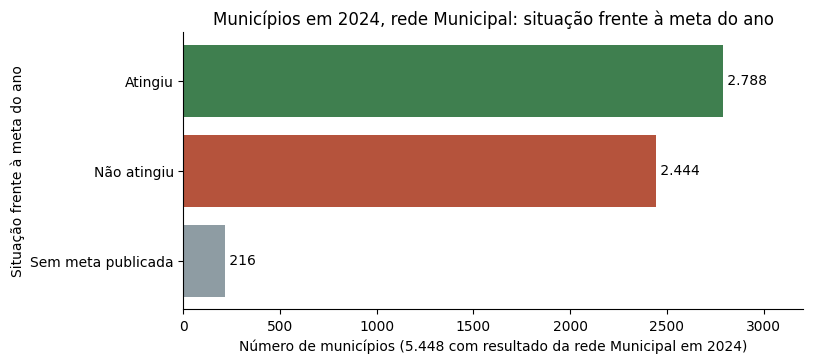


=== GRÁFICO 2 · Brasil, rede Pública ===
 ano  taxa_alfabetizacao  meta_do_ano
2023                55.9          NaN
2024                59.2         59.9
2025                66.0         64.0
2026                 NaN         67.0
2027                 NaN         71.0
2028                 NaN         74.0
2029                 NaN         77.0
2030                 NaN         80.0
/content/graficos/grafico_2_brasil_observado_x_meta.png


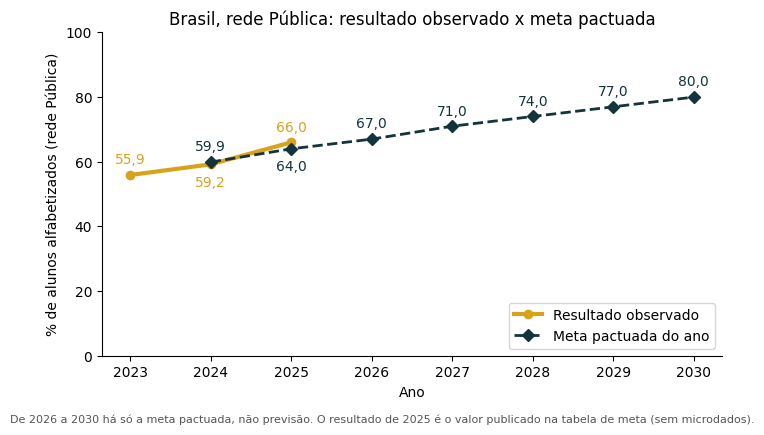


=== GRÁFICO 3 · Variação de 2023 para 2024, rede Municipal ===
      regiao  cidades  variacao_mediana  pct_que_piorou
Centro-Oeste      462              7.04            24.5
     Sudeste     1612              7.03            27.9
       Norte      413              2.71            39.5
    Nordeste     1779              2.06            42.0
         Sul     1130             -5.76            68.8
/content/graficos/grafico_3_variacao_por_regiao_2023_2024.png


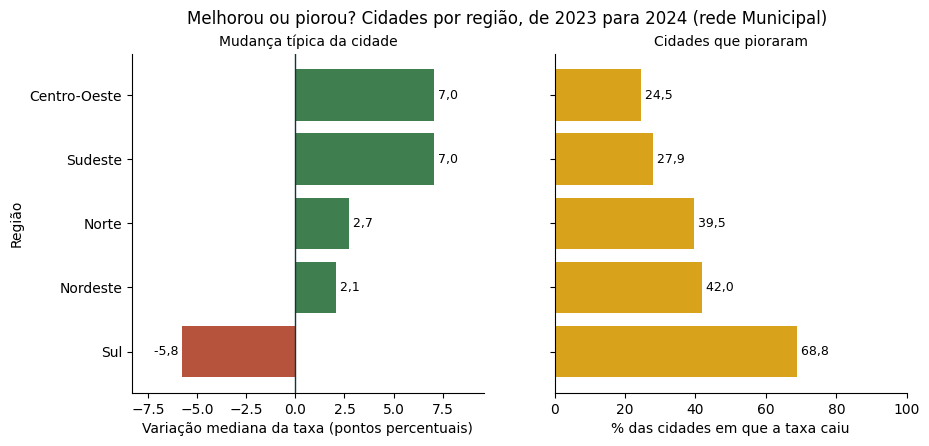


=== GRÁFICO 4 · Regiões, rede Municipal, 2024 ===
      regiao  cidades_com_taxa  taxa_do_meio  percentual_que_atingiu
Centro-Oeste               464         73.43                   73.10
     Sudeste              1626         70.65                   66.23
         Sul              1143         66.10                   33.87
    Nordeste              1780         52.63                   50.12
       Norte               435         49.19                   43.70
/content/graficos/grafico_4_regioes_nivel_x_meta_2024.png


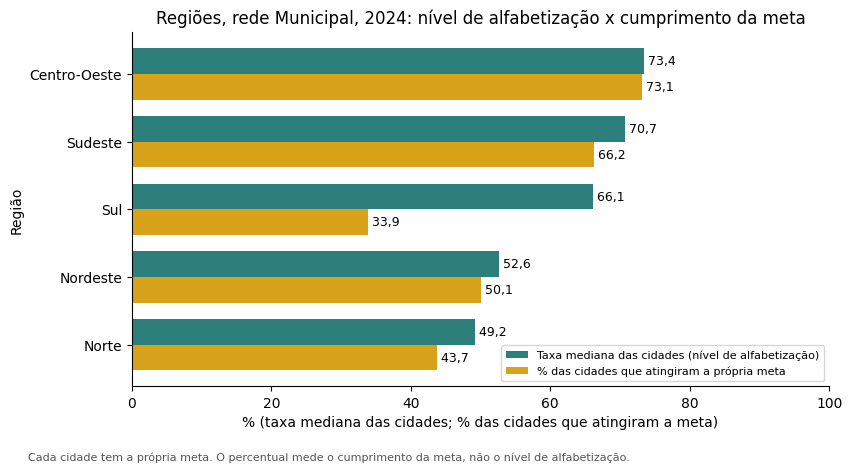


=== GRÁFICO 5 · base_modelagem: municípios prontos para treino ===
municípios: 5.396 | correlação entre a taxa de 2023 e a de 2024: 0.635
       taxa_2023  alvo_taxa_2024
count    5396.00         5396.00
mean       60.19           62.87
std        19.76           19.31
min         4.35            4.40
25%        46.47           48.40
50%        60.62           64.15
75%        74.94           77.62
max       100.00          100.00
/content/graficos/grafico_5_base_modelagem_2023_x_2024.png


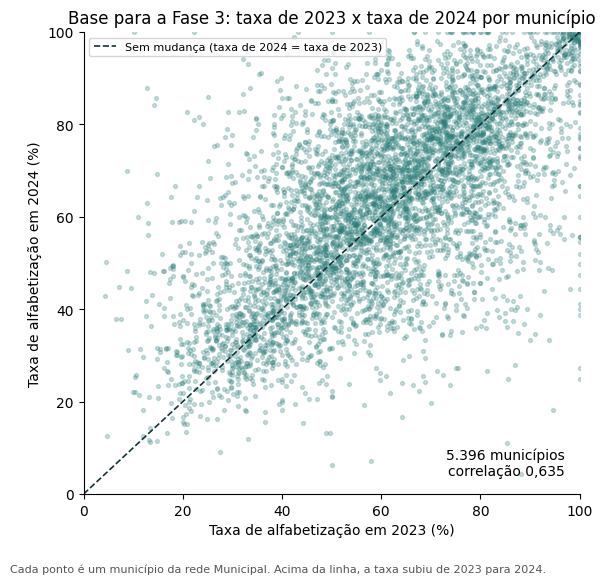


Pacote: /content/graficos.zip (891.8 KiB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
# ETAPA 4.9 · Gráficos dos resultados da Gold
# Gera os cinco gráficos da apresentação, lendo as tabelas da Gold (meta_vs_resultado,
# evolucao_temporal, desigualdade_regional e base_modelagem). Cada um responde a uma pergunta da Gold e é
# precedido da tabela de onde saem os números. Se faltar uma categoria esperada, a célula para: um gráfico não pode
# esconder dado.
# As imagens ficam em /content/graficos e vão num único zip.
import os
import zipfile

import matplotlib
import matplotlib.pyplot as plt

print(f"matplotlib {matplotlib.__version__}")

PASTA_GRAFICOS = "/content/graficos"
os.makedirs(PASTA_GRAFICOS, exist_ok=True)

COR_ATINGIU, COR_NAO_ATINGIU, COR_SEM_META = "#3f7f4f", "#b5533c", "#8e9ca3"
COR_TAXA, COR_META = "#2d7f7b", "#d9a21b"


def milhar(n) -> str:
    """Número inteiro com ponto de milhar (2788 -> 2.788)."""
    return f"{int(n):,}".replace(",", ".")


def virgula(x, casas: int = 1) -> str:
    """Número decimal com vírgula (73.1 -> 73,1)."""
    return f"{x:.{casas}f}".replace(".", ",")


def salvar(figura, nome: str) -> str:
    caminho = f"{PASTA_GRAFICOS}/{nome}"
    figura.savefig(caminho, dpi=200, bbox_inches="tight")
    return caminho


# Gráfico 1 · Municípios em 2024 frente à meta do ano (rede Municipal)
df_situacao = consulta(f"""
    SELECT situacao_meta, COUNT(*) AS municipios
    FROM `{G}.meta_vs_resultado`
    WHERE nivel = 'municipio' AND ano = 2024
    GROUP BY situacao_meta
""").set_index("situacao_meta")

ORDEM_SITUACAO = [
    ("atingiu", "Atingiu", COR_ATINGIU),
    ("nao atingiu", "Não atingiu", COR_NAO_ATINGIU),
    ("sem meta", "Sem meta publicada", COR_SEM_META),
]
inesperadas = set(df_situacao.index) - {c for c, _, _ in ORDEM_SITUACAO}
ausentes = {c for c, _, _ in ORDEM_SITUACAO} - set(df_situacao.index)
if inesperadas or ausentes:
    raise ValueError(
        f"Situações inesperadas: {sorted(inesperadas)}; ausentes: {sorted(ausentes)}. "
        "O gráfico 1 não foi gerado."
    )

print("=== GRÁFICO 1 · Municípios em 2024, rede Municipal ===")
print(df_situacao.loc[[c for c, _, _ in ORDEM_SITUACAO]].to_string())

fig1, ax1 = plt.subplots(figsize=(8, 3.6))
rotulos = [nome for _, nome, _ in ORDEM_SITUACAO]
valores = [int(df_situacao.loc[c, "municipios"]) for c, _, _ in ORDEM_SITUACAO]
barras = ax1.barh(rotulos, valores, color=[cor for _, _, cor in ORDEM_SITUACAO])
ax1.invert_yaxis()
for barra, valor in zip(barras, valores):
    ax1.text(valor, barra.get_y() + barra.get_height() / 2, f" {milhar(valor)}", va="center")
ax1.set_xlim(0, max(valores) * 1.15)
ax1.set_xlabel(f"Número de municípios ({milhar(sum(valores))} com resultado da rede Municipal em 2024)")
ax1.set_ylabel("Situação frente à meta do ano")
ax1.set_title("Municípios em 2024, rede Municipal: situação frente à meta do ano")
ax1.spines[["top", "right"]].set_visible(False)
print(salvar(fig1, "grafico_1_municipios_frente_a_meta_2024.png"))
plt.show()

# Gráfico 2 · Brasil: resultado observado x meta pactuada do ano
df_brasil = consulta(f"""
    SELECT ano, taxa_alfabetizacao, meta_do_ano
    FROM `{G}.evolucao_temporal`
    WHERE nivel = 'brasil'
    ORDER BY ano
""")
if df_brasil.empty or df_brasil["taxa_alfabetizacao"].notna().sum() == 0:
    raise ValueError("evolucao_temporal sem linhas do Brasil. O gráfico 2 não foi gerado.")

print("\n=== GRÁFICO 2 · Brasil, rede Pública ===")
print(df_brasil.to_string(index=False))

observado = df_brasil.dropna(subset=["taxa_alfabetizacao"])
meta = df_brasil.dropna(subset=["meta_do_ano"])
fig2, ax2 = plt.subplots(figsize=(8, 4.2))
ax2.plot(observado["ano"], observado["taxa_alfabetizacao"], color=COR_META, marker="o",
         linewidth=3, label="Resultado observado")
ax2.plot(meta["ano"], meta["meta_do_ano"], color="#14343b", marker="D", linestyle="--",
         linewidth=2, label="Meta pactuada do ano")
obs_por_ano = dict(zip(observado["ano"], observado["taxa_alfabetizacao"]))
meta_por_ano = dict(zip(meta["ano"], meta["meta_do_ano"]))
# O rótulo do valor mais alto vai acima e o do mais baixo abaixo, para não cobrir o outro ponto.
for ano, valor in obs_por_ano.items():
    acima = ano not in meta_por_ano or valor >= meta_por_ano[ano]
    ax2.annotate(virgula(valor), (ano, valor), textcoords="offset points",
                 xytext=(0, 8 if acima else -16), ha="center", color=COR_META)
for ano, valor in meta_por_ano.items():
    acima = ano not in obs_por_ano or valor > obs_por_ano[ano]
    ax2.annotate(virgula(valor), (ano, valor), textcoords="offset points",
                 xytext=(0, 8 if acima else -16), ha="center", color="#14343b")
ax2.set_ylim(0, 100)
ax2.set_xticks(list(df_brasil["ano"]))
ax2.set_xlabel("Ano")
ax2.set_ylabel("% de alunos alfabetizados (rede Pública)")
ax2.set_title("Brasil, rede Pública: resultado observado x meta pactuada")
ax2.legend(loc="lower right")
ax2.spines[["top", "right"]].set_visible(False)
fig2.text(0.01, -0.05,
          "De 2026 a 2030 há só a meta pactuada, não previsão. O resultado de 2025 é o valor "
          "publicado na tabela de meta (sem microdados).",
          fontsize=8, color="#555555", ha="left")
print(salvar(fig2, "grafico_2_brasil_observado_x_meta.png"))
plt.show()

# Gráfico 3 · Melhorou ou piorou? Variação de 2023 para 2024 por região (rede Municipal)
df_variacao = consulta(f"""
    SELECT
        nome_regiao                                         AS regiao,
        COUNT(*)                                            AS cidades,
        ROUND({percentil_sql('variacao_anual', 0.5)}, 2)    AS variacao_mediana,
        ROUND(100 * COUNTIF(variacao_anual < 0) / COUNT(*), 1) AS pct_que_piorou
    FROM `{G}.evolucao_temporal`
    WHERE nivel = 'municipio' AND ano = 2024 AND variacao_anual IS NOT NULL
    GROUP BY nome_regiao
    ORDER BY variacao_mediana DESC
""")
if len(df_variacao) != 5 or df_variacao[["variacao_mediana", "pct_que_piorou"]].isna().any().any():
    raise ValueError(
        f"evolucao_temporal trouxe {len(df_variacao)} regiões (esperado: 5) ou valores vazios. "
        "O gráfico 3 não foi gerado."
    )

print("\n=== GRÁFICO 3 · Variação de 2023 para 2024, rede Municipal ===")
print(df_variacao.to_string(index=False))

fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
y = list(range(len(df_variacao)))
cores = [COR_ATINGIU if v >= 0 else COR_NAO_ATINGIU for v in df_variacao["variacao_mediana"]]
ax3a.barh(y, df_variacao["variacao_mediana"], color=cores)
ax3a.axvline(0, color="#14343b", linewidth=1)
for yi, v in zip(y, df_variacao["variacao_mediana"]):
    ax3a.text(v, yi, f" {virgula(v)}" if v >= 0 else f"{virgula(v)} ", va="center",
              ha="left" if v >= 0 else "right", fontsize=9)
ax3a.set_yticks(y)
ax3a.set_yticklabels(df_variacao["regiao"])
ax3a.invert_yaxis()
ax3a.margins(x=0.2)
ax3a.set_xlabel("Variação mediana da taxa (pontos percentuais)")
ax3a.set_ylabel("Região")
ax3a.set_title("Mudança típica da cidade", fontsize=10)
ax3b.barh(y, df_variacao["pct_que_piorou"], color=COR_META)
for yi, v in zip(y, df_variacao["pct_que_piorou"]):
    ax3b.text(v, yi, f" {virgula(v)}", va="center", fontsize=9)
ax3b.set_xlim(0, 100)
ax3b.set_xlabel("% das cidades em que a taxa caiu")
ax3b.set_title("Cidades que pioraram", fontsize=10)
for eixo in (ax3a, ax3b):
    eixo.spines[["top", "right"]].set_visible(False)
fig3.suptitle("Melhorou ou piorou? Cidades por região, de 2023 para 2024 (rede Municipal)")
print(salvar(fig3, "grafico_3_variacao_por_regiao_2023_2024.png"))
plt.show()

# Gráfico 4 · Regiões (rede Municipal, 2024): nível x cumprimento da meta
df_regioes = consulta(f"""
    SELECT grupo AS regiao, cidades_com_taxa, taxa_do_meio, percentual_que_atingiu
    FROM `{G}.desigualdade_regional`
    WHERE agrupamento = 'regiao' AND ano = 2024
    ORDER BY taxa_do_meio DESC
""")
if len(df_regioes) != 5 or df_regioes[["taxa_do_meio", "percentual_que_atingiu"]].isna().any().any():
    raise ValueError(
        f"desigualdade_regional trouxe {len(df_regioes)} regiões (esperado: 5) ou valores vazios. "
        "O gráfico 4 não foi gerado."
    )

print("\n=== GRÁFICO 4 · Regiões, rede Municipal, 2024 ===")
print(df_regioes.to_string(index=False))

fig4, ax4 = plt.subplots(figsize=(9, 4.6))
posicao = range(len(df_regioes))
altura = 0.38
b_taxa = ax4.barh([p - altura / 2 for p in posicao], df_regioes["taxa_do_meio"], altura,
                  color=COR_TAXA, label="Taxa mediana das cidades (nível de alfabetização)")
b_meta = ax4.barh([p + altura / 2 for p in posicao], df_regioes["percentual_que_atingiu"], altura,
                  color=COR_META, label="% das cidades que atingiram a própria meta")
for barras_grupo in (b_taxa, b_meta):
    for barra in barras_grupo:
        ax4.text(barra.get_width(), barra.get_y() + barra.get_height() / 2,
                 f" {virgula(barra.get_width())}", va="center", fontsize=9)
ax4.set_yticks(list(posicao))
ax4.set_yticklabels(df_regioes["regiao"])
ax4.invert_yaxis()
ax4.set_xlim(0, 100)
ax4.set_xlabel("% (taxa mediana das cidades; % das cidades que atingiram a meta)")
ax4.set_ylabel("Região")
ax4.set_title("Regiões, rede Municipal, 2024: nível de alfabetização x cumprimento da meta")
ax4.legend(loc="lower right", fontsize=8)
ax4.spines[["top", "right"]].set_visible(False)
fig4.text(0.01, -0.05,
          "Cada cidade tem a própria meta. O percentual mede o cumprimento da meta, "
          "não o nível de alfabetização.",
          fontsize=8, color="#555555", ha="left")
print(salvar(fig4, "grafico_4_regioes_nivel_x_meta_2024.png"))
plt.show()

# Gráfico 5 · Base para a Fase 3: taxa de 2023 x taxa de 2024 de cada município
df_base = consulta(f"""
    SELECT id_municipio, taxa_2023, alvo_taxa_2024
    FROM `{G}.base_modelagem`
    WHERE pronta_para_treino
""")
if df_base.empty or df_base[["taxa_2023", "alvo_taxa_2024"]].isna().any().any():
    raise ValueError("base_modelagem sem linhas prontas ou com valores vazios. O gráfico 5 não foi gerado.")

correlacao = df_base["taxa_2023"].corr(df_base["alvo_taxa_2024"])
print("\n=== GRÁFICO 5 · base_modelagem: municípios prontos para treino ===")
print(f"municípios: {milhar(len(df_base))} | correlação entre a taxa de 2023 e a de 2024: {correlacao:.3f}")
print(df_base[["taxa_2023", "alvo_taxa_2024"]].describe().round(2).to_string())

fig5, ax5 = plt.subplots(figsize=(6.4, 6))
ax5.scatter(df_base["taxa_2023"], df_base["alvo_taxa_2024"], s=8, alpha=0.25, color=COR_TAXA)
ax5.plot([0, 100], [0, 100], color="#14343b", linestyle="--", linewidth=1.2,
         label="Sem mudança (taxa de 2024 = taxa de 2023)")
ax5.set_xlim(0, 100)
ax5.set_ylim(0, 100)
ax5.set_xlabel("Taxa de alfabetização em 2023 (%)")
ax5.set_ylabel("Taxa de alfabetização em 2024 (%)")
ax5.set_title("Base para a Fase 3: taxa de 2023 x taxa de 2024 por município")
ax5.legend(loc="upper left", fontsize=8)
ax5.text(0.97, 0.04, f"{milhar(len(df_base))} municípios\ncorrelação {virgula(correlacao, 3)}",
         transform=ax5.transAxes, ha="right", fontsize=10)
ax5.spines[["top", "right"]].set_visible(False)
fig5.text(0.01, -0.02,
          "Cada ponto é um município da rede Municipal. Acima da linha, a taxa subiu de 2023 para 2024.",
          fontsize=8, color="#555555", ha="left")
print(salvar(fig5, "grafico_5_base_modelagem_2023_x_2024.png"))
plt.show()

# Um único .zip, para baixar as imagens de uma vez.
caminho_zip_graficos = "/content/graficos.zip"
with zipfile.ZipFile(caminho_zip_graficos, "w", zipfile.ZIP_DEFLATED) as pacote:
    for nome in sorted(os.listdir(PASTA_GRAFICOS)):
        pacote.write(f"{PASTA_GRAFICOS}/{nome}", arcname=f"graficos/{nome}")
print(f"\nPacote: {caminho_zip_graficos} ({os.path.getsize(caminho_zip_graficos) / 1024:,.1f} KiB)")

# Download do pacote.
from google.colab import files
files.download(caminho_zip_graficos)

**Leitura.** O percentual de cidades que atingiram a meta mede o **cumprimento da meta de cada cidade**, que parte do nível de 2023, e não o nível de alfabetização. Por isso o quarto gráfico mostra, lado a lado, a taxa mediana e esse percentual, e o terceiro mostra se as cidades de cada região melhoraram ou pioraram de um ano para o outro. O trecho de 2026 a 2030 do segundo gráfico é a meta pactuada, não previsão. O quinto gráfico mostra que a taxa de 2023 explica parte da de 2024, mas não toda: é essa dispersão que justifica um modelo com mais variáveis na Fase 3.

---
## Etapa 5: Diário de bordo
Registra a execução em `quality_reports.metricas_por_tabela` (entrada, saída, MB lidos, duração, status e job_id por tabela) e `quality_reports.execucoes` (resumo e situação). Execuções com falha são registradas pelo vigia de erros (1.2), com a etapa e a mensagem do erro.

### Etapa 5.1 · Diário de bordo

In [43]:
# ETAPA 5.1 · Diário de bordo
# Grava esta execução como "sucesso" no diário de bordo e mostra, por tabela, as linhas
# de entrada e de saída, o consumo por camada e o histórico.
# Falhas são gravadas pelo vigia de erros (Etapa 1.2).
df_diario, df_resumo = registrar_execucao("sucesso")

if df_diario.empty:
    raise ValueError(
        "Não há medições nesta sessão. Rode a Bronze, a Silver e a Gold "
        "na mesma sessão antes do diário de bordo."
    )

camadas = [c for c in ["bronze", "silver", "gold"] if c in set(df_diario["camada"])]

print(f"\n=== EXECUÇÃO {EXECUCAO_ID}: ENTRADA x SAÍDA POR TABELA ===")
print(df_diario[["tabela", "linhas_entrada", "linhas", "mb_estimados", "mb_lidos", "duracao_s", "status"]]
      .rename(columns={"linhas": "linhas_saida"}).to_string(index=False))

print("\n=== CONSUMO POR CAMADA ===")
print(df_diario.groupby("camada").agg(
    tabelas=("tabela", "count"),
    linhas_saida=("linhas", "sum"),
    mb_lidos=("mb_lidos", "sum"),
    duracao_s=("duracao_s", "sum"),
).reindex(camadas).round(2).reset_index().to_string(index=False))

print("\n=== RESUMO DESTA EXECUÇÃO ===")
print(df_resumo.drop(columns=["registrado_em", "etapa_da_falha", "erro"]).T.to_string(header=False))

print("\n=== HISTÓRICO: EXECUÇÕES GRAVADAS NO DIÁRIO ===")
print(consulta(f"""
    SELECT
        execucao_id,
        FORMAT_TIMESTAMP('%d/%m/%Y %H:%M', registrado_em) AS registrado_em_utc,
        situacao,
        tabelas_gravadas,
        linhas_gravadas,
        mb_lidos,
        duracao_s,
        regras_que_passaram,
        regras_medidas,
        SUBSTR(etapa_da_falha, 1, 40) AS etapa_da_falha
    FROM `{TABELA_EXECUCOES}`
    ORDER BY registrado_em
""").to_string(index=False))

Diário gravado: 26 tabela(s) em fresh-lens-512607-c2.quality_reports.metricas_por_tabela e 1 resumo (sucesso) em fresh-lens-512607-c2.quality_reports.execucoes

=== EXECUÇÃO 20261024_070829: ENTRADA x SAÍDA POR TABELA ===
                             tabela  linhas_entrada  linhas_saida  mb_estimados  mb_lidos  duracao_s status
                          bronze.uf             145           145          0.01      0.01       1.04     OK
                   bronze.municipio           23995         23995          1.75      1.75       1.39     OK
                      bronze.alunos         3867999       3867999        256.10    256.10       9.58     OK
   bronze.meta_alfabetizacao_brasil               3             3          0.00      0.00       1.03     OK
       bronze.meta_alfabetizacao_uf              81            81          0.01      0.01       0.96     OK
bronze.meta_alfabetizacao_municipio           10704         10704          1.10      1.10       1.46     OK
                  bron

**Leitura.** A tabela mostra, para cada uma das 26 tabelas gravadas, quantas linhas entraram e saíram, quanto foi lido e quanto tempo levou. A gravação de `silver.alunos` é a etapa mais pesada. O histórico no fim é o diário de bordo, que acumula as execuções sem sobrescrever as anteriores.

### Etapa 5.2 · FinOps: consumo medido e custo projetado
Mede os bytes faturados por todos os jobs da execução (`INFORMATION_SCHEMA.JOBS_BY_USER`) e o armazenamento de cada dataset, e projeta o custo mensal do mesmo desenho fora do Sandbox, em três cadências. A cadência pretendida é mensal: a fonte é publicada uma vez por ano. O ambiente usado é o Sandbox, que não cobra; a tabela mostra o que o mesmo desenho custaria em produção. A cadência semanal e a diária entram para mostrar como o custo escala.

No desenho adotado, a leitura da Bronze filtra por partição e a Silver pede só as colunas de que precisa, então o custo de consulta por execução não cresce com o histórico. O que cresce é o armazenamento da Bronze, uma cópia por dia.

In [44]:
# ETAPA 5.2 · FinOps: consumo medido e custo projetado
# Mede o consumo real desta execução e projeta o custo mensal do mesmo desenho em produção
# (cobrança por consulta, região US). O Sandbox não cobra; a projeção mostra o custo fora dele.
# - Consultas: bytes faturados de todos os jobs da execução (inclui conferências e
#   validações), lidos de INFORMATION_SCHEMA.JOBS_BY_USER.
# - Armazenamento: tamanho atual de cada conjunto de tabelas (metadados, sem custo) e de
#   uma cópia da Bronze, que cresce a cada dia guardado (retenção de 59 dias no Sandbox).
# - Cargas de arquivo (load jobs) e streaming por load job: gratuitos.
# Preços: cloud.google.com/bigquery/pricing, região US (várias regiões), a mesma dos
# datasets. A página abre em Iowa (us-central1), onde o armazenamento é mais caro.
# Consultados em 22/10/2026.
from google.api_core.exceptions import BadRequest, Forbidden, NotFound

PRECO_TIB_CONSULTA = 6.25                  # US$ por TiB processado (on-demand)
PRECO_GIB_ATIVO_MES = 0.000027397 * 730    # US$ por GiB-mês, armazenamento lógico ativo (US)
PRECO_GIB_LONGO_MES = 0.000013699 * 730    # US$ por GiB-mês, após 90 dias sem alteração (US)
GRATIS_TIB_CONSULTA = 1.0                  # por mês
GRATIS_GIB_ARMAZENAMENTO = 10.0            # por mês

# Frequência de execução pretendida: mensal. O INEP publica uma vez por ano, então rodar
# todo mês já pega qualquer atualização. A semanal e a diária entram só para comparar.
CADENCIAS = {"mensal (pretendida)": 1, "semanal": 4, "diária": 30}

MESES_DE_HISTORICO = 12                    # horizonte para o crescimento da Bronze

GIB, TIB = 1024**3, 1024**4
inicio_execucao = datetime.strptime(EXECUCAO_ID, "%Y%m%d_%H%M%S").replace(tzinfo=timezone.utc)

# Consultas: tudo o que esta execução rodou no BigQuery.
try:
    df_jobs = consulta(f"""
        SELECT
            job_type,
            COUNT(*)                                   AS jobs,
            SUM(IFNULL(total_bytes_processed, 0))      AS bytes_processados,
            SUM(IFNULL(total_bytes_billed, 0))         AS bytes_faturados,
            ROUND(SUM(TIMESTAMP_DIFF(end_time, start_time, MILLISECOND)) / 1000, 1) AS duracao_s
        FROM `region-{LOCATION.lower()}`.INFORMATION_SCHEMA.JOBS_BY_USER
        WHERE project_id = '{PROJECT_ID}'
          AND creation_time >= TIMESTAMP('{inicio_execucao.isoformat()}')
          AND state = 'DONE'
        GROUP BY job_type
        ORDER BY bytes_faturados DESC
    """)
    bytes_faturados = float(df_jobs["bytes_faturados"].sum())
    fonte_consumo = "INFORMATION_SCHEMA.JOBS_BY_USER"
except (BadRequest, Forbidden, NotFound) as erro:
    # Sem acesso à visão de jobs: usa o diário de bordo (só as gravações).
    print(f"INFORMATION_SCHEMA indisponível ({type(erro).__name__}); usando o diário de bordo.")
    df_jobs = None
    bytes_faturados = float(df_diario["mb_lidos"].sum()) * 1024**2
    fonte_consumo = "diário de bordo (gravações)"

# Armazenamento: tamanho atual de cada dataset.
linhas_armazenamento = []
for camada in ["bronze", "silver", "gold", "quality_reports"]:
    for item in client.list_tables(f"{PROJECT_ID}.{camada}"):
        t = client.get_table(item.reference)
        linhas_armazenamento.append({"dataset": camada, "tabela": t.table_id,
                                     "linhas": t.num_rows, "bytes": t.num_bytes or 0})
df_armazenamento = pd.DataFrame(linhas_armazenamento)

# Tamanho de uma cópia da Bronze: proporção das linhas da cópia usada em cada tabela.
copia_bronze_bytes = 0.0
for r in df_armazenamento[df_armazenamento.dataset == "bronze"].itertuples():
    linhas_copia = LINHAS_DA_COPIA.get(r.tabela)
    if linhas_copia and r.linhas:
        copia_bronze_bytes += r.bytes * linhas_copia / r.linhas
fixo_bytes = float(df_armazenamento[df_armazenamento.dataset != "bronze"]["bytes"].sum())

print(f"=== CONSUMO MEDIDO NA EXECUÇÃO {EXECUCAO_ID} (fonte: {fonte_consumo}) ===")
if df_jobs is not None:
    print(df_jobs.assign(gib_faturados=(df_jobs.bytes_faturados / GIB).round(3))
          [["job_type", "jobs", "gib_faturados", "duracao_s"]].to_string(index=False))
print(f"Total faturável por execução: {bytes_faturados / GIB:.3f} GiB")

print("\n=== ARMAZENAMENTO ATUAL POR DATASET ===")
print(df_armazenamento.groupby("dataset").agg(tabelas=("tabela", "count"), linhas=("linhas", "sum"),
      gib=("bytes", lambda b: round(b.sum() / GIB, 3))).reset_index().to_string(index=False))
print(f"Uma cópia da Bronze: {copia_bronze_bytes / GIB:.3f} GiB | Silver + Gold + controle: {fixo_bytes / GIB:.3f} GiB")

# Tabela de custos.
custos = []
for nome, execucoes in CADENCIAS.items():
    tib_mes = bytes_faturados * execucoes / TIB
    gib_armazenado = (fixo_bytes + copia_bronze_bytes * execucoes * MESES_DE_HISTORICO) / GIB
    custos += [
        {"cadencia": nome, "servico": "BigQuery · consultas on-demand", "unidade": "TiB processado",
         "quantidade_medida": f"{bytes_faturados / GIB:.3f} GiB/execução",
         "preco_unitario_usd": PRECO_TIB_CONSULTA,
         "custo_mensal_usd": round(tib_mes * PRECO_TIB_CONSULTA, 4),
         "custo_mensal_com_gratuidade_usd": round(max(tib_mes - GRATIS_TIB_CONSULTA, 0) * PRECO_TIB_CONSULTA, 4)},
        {"cadencia": nome, "servico": "BigQuery · armazenamento ativo", "unidade": "GiB-mês",
         "quantidade_medida": f"{gib_armazenado:.2f} GiB após {MESES_DE_HISTORICO} meses de histórico",
         "preco_unitario_usd": round(PRECO_GIB_ATIVO_MES, 4),
         "custo_mensal_usd": round(gib_armazenado * PRECO_GIB_ATIVO_MES, 4),
         "custo_mensal_com_gratuidade_usd": round(max(gib_armazenado - GRATIS_GIB_ARMAZENAMENTO, 0) * PRECO_GIB_ATIVO_MES, 4)},
        {"cadencia": nome, "servico": "BigQuery · carga (load jobs, batch e streaming)", "unidade": "GiB carregado",
         "quantidade_medida": "load jobs da execução", "preco_unitario_usd": 0.0,
         "custo_mensal_usd": 0.0, "custo_mensal_com_gratuidade_usd": 0.0},
    ]
df_custos = pd.DataFrame(custos)
print("\n=== TABELA DE CUSTOS PROJETADA (produção, on-demand, US) ===")
print(df_custos.to_string(index=False))
print("\nTotal mensal por cadência (US$):")
print(df_custos.groupby("cadencia", sort=False)[["custo_mensal_usd", "custo_mensal_com_gratuidade_usd"]]
      .sum().round(4).to_string())
print(f"\nPreço de armazenamento após 90 dias sem alteração (long-term): US$ {PRECO_GIB_LONGO_MES:.4f}/GiB-mês.")

=== CONSUMO MEDIDO NA EXECUÇÃO 20261024_070829 (fonte: INFORMATION_SCHEMA.JOBS_BY_USER) ===
job_type  jobs  gib_faturados  duracao_s
   QUERY   147          3.993       74.4
    LOAD     6            0.0        6.7
Total faturável por execução: 3.993 GiB

=== ARMAZENAMENTO ATUAL POR DATASET ===
        dataset  tabelas  linhas   gib
         bronze        8 3908525 0.746
           gold        6  107958 0.015
quality_reports        3     115 0.000
         silver       12 3984068 0.759
Uma cópia da Bronze: 0.746 GiB | Silver + Gold + controle: 0.774 GiB

=== TABELA DE CUSTOS PROJETADA (produção, on-demand, US) ===
           cadencia                                         servico        unidade                     quantidade_medida  preco_unitario_usd  custo_mensal_usd  custo_mensal_com_gratuidade_usd
mensal (pretendida)                  BigQuery · consultas on-demand TiB processado                    3.993 GiB/execução                6.25            0.0244                           0

**Leitura.** O valor faturável por execução inclui todas as consultas (gravações, conferências e validações) e é maior que os MB lidos nas gravações do diário por dois motivos: as conferências releem tabelas já gravadas, e o BigQuery fatura no mínimo 10 MB por consulta, mesmo nas pequenas. O armazenamento medido é o de uma cópia da Bronze mais Silver, Gold e `quality_reports` (impresso acima); a coluna de quantidade da tabela projeta esse valor para 12 meses. A cadência mensal cabe no nível gratuito. O item que cresce com o tempo é o armazenamento da Bronze, porque cada dia de execução acrescenta uma cópia completa, guardada até o fim da retenção (59 dias no Sandbox). A projeção de armazenamento supõe 12 meses de cópias ao preço do armazenamento ativo; é uma premissa de cálculo, não a retenção do Sandbox. O consumo medido é anterior ao streaming (Etapa 6) e não inclui essa etapa.

### Etapa 5.3 · Evidências do ambiente
Imprime no notebook o que o console do BigQuery mostra: datasets do projeto, particionamento de bronze.alunos e uma linha por partição (um dia de execução).

A lista de partições mostra as cópias diárias que ainda estão na Bronze: uma linha por dia de execução, e as dos dias anteriores permanecem até o fim da retenção. Uma segunda partição só aparece quando a execução acontece em outro dia (UTC). No Sandbox a expiração das partições é de 59 dias, o máximo aceito; com cobrança ativada ela é removida.

In [45]:
# ETAPA 5.3 · Evidências do ambiente
# Mostra os conjuntos de tabelas, o particionamento da Bronze e as partições guardadas
# (uma por dia de execução).

# Lista os conjuntos de tabelas do projeto: mostra que as quatro camadas existem.
print("=== DATASETS DO PROJETO ===")
for ds in sorted(client.list_datasets(), key=lambda d: d.dataset_id):
    print(f"   {ds.dataset_id}")

# Busca as partições de bronze.alunos (uma por dia de execução). Isso é feito antes de
# imprimir o bloco abaixo, porque a quantidade de dias vem desta lista.
df_particoes = consulta(f"""
    SELECT
        partition_id                                  AS particao,
        total_rows                                    AS linhas,
        ROUND(total_logical_bytes / POW(1024, 3), 3)  AS gib
    FROM `{B}`.INFORMATION_SCHEMA.PARTITIONS
    WHERE table_name = 'alunos'
    ORDER BY partition_id
""")

# Lê as informações de configuração da tabela de alunos da Bronze.
tabela_alunos = client.get_table(f"{B}.alunos")
particao = tabela_alunos.time_partitioning
print("\n=== bronze.alunos ===")
print(f"Particionada por: {particao.field} ({particao.type_})")
if particao.expiration_ms is None:
    print("Expiração das partições: nenhuma")
else:
    dias = particao.expiration_ms / (24 * 60 * 60 * 1000)
    print(f"Expiração das partições: {dias:.0f} dias (limite do Sandbox)")
print(f"Expiração da tabela (Sandbox): {tabela_alunos.expires}")
# Linhas e tamanho são o total de todas as partições. Por isso o número de dias
# guardados aparece junto: com 1 dia, o total é o de uma cópia; com 2 dias, é o dobro.
print(f"Dias guardados: {len(df_particoes)} | "
      f"Linhas (total dos dias): {tabela_alunos.num_rows:,} | "
      f"tamanho: {tabela_alunos.num_bytes / GIB:.3f} GiB")

# Mostra uma linha por dia de execução, ou seja, as cópias diárias que ainda estão na Bronze.
print("\n=== PARTIÇÕES DE bronze.alunos (uma por dia de execução) ===")
print(df_particoes.to_string(index=False))

=== DATASETS DO PROJETO ===
   bronze
   gold
   quality_reports
   silver

=== bronze.alunos ===
Particionada por: _ingestion_date (DAY)
Expiração das partições: 59 dias (limite do Sandbox)
Expiração da tabela (Sandbox): None
Dias guardados: 1 | Linhas (total dos dias): 3,867,999 | tamanho: 0.736 GiB

=== PARTIÇÕES DE bronze.alunos (uma por dia de execução) ===
particao  linhas   gib
20261024 3867999 0.736


---
## Etapa 6: Streaming simulado

Kafka 3.7.0 no próprio Colab. Eventos de nova medição de município para 2025 (mesmo formato de `bronze.municipio`), gerados a partir das taxas de 2024, com duplicatas e eventos inválidos inseridos de propósito. Todos os dados desta etapa têm `origem = 'simulado'` e não alteram as tabelas oficiais.

| Etapa | Conteúdo |
|---|---|
| 6.0 | Kafka + ZooKeeper e tópico com 3 partições (download de ~10 min na primeira execução da sessão) |
| 6.1 | Produtor e fila de 216 eventos (200 distintos, 16 duplicados, 12 inválidos) |
| 6.2 | Consumo em micro-lotes de 25: deduplicação, validação, gravação na Bronze e commit manual |
| 6.3 | Silver e Gold de streaming (mesmo caminho do lote) e validação de qualidade |
| 6.4 | Latência (criado_em → recebido_em) e comparação batch x streaming |

O evento nasce sem `criado_em`: o produtor preenche o campo no instante do envio ao Kafka, e o consumidor anota `recebido_em` na chegada. É dessa diferença que sai a latência medida na 6.4.

### Etapa 6.0 · Kafka no Colab

In [46]:
# ETAPA 6.0 · Streaming: Kafka no Colab
# Instala e liga o Kafka 3.7.0 (com ZooKeeper) no Colab e cria o tópico com 3 partições.
# O Kafka só existe durante a sessão; os eventos aceitos ficam gravados no BigQuery.
# O download do archive.apache.org leva cerca de 10 min na primeira vez da sessão.
# O arquivo é conferido pelo SHA-512 publicado pela Apache.
import subprocess, os, time, logging

logging.getLogger("kafka").setLevel(logging.CRITICAL)

KAFKA_VERSION = "3.7.0"
SCALA_VERSION = "2.13"
KAFKA_DIR     = f"/opt/kafka_{SCALA_VERSION}-{KAFKA_VERSION}"
KAFKA_URL     = f"https://archive.apache.org/dist/kafka/{KAFKA_VERSION}/kafka_{SCALA_VERSION}-{KAFKA_VERSION}.tgz"
KAFKA_ARCHIVE = "/tmp/kafka.tgz"
BIN           = f"{KAFKA_DIR}/bin"


def porta_aberta(porta):
    """Diz se algum programa já está escutando nesta porta."""
    return subprocess.run(["nc", "-z", "-w1", "localhost", str(porta)], capture_output=True).returncode == 0


def aguardar_porta(porta, nome, max_seg=35):
    """Espera o serviço ligar, testando a porta uma vez por segundo."""
    print(f"   Aguardando {nome}", end="")
    for _ in range(max_seg):
        time.sleep(1)
        print(".", end="", flush=True)
        if porta_aberta(porta):
            print(" OK")
            return True
    print(" ERRO")
    return False


# 1) Java: o Kafka é escrito em Java e precisa dele para rodar.
if subprocess.run(["java", "-version"], capture_output=True).returncode != 0:
    os.system("apt-get install -y -q default-jre-headless 2>/dev/null")
print("1/5 Java OK")

# 2) Netcat: ferramenta usada para testar se as portas já abriram.
if subprocess.run(["which", "nc"], capture_output=True).returncode != 0:
    os.system("apt-get install -y -q netcat-openbsd 2>/dev/null")
print("2/5 Netcat OK")

# 3) Instalação: usa a cópia da sessão atual; se não houver, o espelho; depois o Google
#    Drive; por último o archive.apache.org.
#    Qualquer cópia é conferida pelo SHA-512 oficial antes de ser usada.

# Espelho opcional do .tgz (ex.: arquivo de um GitHub Release). Vazio = não usa.
KAFKA_ESPELHO_URL = ""

USAR_CACHE_NO_DRIVE = False     # True: guarda e reaproveita o Kafka no seu Google Drive
PASTA_CACHE = "/content/drive/MyDrive/kafka_cache"
NOME_ARQUIVO = f"kafka_{SCALA_VERSION}-{KAFKA_VERSION}.tgz"
COPIA_NO_DRIVE = f"{PASTA_CACHE}/{NOME_ARQUIVO}"
HASH_URL = f"{KAFKA_URL}.sha512"   # arquivo pequeno (~1 KB) com a impressão digital oficial


def baixar(url: str, destino: str) -> None:
    """Baixa o arquivo mostrando a barra de progresso na célula.

    os.system manda a saída do wget para o terminal do Colab, onde ela não aparece;
    get_ipython().system (o mesmo que "!wget") mostra a barra aqui.
    """
    get_ipython().system(f"wget --progress=bar:force:noscroll {url} -O {destino}")


def hash_oficial():
    """Baixa a impressão digital SHA-512 publicada pela Apache (arquivo de 1 KB)."""
    import re, urllib.request
    try:
        texto = urllib.request.urlopen(HASH_URL, timeout=60).read().decode()
    except Exception as erro:
        print(f"   Aviso: não consegui baixar o hash oficial ({erro}). Conferindo só o tamanho.")
        return None
    # O arquivo da Apache vem como "nome.tgz: 1A2B 3C4D ...". Tira o nome e
    # fica só com os caracteres hexadecimais, em minúsculas.
    return re.sub(r"[^0-9a-f]", "", texto.replace(NOME_ARQUIVO, "").lower())


def arquivo_confere(caminho, esperado):
    """Confere tamanho mínimo e, se houver hash oficial, a impressão digital."""
    import hashlib
    if not os.path.isfile(caminho) or os.path.getsize(caminho) < 50 * 1024**2:
        return False                     # ausente ou pequeno demais: download incompleto
    if esperado is None:
        return True
    h = hashlib.sha512()
    with open(caminho, "rb") as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloco)
    return h.hexdigest() == esperado


if os.path.isfile(f"{BIN}/zookeeper-server-start.sh"):
    print("3/5 Kafka já instalado nesta sessão")
else:
    esperado = hash_oficial()
    origem = None

    # b) Espelho (KAFKA_ESPELHO_URL).
    if KAFKA_ESPELHO_URL:
        print("3/5 Baixando o Kafka da cópia do grupo (GitHub)...")
        baixar(KAFKA_ESPELHO_URL, KAFKA_ARCHIVE)
        if arquivo_confere(KAFKA_ARCHIVE, esperado):
            origem = "cópia do grupo (GitHub)"
        else:
            print("   A cópia do grupo não passou na conferência. Tentando outro caminho.")

    # c) Cache no Google Drive.
    if origem is None and USAR_CACHE_NO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")      # pede autorização na primeira vez
        if os.path.isfile(COPIA_NO_DRIVE):
            print("3/5 Copiando o Kafka do seu Google Drive...")
            os.system(f"cp {COPIA_NO_DRIVE} {KAFKA_ARCHIVE}")
            if arquivo_confere(KAFKA_ARCHIVE, esperado):
                origem = "seu Google Drive"

    # d) Servidor oficial.
    if origem is None:
        print(f"3/5 Baixando o Kafka {KAFKA_VERSION} de archive.apache.org (lento, cerca de 10 min)...")
        baixar(KAFKA_URL, KAFKA_ARCHIVE)
        if not arquivo_confere(KAFKA_ARCHIVE, esperado):
            raise RuntimeError("O download do Kafka falhou ou veio incompleto. Rode de novo.")
        origem = "archive.apache.org"
        if USAR_CACHE_NO_DRIVE:
            os.makedirs(PASTA_CACHE, exist_ok=True)
            os.system(f"cp {KAFKA_ARCHIVE} {COPIA_NO_DRIVE}")
            print(f"   Cópia guardada no Drive: {COPIA_NO_DRIVE}")

    os.system(f"tar -xzf {KAFKA_ARCHIVE} -C /opt/")
    conferido = "SHA-512 conferido" if esperado else "só tamanho conferido"
    tamanho_mb = os.path.getsize(KAFKA_ARCHIVE) / 1024**2
    print(f"3/5 Kafka instalado a partir de: {origem} ({tamanho_mb:.0f} MB, {conferido})")

# 4) Configura o servidor para aceitar conexões do próprio Colab.
os.system("pkill -f kafka.Kafka 2>/dev/null; pkill -f zookeeper 2>/dev/null")
time.sleep(3)
os.system("rm -rf /tmp/kafka-logs /tmp/zookeeper")   # começa com a fila vazia
props = f"{KAFKA_DIR}/config/server.properties"
os.system(f"sed -i '/^advertised\\.listeners/d;/^listeners=/d;/^log\\.dirs/d' {props}")
with open(props, "a") as f:
    f.write("\nlisteners=PLAINTEXT://0.0.0.0:9092\n")
    f.write("advertised.listeners=PLAINTEXT://localhost:9092\n")
    f.write("log.dirs=/tmp/kafka-logs\n")
print("4/5 Configuração OK")

# 5) Sobe o ZooKeeper e depois o broker.
subprocess.Popen(f"{BIN}/zookeeper-server-start.sh {KAFKA_DIR}/config/zookeeper.properties".split(),
                 stdout=open("/tmp/zookeeper.log", "w"), stderr=subprocess.STDOUT, preexec_fn=os.setsid)
if not aguardar_porta(2181, "ZooKeeper"):
    raise RuntimeError("O ZooKeeper não ligou. Veja /tmp/zookeeper.log")
subprocess.Popen(f"{BIN}/kafka-server-start.sh {props}".split(),
                 stdout=open("/tmp/kafka.log", "w"), stderr=subprocess.STDOUT, preexec_fn=os.setsid)
if not aguardar_porta(9092, "Kafka"):
    raise RuntimeError("O Kafka não ligou. Veja /tmp/kafka.log")

# Cliente Python do Kafka.
os.system("pip install -q kafka-python-ng==2.2.3")
from kafka import KafkaAdminClient
from kafka.admin import NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "localhost:9092"
TOPICO = "medicoes-alfabetizacao"

# Cria o tópico: a fila onde as novas medições vão chegar.
# Com 3 partições, a mesma cidade vai sempre para a mesma partição.
for tentativa in range(10):
    try:
        admin = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
        try:
            admin.create_topics([NewTopic(name=TOPICO, num_partitions=3, replication_factor=1)])
            print(f"5/5 Tópico '{TOPICO}' criado (3 partições)")
        except TopicAlreadyExistsError:
            print(f"5/5 Tópico '{TOPICO}' já existia")
        break
    except Exception:
        time.sleep(2)   # o servidor pode levar alguns segundos para aceitar pedidos
else:
    raise RuntimeError("Não foi possível criar o tópico no Kafka.")

print(f"\nKafka pronto. kafka-python-ng {versao('kafka-python-ng')}")

1/5 Java OK
2/5 Netcat OK
3/5 Baixando o Kafka 3.7.0 de archive.apache.org (lento, cerca de 10 min)...
--2026-10-24 07:16:47--  https://archive.apache.org/dist/kafka/3.7.0/kafka_2.13-3.7.0.tgz
Resolving archive.apache.org (archive.apache.org)... 65.108.204.189, 2a01:4f9:1a:a084::2
Connecting to archive.apache.org (archive.apache.org)|65.108.204.189|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 119028138 (114M) [application/x-gzip]
Saving to: ‘/tmp/kafka.tgz’

/tmp/kafka.tgz      100%[===================>] 113.51M  32.3MB/s    in 3.8s    

2026-10-24 07:16:51 (29.9 MB/s) - ‘/tmp/kafka.tgz’ saved [119028138/119028138]

3/5 Kafka instalado a partir de: archive.apache.org (114 MB, SHA-512 conferido)
4/5 Configuração OK
   Aguardando ZooKeeper.. OK
   Aguardando Kafka...... OK
5/5 Tópico 'medicoes-alfabetizacao' criado (3 partições)

Kafka pronto. kafka-python-ng 2.2.3


### Etapa 6.1 · Produtor

In [47]:
# ETAPA 6.1 · Streaming: produtor
# Cria os eventos "nova_medicao" de 2025, no mesmo formato de uma linha de bronze.municipio
# (ano, município, série, rede, taxa, média e proporções por nível, estas vazias),
# simulados a partir da taxa municipal de 2024
# de 200 cidades (seed fixa e consulta ordenada, para dar sempre a mesma amostra). Cada evento tem
# evento_id e criado_em; a hora de chegada é anotada pelo consumidor, para medir a
# latência de verdade.
# 8% dos eventos são enviados de novo (duplicatas, como acontece na entrega "pelo menos
# uma vez" do Kafka) e 6% recebem um defeito (taxa fora da faixa, cidade inexistente ou
# taxa vazia). O sorteio usa semente fixa para reproduzir a amostra e os defeitos.
import json, uuid, random
from datetime import datetime, timezone
import pandas as pd
from kafka import KafkaProducer

QTD_CIDADES = 200
PERC_REPETIDOS = 0.08   # 8% dos eventos serão reenviados
PERC_INVALIDOS = 0.06   # 6% dos eventos terão defeito

# As medições inventadas partem da taxa oficial de 2024 da rede municipal (lê só 2
# colunas de uma tabela pequena da Silver).
base_2024 = client.query(f"""
    SELECT id_municipio, taxa_alfabetizacao
    FROM `{S}.resultado_municipio`
    WHERE ano = 2024 AND comparavel_com_meta AND taxa_alfabetizacao IS NOT NULL
    ORDER BY id_municipio
""").to_dataframe()
amostra = base_2024.sample(n=QTD_CIDADES, random_state=42).reset_index(drop=True)


def criar_evento(id_municipio, taxa_2024, sorteio):
    """Monta uma nova medição: a taxa de 2024 com uma variação sorteada."""
    taxa = min(100.0, max(0.0, taxa_2024 + sorteio.gauss(3.0, 5.0)))
    return {
        "evento_id": str(uuid.uuid4()),
        "tipo_evento": "nova_medicao",
        "ano": 2025,
        "id_municipio": id_municipio,
        "serie": "2",
        "rede": "3",
        "taxa_alfabetizacao": round(taxa, 2),
        "media_portugues": None,                              # vazio, nunca zero
        **{coluna: None for coluna in COLUNAS_NIVEL},          # proporções por nível: vazias
        "criado_em": None,   # preenchido no momento do envio
    }


def estragar(evento, sorteio):
    """Coloca um defeito no evento, para testar a validação do consumidor."""
    defeito = sorteio.choice(["taxa impossivel", "cidade inexistente", "taxa faltando"])
    if defeito == "taxa impossivel":
        evento["taxa_alfabetizacao"] = 150.0
    elif defeito == "cidade inexistente":
        evento["id_municipio"] = "0000000"
    else:
        evento.pop("taxa_alfabetizacao")
    return evento


def montar_fila_de_envio(semente=42):
    """Lista, em ordem, os eventos que o produtor vai mandar (com repetidos e inválidos)."""
    sorteio = random.Random(semente)
    eventos = [criar_evento(r.id_municipio, r.taxa_alfabetizacao, sorteio) for r in amostra.itertuples()]
    for e in sorteio.sample(eventos, int(len(eventos) * PERC_INVALIDOS)):
        estragar(e, sorteio)
    fila = list(eventos)
    # Repetidos: o mesmo evento volta mais adiante na fila.
    for e in sorteio.sample(eventos, int(len(eventos) * PERC_REPETIDOS)):
        fila.insert(sorteio.randint(fila.index(e) + 1, len(fila)), e)
    return fila


def criar_produtor():
    """Produtor que espera a confirmação do Kafka a cada envio (acks=all) e tenta de novo
    em caso de erro.
    """
    return KafkaProducer(
        bootstrap_servers=BOOTSTRAP,
        value_serializer=lambda v: json.dumps(v).encode("utf-8"),
        key_serializer=lambda k: k.encode("utf-8") if k else None,
        acks="all",     # só considera enviado quando o Kafka confirma
        retries=3,      # tenta de novo em caso de erro
    )


fila_previa = montar_fila_de_envio()
ids = [e["evento_id"] for e in fila_previa]
print(f"Cidades sorteadas: {QTD_CIDADES}")
print(f"Mensagens que serão enviadas: {len(fila_previa)}")
print(f"  eventos diferentes: {len(set(ids))}")
print(f"  repetidos plantados: {len(ids) - len(set(ids))}")
print(f"  inválidos plantados: {int(QTD_CIDADES * PERC_INVALIDOS)}")
# Exemplo: o primeiro evento sem defeito. criado_em ainda está vazio, porque o produtor
# só o preenche na hora do envio (Etapa 6.2).
exemplo = next(e for e in fila_previa
               if e.get("taxa_alfabetizacao") is not None
               and e["taxa_alfabetizacao"] <= 100 and e["id_municipio"] != "0000000")
print("\nExemplo de evento válido (criado_em é preenchido no envio):")
print(json.dumps(exemplo, indent=2, ensure_ascii=False))

Cidades sorteadas: 200
Mensagens que serão enviadas: 216
  eventos diferentes: 200
  repetidos plantados: 16
  inválidos plantados: 12

Exemplo de evento válido (criado_em é preenchido no envio):
{
  "evento_id": "d8bd6988-3923-4499-b2f4-2e41d9e0f548",
  "tipo_evento": "nova_medicao",
  "ano": 2025,
  "id_municipio": "5210000",
  "serie": "2",
  "rede": "3",
  "taxa_alfabetizacao": 89.71,
  "media_portugues": null,
  "proporcao_aluno_nivel_0": null,
  "proporcao_aluno_nivel_1": null,
  "proporcao_aluno_nivel_2": null,
  "proporcao_aluno_nivel_3": null,
  "proporcao_aluno_nivel_4": null,
  "proporcao_aluno_nivel_5": null,
  "proporcao_aluno_nivel_6": null,
  "proporcao_aluno_nivel_7": null,
  "proporcao_aluno_nivel_8": null,
  "criado_em": null
}


### Etapa 6.2 · Produção e consumo em micro-lotes

In [48]:
# ETAPA 6.2 · Streaming: produção e consumo em micro-lotes
# Envia e recebe os eventos em micro-lotes. O produtor roda em uma thread; o consumidor
# só confirma a leitura (commit) depois de gravar, o que garante a entrega "pelo menos
# uma vez".
# Em cada lote: remove repetidos por evento_id, valida, grava os aceitos em
# bronze.streaming_municipio e os rejeitados (com o motivo) em
# quality_reports.eventos_rejeitados, e registra as métricas do lote.
import threading, time
from datetime import datetime, timezone
from kafka import KafkaConsumer
from google.api_core.exceptions import NotFound

TAMANHO_DO_LOTE = 25
PAUSA_ENTRE_ENVIOS = (0.02, 0.08)   # segundos, sorteado a cada envio
TABELA_EVENTOS = f"{B}.streaming_municipio"
TABELA_REJEITADOS = f"{Q}.eventos_rejeitados"
TABELA_METRICAS_STREAMING = f"{Q}.metricas_streaming"
EXECUCAO_STREAMING = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

# Dados de referência para validar os eventos
# Lista de cidades que existem (list_rows lê a tabela sem custo de consulta).
cidades_validas = {
    r["id_municipio"] for r in client.list_rows(f"{S}.territorio_municipio",
                                               selected_fields=[bigquery.SchemaField("id_municipio", "STRING")])
}
# Eventos já gravados em execuções anteriores (para não aceitar de novo).
try:
    ja_vistos = set(client.query(f"SELECT DISTINCT evento_id FROM `{TABELA_EVENTOS}`").to_dataframe().evento_id)
except NotFound:
    ja_vistos = set()   # primeira execução: a tabela ainda não existe
print(f"Cidades conhecidas: {len(cidades_validas)} | eventos já gravados antes: {len(ja_vistos)}")


def motivo_de_rejeicao(evento):
    """Devolve o motivo se o evento for inválido; None se estiver bom."""
    for campo in ["evento_id", "id_municipio", "ano", "serie", "rede", "taxa_alfabetizacao", "criado_em"]:
        if evento.get(campo) is None:
            return f"campo obrigatorio vazio: {campo}"
    if not 0 <= evento["taxa_alfabetizacao"] <= 100:
        return "taxa fora de 0 a 100"
    if evento["id_municipio"] not in cidades_validas:
        return "cidade inexistente"
    if not 2023 <= int(evento["ano"]) <= 2030:
        return "ano fora do periodo"
    return None


# Testes da validação, antes de ela decidir o destino de qualquer evento.
# Uma cidade conhecida com taxa válida passa; cada defeito tem o seu motivo.
_cidade_ok = next(iter(cidades_validas))
_base = {"evento_id": "t", "id_municipio": _cidade_ok, "ano": 2025, "serie": "2", "rede": "3",
         "taxa_alfabetizacao": 50.0, "criado_em": "2025-01-01T00:00:00+00:00"}
assert motivo_de_rejeicao(_base) is None
assert motivo_de_rejeicao({**_base, "taxa_alfabetizacao": 150.0}) == "taxa fora de 0 a 100"
assert motivo_de_rejeicao({**_base, "id_municipio": "0000000"}) == "cidade inexistente"
assert motivo_de_rejeicao({**_base, "taxa_alfabetizacao": None}).startswith("campo obrigatorio vazio")
assert motivo_de_rejeicao({**_base, "ano": 1999}) == "ano fora do periodo"
print("Testes da validação de eventos: 5 de 5 passaram")


def acrescentar(df, tabela, campos):
    """Grava em modo de acréscimo, por carga de arquivo (sem custo)."""
    if df.empty:
        return
    config = bigquery.LoadJobConfig(
        write_disposition=bigquery.WriteDisposition.WRITE_APPEND,
        schema=[bigquery.SchemaField(n, t) for n, t in campos],
    )
    client.load_table_from_dataframe(df, tabela, job_config=config).result()


# Mesmas colunas de bronze.municipio, mais as de controle do evento.
COLUNAS_FLOAT_EVENTO = ["media_portugues"] + COLUNAS_NIVEL
CAMPOS_ENTRADA = (["evento_id", "tipo_evento", "ano", "id_municipio", "serie", "rede",
                   "taxa_alfabetizacao"] + COLUNAS_FLOAT_EVENTO)
CAMPOS_EVENTOS = ([("evento_id", "STRING"), ("tipo_evento", "STRING"), ("ano", "INTEGER"),
                   ("id_municipio", "STRING"), ("serie", "STRING"), ("rede", "STRING"),
                   ("taxa_alfabetizacao", "FLOAT")]
                  + [(c, "FLOAT") for c in COLUNAS_FLOAT_EVENTO]
                  + [("criado_em", "TIMESTAMP"), ("recebido_em", "TIMESTAMP"), ("latencia_s", "FLOAT"),
                     ("particao_kafka", "INTEGER"), ("offset_kafka", "INTEGER"), ("lote", "INTEGER"),
                     ("origem", "STRING"), ("_execucao_streaming", "STRING")])
CAMPOS_REJEITADOS = [("evento_id", "STRING"), ("motivo", "STRING"), ("conteudo", "STRING"),
                     ("recebido_em", "TIMESTAMP"), ("lote", "INTEGER"), ("_execucao_streaming", "STRING")]
CAMPOS_METRICAS = [("execucao", "STRING"), ("lote", "INTEGER"), ("recebidos", "INTEGER"),
                   ("aceitos", "INTEGER"), ("repetidos", "INTEGER"), ("invalidos", "INTEGER"),
                   ("latencia_media_s", "FLOAT"), ("latencia_maxima_s", "FLOAT"),
                   ("segundos_para_gravar", "FLOAT"), ("registrado_em", "TIMESTAMP")]


# Produtor em thread
envio_terminou = threading.Event()


def produzir():
    """Manda a fila de eventos, um por vez, com pequenas pausas."""
    produtor = criar_produtor()
    sorteio = random.Random(7)
    for evento in montar_fila_de_envio():
        # O horário de criação é anotado na hora do primeiro envio. O evento repetido é
        # o mesmo evento enviado de novo, então chega com o mesmo evento_id e o mesmo
        # horário.
        if evento["criado_em"] is None:
            evento["criado_em"] = datetime.now(timezone.utc).isoformat()
        produtor.send(TOPICO, key=evento.get("id_municipio"), value=evento)
        time.sleep(sorteio.uniform(*PAUSA_ENTRE_ENVIOS))
    produtor.flush()
    envio_terminou.set()


# Consumidor
consumidor = KafkaConsumer(
    TOPICO,
    bootstrap_servers=BOOTSTRAP,
    group_id="pipeline-alfabetizacao",
    auto_offset_reset="earliest",
    enable_auto_commit=False,     # confirmação manual, só depois de gravar
    value_deserializer=lambda b: json.loads(b.decode("utf-8")),
)
threading.Thread(target=produzir, daemon=True).start()
print(f"Produtor iniciado. Consumindo em lotes de até {TAMANHO_DO_LOTE} eventos...\n")

metricas_lotes, lote, vazios = [], 0, 0
while True:
    pacote = consumidor.poll(timeout_ms=2000, max_records=TAMANHO_DO_LOTE)
    mensagens = [m for msgs in pacote.values() for m in msgs]
    if not mensagens:
        vazios += 1
        if envio_terminou.is_set() and vazios >= 2:
            break           # o produtor acabou e a fila esvaziou
        continue
    vazios, lote = 0, lote + 1
    recebido_em = datetime.now(timezone.utc)
    aceitos, rejeitados, repetidos = [], [], 0

    for m in mensagens:
        e = m.value
        if e.get("evento_id") in ja_vistos:
            repetidos += 1
            rejeitados.append({"evento_id": e.get("evento_id"), "motivo": "repetido",
                               "conteudo": json.dumps(e), "recebido_em": recebido_em, "lote": lote})
            continue
        motivo = motivo_de_rejeicao(e)
        ja_vistos.add(e.get("evento_id"))
        if motivo:
            rejeitados.append({"evento_id": e.get("evento_id"), "motivo": motivo,
                               "conteudo": json.dumps(e), "recebido_em": recebido_em, "lote": lote})
            continue
        criado = pd.Timestamp(e["criado_em"])
        aceitos.append({**{k: e.get(k) for k in CAMPOS_ENTRADA},
                        "criado_em": criado, "recebido_em": recebido_em,
                        "latencia_s": round((recebido_em - criado).total_seconds(), 3),
                        "particao_kafka": m.partition, "offset_kafka": m.offset, "lote": lote,
                        "origem": "simulado"})

    inicio = time.time()
    df_aceitos = pd.DataFrame(aceitos)
    df_rejeitados = pd.DataFrame(rejeitados)
    if not df_aceitos.empty:
        for coluna in COLUNAS_FLOAT_EVENTO:     # coluna toda vazia chega como texto: vira número
            df_aceitos[coluna] = pd.to_numeric(df_aceitos[coluna]).astype("float64")
    for df in (df_aceitos, df_rejeitados):
        if not df.empty:
            df["_execucao_streaming"] = EXECUCAO_STREAMING
    acrescentar(df_aceitos, TABELA_EVENTOS, CAMPOS_EVENTOS)
    acrescentar(df_rejeitados, TABELA_REJEITADOS, CAMPOS_REJEITADOS)
    consumidor.commit()           # só agora a leitura é confirmada
    segundos = round(time.time() - inicio, 2)

    invalidos = len(rejeitados) - repetidos
    lat = df_aceitos.latencia_s if not df_aceitos.empty else pd.Series(dtype=float)
    metricas_lotes.append({"execucao": EXECUCAO_STREAMING, "lote": lote, "recebidos": len(mensagens),
                           "aceitos": len(aceitos), "repetidos": repetidos, "invalidos": invalidos,
                           "latencia_media_s": round(lat.mean(), 3) if len(lat) else None,
                           "latencia_maxima_s": round(lat.max(), 3) if len(lat) else None,
                           "segundos_para_gravar": segundos, "registrado_em": datetime.now(timezone.utc)})
    print(f"Lote {lote:2d}: {len(mensagens):3d} recebidos | {len(aceitos):3d} aceitos | "
          f"{repetidos} repetidos | {invalidos} inválidos | gravado em {segundos}s")

consumidor.close()
df_metricas_streaming = pd.DataFrame(metricas_lotes)
for coluna in ["latencia_media_s", "latencia_maxima_s"]:
    df_metricas_streaming[coluna] = df_metricas_streaming[coluna].astype(float)   # lote sem aceitos fica vazio
acrescentar(df_metricas_streaming, TABELA_METRICAS_STREAMING, CAMPOS_METRICAS)

print("\n=== RESUMO DO STREAMING ===")
print(f"Execução: {EXECUCAO_STREAMING} | lotes: {lote}")
print(df_metricas_streaming[["recebidos", "aceitos", "repetidos", "invalidos"]].sum().to_string())

Cidades conhecidas: 5571 | eventos já gravados antes: 0
Testes da validação de eventos: 5 de 5 passaram
Produtor iniciado. Consumindo em lotes de até 25 eventos...

Lote  1:  25 recebidos |  23 aceitos | 1 repetidos | 1 inválidos | gravado em 6.23s
Lote  2:  25 recebidos |  24 aceitos | 0 repetidos | 1 inválidos | gravado em 7.43s
Lote  3:  25 recebidos |  19 aceitos | 2 repetidos | 4 inválidos | gravado em 7.53s
Lote  4:  25 recebidos |  24 aceitos | 1 repetidos | 0 inválidos | gravado em 7.89s
Lote  5:  25 recebidos |  24 aceitos | 0 repetidos | 1 inválidos | gravado em 5.46s
Lote  6:  25 recebidos |  23 aceitos | 2 repetidos | 0 inválidos | gravado em 13.37s
Lote  7:  25 recebidos |  19 aceitos | 2 repetidos | 4 inválidos | gravado em 6.14s
Lote  8:  25 recebidos |  22 aceitos | 3 repetidos | 0 inválidos | gravado em 6.96s
Lote  9:  16 recebidos |  10 aceitos | 5 repetidos | 1 inválidos | gravado em 6.74s

=== RESUMO DO STREAMING ===
Execução: 20261024_071710 | lotes: 9
recebidos   

**Leitura.** Das 216 mensagens, 188 são aceitas, 16 duplicatas são descartadas pelo `evento_id` e 12 eventos inválidos são separados com o motivo em `quality_reports.eventos_rejeitados`. O commit no Kafka só acontece depois da gravação de cada lote (pelo menos uma vez).

### Etapa 6.3 · Silver e Gold de streaming e validação de qualidade

In [49]:
# ETAPA 6.3.1 · Streaming: validação da Bronze
# Mesmo caminho do lote: a Bronze é conferida ANTES de a Silver ser criada. Uma regra
# bloqueante reprovada interrompe a execução. O resultado é gravado em
# quality_reports.conferencias antes da decisão.
totais_stream = df_metricas_streaming[["recebidos", "aceitos", "repetidos", "invalidos"]].sum()
FONTE_BRONZE_STREAM = f"`{B}.streaming_municipio`"
FONTE_SILVER_STREAM = f"`{S}.streaming_municipio`"


def um_valor(sql):
    """Roda uma consulta que devolve um único número."""
    return consulta(sql).iloc[0, 0]


def regra_de_origem():
    """Regra comum: toda linha das tabelas de streaming precisa ser 'simulado'."""
    return regra("linha sem origem 'simulado'", "Consistência",
                 "COUNTIF(origem IS NULL OR origem != 'simulado')")


resultados_bronze_stream = []
# Bronze de streaming
resultados_bronze_stream += medir("streaming", "bronze.streaming_municipio", FONTE_BRONZE_STREAM, [
    regra("evento_id repetido", "Unicidade", "COUNT(*) - COUNT(DISTINCT evento_id)"),
    regra_de_origem(),
    regra("evento sem horário de criação ou de chegada", "Completude",
          "COUNTIF(criado_em IS NULL OR recebido_em IS NULL)"),
    regra("latência negativa", "Validade", "COUNTIF(latencia_s < 0)"),
])
resultados_bronze_stream += [
    conferencia_direta(
        "streaming", "bronze.streaming_municipio",
        "recebidas diferentes de aceitas + repetidas + invalidas", "Completude",
        abs(int(totais_stream.recebidos)
            - int(totais_stream.aceitos + totais_stream.repetidos + totais_stream.invalidos))),
    conferencia_direta(
        "streaming", "bronze.streaming_municipio",
        "aceitas diferentes das linhas gravadas nesta execucao", "Completude",
        abs(int(totais_stream.aceitos) - int(um_valor(
            f"SELECT COUNT(*) FROM {FONTE_BRONZE_STREAM} "
            f"WHERE _execucao_streaming = '{EXECUCAO_STREAMING}'")))),
]


df_conf_bronze_stream = gravar_conferencias(resultados_bronze_stream, cenario="streaming")
mostrar_conferencias(df_conf_bronze_stream)
validacao_de_qualidade(df_conf_bronze_stream, "6.3 validação do streaming (Bronze)")

   camada                     tabela                                                   regra     dimensao       tipo  valor_medido   sentido  limite unidade  passou
streaming bronze.streaming_municipio                                      evento_id repetido    Unicidade BLOQUEANTE           0.0 no maximo     0.0  linhas    True
streaming bronze.streaming_municipio                             linha sem origem 'simulado' Consistência BLOQUEANTE           0.0 no maximo     0.0  linhas    True
streaming bronze.streaming_municipio             evento sem horário de criação ou de chegada   Completude BLOQUEANTE           0.0 no maximo     0.0  linhas    True
streaming bronze.streaming_municipio                                       latência negativa     Validade BLOQUEANTE           0.0 no maximo     0.0  linhas    True
streaming bronze.streaming_municipio recebidas diferentes de aceitas + repetidas + invalidas   Completude BLOQUEANTE           0.0 no maximo     0.0  linhas    True
streaming 

In [50]:
# ETAPA 6.3.2 · Streaming: Silver
# Mesmo caminho do lote (Bronze, Silver e Gold), em tabelas separadas de streaming.
# Silver: silver.streaming_municipio, com a mesma receita de silver.resultado_municipio
# (códigos traduzidos pelo dicionário, nome, UF e região do município). Fica com a
# medição mais recente de cada município, ano, série e rede.
# (A Gold de streaming vem na célula seguinte, depois de a Silver ser validada.)
# Gold: quatro tabelas de streaming, uma para cada resposta da Gold que o resultado do
# município alimenta: indicador_municipio, meta_vs_resultado, evolucao_temporal e
# desigualdade_regional. validacao_taxa (não há alunos de 2025) e base_modelagem (usa só
# 2023 e 2024) não mudam com os eventos e não têm versão de streaming.
# As tabelas do lote só são lidas, nunca gravadas. Tudo leva origem = "simulado".
# Os números desta Gold não são análise: servem para levar o evento até a camada
# analítica final.
metricas_streaming_tabelas = []
REDE_MUN = REDE_COM_META["municipio"]


def gravar_streaming(destino, sql):
    """Simula o custo, grava (substituindo a tabela) e devolve as linhas."""
    mb_estimados = simular_custo(sql)
    config = bigquery.QueryJobConfig(destination=destino,
                                     write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE)
    job = client.query(sql, job_config=config)
    job.result()
    linhas = client.get_table(destino).num_rows
    entrada, lidas = linhas_de_entrada(job)
    metricas_streaming_tabelas.append({
        "tabela": destino.split(".", 1)[1],
        "linhas": linhas,
        "linhas_entrada": entrada,
        "tabelas_lidas": lidas,
        "status": "OK",
        "mb_estimados": mb_estimados,
        "mb_lidos": round(job.total_bytes_processed / 1024**2, 2),
        "duracao_s": round((job.ended - job.started).total_seconds(), 2),
        "job_id": job.job_id,
    })
    print(f"[{destino.split('.', 1)[1]}] gravada: {linhas} linhas | simulação: {mb_estimados} MB")
    return linhas


METADADOS_GOLD_STREAMING = (
    "'simulado' AS origem,\n"
    "        CURRENT_TIMESTAMP() AS _gold_processed_at,\n"
    f"        '{PIPELINE_VERSION}' AS _pipeline_version"
)
niveis_stream = ",\n        ".join(f"o.{c}" for c in COLUNAS_NIVEL)
todos_niveis_stream = " AND ".join(f"o.{c} IS NOT NULL" for c in COLUNAS_NIVEL)

# Silver
gravar_streaming(f"{S}.streaming_municipio", f"""
    WITH origem AS (
        -- Uma medição por município, ano, série e rede: fica a mais recente.
        SELECT * EXCEPT (ordem)
        FROM (
            SELECT
                e.*,
                ROW_NUMBER() OVER (
                    PARTITION BY e.ano, TRIM(e.id_municipio), TRIM(e.serie), TRIM(e.rede)
                    ORDER BY e.criado_em DESC, e.recebido_em DESC
                ) AS ordem
            FROM `{B}.streaming_municipio` AS e
        )
        WHERE ordem = 1
    )
    SELECT
        o.ano,
        TRIM(o.id_municipio) AS id_municipio,
        t.nome_municipio,
        t.sigla_uf,
        t.nome_uf,
        t.nome_regiao,
        TRIM(o.serie) AS serie_codigo,
        {nome_traduzido('d_serie', 'serie')} AS serie_nome,
        TRIM(o.rede) AS rede_codigo,
        {nome_traduzido('d_rede', 'rede')} AS rede_nome,
        IFNULL(TRIM(o.rede) = '{REDE_MUN}', FALSE) AS comparavel_com_meta,
        o.taxa_alfabetizacao,
        o.media_portugues,
        {niveis_stream},
        ({todos_niveis_stream}) AS tem_distribuicao_niveis,
        o.evento_id,
        o.criado_em,
        o.recebido_em,
        o.latencia_s,
        o.origem,
        CURRENT_TIMESTAMP() AS _silver_processed_at,
        '{PIPELINE_VERSION}' AS _pipeline_version
    FROM origem AS o
    {juncao_dicionario('d_serie', 'municipio', 'serie')}
    {juncao_dicionario('d_rede', 'municipio', 'rede')}
    LEFT JOIN `{S}.territorio_municipio` AS t
        ON t.id_municipio = TRIM(o.id_municipio)
""")


# Validação da Silver de streaming, ANTES de a Gold ser criada.
# Tipos das chaves de cruzamento (INFORMATION_SCHEMA lê só metadados).
tipos_chaves = consulta(f"""
    SELECT table_name, column_name, data_type
    FROM `{S}.INFORMATION_SCHEMA.COLUMNS`
    WHERE table_name IN ('streaming_municipio', 'territorio_municipio', 'resultado_municipio')
      AND column_name IN ('id_municipio', 'ano')
""")


def tipos_diferentes(coluna, tabelas):
    """Tipos diferentes a mais, mais colunas não encontradas (esperado: zero)."""
    achadas = tipos_chaves[(tipos_chaves["column_name"] == coluna)
                           & (tipos_chaves["table_name"].isin(tabelas))]
    return max(achadas["data_type"].nunique() - 1, 0) + (len(tabelas) - len(achadas))


resultados_silver_stream = []
# Silver de streaming
soma_niveis_stream = " + ".join(f"proporcao_aluno_nivel_{n}" for n in range(9))
resultados_silver_stream += medir("streaming", "silver.streaming_municipio", FONTE_SILVER_STREAM, [
    regra("linhas repetidas na chave", "Unicidade",
          repetidas("ano", "id_municipio", "serie_codigo", "rede_codigo")),
    regra("codigo sem traducao", "Validade",
          "COUNTIF(rede_nome = 'desconhecido' OR serie_nome = 'desconhecido')"),
    regra("serie diferente de 2 (2o ano)", "Validade",
          "COUNTIF(serie_codigo IS NULL OR serie_codigo != '2')"),
    regra("taxa fora de 0 a 100", "Validade",
          "COUNTIF(taxa_alfabetizacao < 0 OR taxa_alfabetizacao > 100)"),
    regra("ano fora do periodo (2023 a 2030)", "Validade",
          "COUNTIF(ano < 2023 OR ano > 2030)"),
    regra("lugar sem nome", "Completude", "COUNTIF(nome_municipio IS NULL)"),
    regra_de_origem(),
    regra("proporcoes por nivel nao somam 100", "Consistência",
          f"COUNTIF(tem_distribuicao_niveis AND ABS(({soma_niveis_stream}) - 100) > 0.5)", tipo=I_),
    regra("codigo da cidade sem 7 digitos", "Validade", CODIGO_CIDADE_INVALIDO, tipo=I_),
])
linhas_bronze_unicas = um_valor(f"""
    SELECT COUNT(*) FROM (
        SELECT DISTINCT ano, TRIM(id_municipio) AS id_municipio,
                        TRIM(serie) AS serie, TRIM(rede) AS rede
        FROM {FONTE_BRONZE_STREAM}
    )
""")
linhas_silver = um_valor(f"SELECT COUNT(*) FROM {FONTE_SILVER_STREAM}")
com_territorio = um_valor(f"""
    SELECT ROUND(100 * SAFE_DIVIDE(COUNTIF(nome_municipio IS NOT NULL), COUNT(*)), 2)
    FROM {FONTE_SILVER_STREAM}
""")
resultados_silver_stream += [
    conferencia_direta("streaming", "silver.streaming_municipio",
                       "linhas diferentes da Bronze (chaves distintas)", "Completude",
                       abs(int(linhas_bronze_unicas) - int(linhas_silver))),
    conferencia_direta("streaming", "silver.streaming_municipio",
                       "tipo diferente na chave id_municipio", "Validade",
                       tipos_diferentes("id_municipio", ["streaming_municipio",
                                                         "territorio_municipio",
                                                         "resultado_municipio"])),
    conferencia_direta("streaming", "silver.streaming_municipio",
                       "tipo diferente na chave ano", "Validade",
                       tipos_diferentes("ano", ["streaming_municipio", "resultado_municipio"])),
    conferencia_direta("cruzamento", "streaming_municipio com territorio_municipio",
                       "linhas que acharam par", "Consistência", com_territorio,
                       limite=100, sentido="no minimo", unidade="%"),
]


df_conf_silver_stream = gravar_conferencias(resultados_silver_stream, cenario="streaming")
mostrar_conferencias(df_conf_silver_stream)
validacao_de_qualidade(df_conf_silver_stream, "6.3 validação do streaming (Silver)")

[silver.streaming_municipio] gravada: 188 linhas | simulação: 0.27 MB
    camada                                       tabela                                          regra     dimensao        tipo  valor_medido   sentido  limite unidade  passou
cruzamento streaming_municipio com territorio_municipio                         linhas que acharam par Consistência  BLOQUEANTE         100.0 no minimo   100.0       %    True
 streaming                   silver.streaming_municipio                      linhas repetidas na chave    Unicidade  BLOQUEANTE           0.0 no maximo     0.0  linhas    True
 streaming                   silver.streaming_municipio                            codigo sem traducao     Validade  BLOQUEANTE           0.0 no maximo     0.0  linhas    True
 streaming                   silver.streaming_municipio                  serie diferente de 2 (2o ano)     Validade  BLOQUEANTE           0.0 no maximo     0.0  linhas    True
 streaming                   silver.streaming_muni

In [51]:
# ETAPA 6.3.3 · Streaming: Gold
# Quatro tabelas de streaming, uma para cada resposta da Gold que o resultado do município
# alimenta. validacao_taxa e base_modelagem não mudam com os eventos e não têm versão de
# streaming. As tabelas do lote só são lidas. Tudo leva origem = "simulado".
# Depois de gravar, a Gold de streaming é validada; os números dela não são análise.
# Gold 1 · streaming_indicador_municipio (sem alunos em 2025: essas colunas ficam vazias)
niveis_gold_stream = ",\n        ".join(f"s.{c}" for c in COLUNAS_NIVEL)
gravar_streaming(f"{G}.streaming_indicador_municipio", f"""
    SELECT
        s.ano,
        s.id_municipio,
        s.nome_municipio,
        s.sigla_uf,
        s.nome_uf,
        s.nome_regiao,
        s.rede_codigo,
        s.rede_nome,
        s.comparavel_com_meta,
        s.taxa_alfabetizacao,
        s.media_portugues,
        {niveis_gold_stream},
        s.tem_distribuicao_niveis,
        CAST(NULL AS INT64)   AS alunos_total,
        CAST(NULL AS INT64)   AS alunos_avaliados,
        CAST(NULL AS FLOAT64) AS percentual_avaliados,
        FALSE                 AS tem_dados_de_alunos,
        {METADADOS_GOLD_STREAMING}
    FROM `{S}.streaming_municipio` AS s
""")

# Gold 2 · streaming_meta_vs_resultado (a meta do ano vem da trajetória oficial, só lida)
gravar_streaming(f"{G}.streaming_meta_vs_resultado", f"""
    WITH comparado AS (
        SELECT
            s.ano,
            s.id_municipio     AS codigo_local,
            s.nome_municipio   AS nome_local,
            s.sigla_uf,
            s.nome_regiao,
            s.rede_codigo,
            s.taxa_alfabetizacao,
            m.meta             AS meta_do_ano,
            m30.meta           AS meta_2030
        FROM `{S}.streaming_municipio` AS s
        LEFT JOIN (
            SELECT id_municipio, ano_meta, meta
            FROM `{S}.meta_municipio_trajetoria`
            WHERE ano_referencia = 2024 AND rede_codigo = '{REDE_MUN}'
        ) AS m
            ON m.id_municipio = s.id_municipio
           AND m.ano_meta = s.ano
        LEFT JOIN (
            SELECT id_municipio, meta
            FROM `{S}.meta_municipio_trajetoria`
            WHERE ano_referencia = 2024 AND rede_codigo = '{REDE_MUN}'
              AND ano_meta = 2030
        ) AS m30
            ON m30.id_municipio = s.id_municipio
        WHERE s.comparavel_com_meta
    )
    SELECT
        'municipio' AS nivel,
        ano,
        codigo_local,
        nome_local,
        sigla_uf,
        nome_regiao,
        rede_codigo,
        taxa_alfabetizacao,
        'evento simulado'     AS fonte_da_taxa,
        CAST(NULL AS FLOAT64) AS taxa_na_tabela_de_meta,
        FALSE                 AS taxas_divergem,
        meta_do_ano,
        meta_2030,
        CASE
            WHEN taxa_alfabetizacao IS NULL AND meta_do_ano IS NULL THEN 'sem resultado e sem meta'
            WHEN taxa_alfabetizacao IS NULL THEN 'sem resultado'
            WHEN meta_do_ano IS NULL THEN 'sem meta'
            WHEN taxa_alfabetizacao >= meta_do_ano THEN 'atingiu'
            ELSE 'nao atingiu'
        END AS situacao_meta,
        ROUND(taxa_alfabetizacao - meta_do_ano, 2) AS distancia_meta_do_ano,
        ROUND(taxa_alfabetizacao - meta_2030, 2)   AS distancia_meta_2030,
        {METADADOS_GOLD_STREAMING}
    FROM comparado
""")

# Gold 3 · streaming_evolucao_temporal (variação em relação à taxa oficial do ano anterior)
gravar_streaming(f"{G}.streaming_evolucao_temporal", f"""
    WITH anterior AS (
        SELECT id_municipio, ano, taxa_alfabetizacao AS taxa_ano_anterior
        FROM `{S}.resultado_municipio`
        WHERE rede_codigo = '{REDE_MUN}'
    )
    SELECT
        m.nivel,
        m.codigo_local,
        m.nome_local,
        m.sigla_uf,
        m.nome_regiao,
        m.rede_codigo,
        m.ano,
        'simulado'                AS tipo_de_linha,
        m.taxa_alfabetizacao,
        m.fonte_da_taxa,
        m.meta_do_ano,
        2024                      AS ano_de_publicacao_da_meta,
        a.taxa_ano_anterior,
        ROUND(m.taxa_alfabetizacao - a.taxa_ano_anterior, 2) AS variacao_anual,
        m.meta_2030,
        ROUND(m.meta_2030 - m.taxa_alfabetizacao, 2)         AS falta_para_meta_2030,
        2030 - m.ano              AS anos_ate_2030,
        CASE
            WHEN m.taxa_alfabetizacao IS NULL OR m.meta_2030 IS NULL OR m.ano >= 2030 THEN NULL
            WHEN m.taxa_alfabetizacao >= m.meta_2030 THEN 0
            ELSE ROUND((m.meta_2030 - m.taxa_alfabetizacao) / (2030 - m.ano), 2)
        END AS cenario_ritmo_necessario_por_ano,
        {METADADOS_GOLD_STREAMING}
    FROM `{G}.streaming_meta_vs_resultado` AS m
    LEFT JOIN anterior AS a
        ON a.id_municipio = m.codigo_local
       AND a.ano = m.ano - 1
""")

# Gold 4 · streaming_desigualdade_regional (mesmo resumo do lote, com as cidades simuladas)
gravar_streaming(f"{G}.streaming_desigualdade_regional", f"""
    WITH cidades AS (
        SELECT
            m.ano,
            m.codigo_local AS id_municipio,
            m.sigla_uf,
            m.nome_regiao,
            m.taxa_alfabetizacao AS taxa,
            m.situacao_meta,
            CAST(NULL AS INT64) AS alunos_avaliados
        FROM `{G}.streaming_meta_vs_resultado` AS m
        WHERE m.nivel = 'municipio'
    ),
    resumos AS (
        {resumo_por('regiao', 'nome_regiao', 'nome_regiao', 'nome_regiao, ano')}
        UNION ALL
        {resumo_por('uf', 'sigla_uf', 'ANY_VALUE(nome_regiao)', 'sigla_uf, ano')}
        UNION ALL
        {resumo_por('brasil', "'Brasil'", 'CAST(NULL AS STRING)', 'ano')}
    )
    SELECT
        agrupamento,
        grupo,
        nome_regiao,
        ano,
        cidades,
        cidades_com_taxa,
        alunos_avaliados,
        taxa_minima,
        taxa_quarto_de_baixo,
        taxa_do_meio,
        taxa_quarto_de_cima,
        taxa_maxima,
        ROUND(taxa_maxima - taxa_minima, 2) AS distancia_entre_extremos,
        media_simples_entre_cidades,
        cidades_atingiram,
        cidades_nao_atingiram,
        cidades_sem_meta,
        ROUND(100 * SAFE_DIVIDE(cidades_atingiram,
                                cidades_atingiram + cidades_nao_atingiram), 2) AS percentual_que_atingiu,
        RANK() OVER (PARTITION BY agrupamento, ano ORDER BY taxa_do_meio DESC) AS posicao_pela_taxa_do_meio,
        {METADADOS_GOLD_STREAMING}
    FROM resumos
""")


# Validação da Gold de streaming.
resultados_gold_stream = []
# Gold de streaming
resultados_gold_stream += medir("streaming", "gold.streaming_indicador_municipio",
                              f"`{G}.streaming_indicador_municipio`", [
    regra("linhas repetidas na chave", "Unicidade", repetidas("ano", "id_municipio", "rede_codigo")),
    regra_de_origem(),
])
resultados_gold_stream.append(conferencia_direta(
    "streaming", "gold.streaming_indicador_municipio", "linhas diferentes da Silver de streaming",
    "Consistência",
    abs(int(um_valor(f"SELECT COUNT(*) FROM `{G}.streaming_indicador_municipio`")) - int(linhas_silver))))

resultados_gold_stream += medir("streaming", "gold.streaming_meta_vs_resultado",
                              f"`{G}.streaming_meta_vs_resultado`", [
    regra("linhas repetidas na chave", "Unicidade", repetidas("nivel", "ano", "codigo_local")),
    regra("situacao fora da lista prevista", "Validade", (
        "COUNTIF(situacao_meta NOT IN ('atingiu', 'nao atingiu', 'sem meta', "
        "'sem resultado', 'sem resultado e sem meta'))")),
    regra("atingiu ou nao atingiu sem taxa ou sem meta", "Consistência", (
        "COUNTIF(situacao_meta IN ('atingiu', 'nao atingiu') "
        "AND (taxa_alfabetizacao IS NULL OR meta_do_ano IS NULL))")),
    regra_de_origem(),
])
com_meta = um_valor(f"""
    SELECT ROUND(100 * SAFE_DIVIDE(COUNTIF(meta_do_ano IS NOT NULL), COUNT(*)), 2)
    FROM `{G}.streaming_meta_vs_resultado`
""")
resultados_gold_stream.append(conferencia_direta(
    "cruzamento", "streaming_municipio com meta_municipio_trajetoria", "linhas que acharam par",
    "Consistência", com_meta, limite=85, sentido="no minimo", unidade="%"))

resultados_gold_stream += medir("streaming", "gold.streaming_evolucao_temporal",
                              f"`{G}.streaming_evolucao_temporal`", [
    regra("linhas repetidas na chave", "Unicidade", repetidas("nivel", "codigo_local", "ano")),
    regra("lugar sem nome", "Completude", "COUNTIF(nome_local IS NULL)"),
    regra_de_origem(),
    regra("variacao sem taxa oficial do ano anterior", "Completude",
          "COUNTIF(taxa_ano_anterior IS NULL)", tipo=I_),
])

resultados_gold_stream += medir("streaming", "gold.streaming_desigualdade_regional",
                              f"`{G}.streaming_desigualdade_regional`", [
    regra("agrupamentos com totais de cidades diferentes", "Consistência", (
        "ABS(SUM(IF(agrupamento = 'regiao', cidades, 0)) - SUM(IF(agrupamento = 'brasil', cidades, 0))) "
        "+ ABS(SUM(IF(agrupamento = 'uf', cidades, 0)) - SUM(IF(agrupamento = 'brasil', cidades, 0)))")),
    regra_de_origem(),
])

# As seis tabelas oficiais do lote não podem ter recebido nada simulado.
TABELAS_OFICIAIS_GOLD = ["indicador_municipio", "meta_vs_resultado", "evolucao_temporal",
                         "validacao_taxa", "desigualdade_regional", "base_modelagem"]
simuladas_nas_oficiais = um_valor("SELECT SUM(n) FROM (\n" + "\nUNION ALL\n".join(
    f"SELECT COUNTIF(origem != 'oficial') AS n FROM `{G}.{t}`" for t in TABELAS_OFICIAIS_GOLD
) + "\n)")
resultados_gold_stream.append(conferencia_direta(
    "streaming", "gold (6 tabelas oficiais)", "linha que nao e oficial nas tabelas oficiais",
    "Consistência", simuladas_nas_oficiais))


df_conf_gold_stream = gravar_conferencias(resultados_gold_stream, cenario="streaming")
mostrar_conferencias(df_conf_gold_stream)
validacao_de_qualidade(df_conf_gold_stream, "6.3 validação do streaming (Gold)")
df_conferencias_streaming = pd.concat([df_conf_bronze_stream, df_conf_silver_stream, df_conf_gold_stream],
                                      ignore_index=True)
print(f"\n{len(df_conferencias_streaming)} regras de streaming aprovadas (Bronze, Silver e Gold)")
print("Nenhum repetido, tudo marcado como simulado e nenhuma tabela oficial alterada.")

# Métricas das tabelas de streaming, persistidas junto com as do lote (acumulam execuções).
metricas_bronze_stream = {
    "tabela": "bronze.streaming_municipio",
    "linhas": int(totais_stream.aceitos), "linhas_entrada": int(totais_stream.recebidos),
    "tabelas_lidas": "kafka", "status": "OK", "mb_estimados": None, "mb_lidos": None,
    "duracao_s": float(df_metricas_streaming["segundos_para_gravar"].sum()), "job_id": None,
}
df_metricas_tabelas_stream = pd.DataFrame([metricas_bronze_stream] + metricas_streaming_tabelas)
df_metricas_tabelas_stream["camada"] = "streaming"
df_metricas_tabelas_stream.insert(0, "execucao_id", EXECUCAO_STREAMING)
df_metricas_tabelas_stream.insert(1, "registrado_em", datetime.now(timezone.utc))
df_metricas_tabelas_stream = df_metricas_tabelas_stream[
    [nome for nome, _ in CAMPOS_DIARIO_TABELAS]]
df_metricas_tabelas_stream["linhas"] = df_metricas_tabelas_stream["linhas"].astype("Int64")
df_metricas_tabelas_stream["linhas_entrada"] = df_metricas_tabelas_stream["linhas_entrada"].astype("Int64")
for coluna in ["mb_estimados", "mb_lidos", "duracao_s"]:
    df_metricas_tabelas_stream[coluna] = df_metricas_tabelas_stream[coluna].astype("float64")
client.load_table_from_dataframe(
    df_metricas_tabelas_stream, TABELA_METRICAS,
    job_config=_config_acrescimo(CAMPOS_DIARIO_TABELAS)).result()
print("\n=== TABELAS GRAVADAS PELO STREAMING (também em quality_reports.metricas_por_tabela) ===")
print(df_metricas_tabelas_stream.drop(columns=["registrado_em", "mb_estimados", "tabelas_lidas"]).to_string(index=False))

print("\n=== GOLD DE STREAMING: O QUE A MEDIÇÃO SIMULADA INDICARIA PARA 2025 ===")
print(consulta(f"""
    SELECT situacao_meta, COUNT(*) AS cidades,
           ROUND(AVG(distancia_meta_do_ano), 2) AS distancia_media_da_meta
    FROM `{G}.streaming_meta_vs_resultado`
    GROUP BY situacao_meta
    ORDER BY cidades DESC
""").to_string(index=False))

[gold.streaming_indicador_municipio] gravada: 188 linhas | simulação: 0.01 MB
[gold.streaming_meta_vs_resultado] gravada: 188 linhas | simulação: 2.58 MB
[gold.streaming_evolucao_temporal] gravada: 188 linhas | simulação: 0.66 MB
[gold.streaming_desigualdade_regional] gravada: 29 linhas | simulação: 0.01 MB
    camada                                            tabela                                         regra     dimensao        tipo  valor_medido   sentido  limite unidade  passou
cruzamento streaming_municipio com meta_municipio_trajetoria                        linhas que acharam par Consistência  BLOQUEANTE          98.4 no minimo    85.0       %    True
 streaming                         gold (6 tabelas oficiais)  linha que nao e oficial nas tabelas oficiais Consistência  BLOQUEANTE           0.0 no maximo     0.0  linhas    True
 streaming              gold.streaming_desigualdade_regional agrupamentos com totais de cidades diferentes Consistência  BLOQUEANTE           0.0 no ma

**Leitura.** O streaming percorre o mesmo caminho do lote, em tabelas separadas: `bronze.streaming_municipio` (mesmo formato de `bronze.municipio`), `silver.streaming_municipio` (mesma receita de `silver.resultado_municipio`) e quatro tabelas na Gold, uma para cada resposta que o resultado do município alimenta. As outras duas respostas não mudam com os eventos: `validacao_taxa` precisa de notas de alunos, que não existem em 2025, e `base_modelagem` usa só 2023 e 2024. Cada camada passa por regras de qualidade, e uma regra confere que nenhuma linha simulada entrou nas seis tabelas oficiais, que continuam só com dado oficial e são as únicas exportadas para a Fase 3.

### Etapa 6.4 · Latência e comparação com o batch

In [52]:
# ETAPA 6.4 · Streaming: latência e comparação com o batch
# Calcula a latência (recebido_em - criado_em: média, mediana, p95 e máxima) só dos
# eventos desta execução do streaming, porque a tabela acumula execuções.
# Gera um aviso se os inválidos passarem de 10% dos recebidos; repetidos não contam,
# pois são esperados na entrega "pelo menos uma vez".
# Compara também com o tempo do processamento batch.
lat = client.query(f"""
    SELECT
        COUNT(*) AS eventos_aceitos,
        ROUND(AVG(latencia_s), 3) AS media_s,
        ROUND({percentil_sql('latencia_s', 0.50)}, 3) AS mediana_s,
        ROUND({percentil_sql('latencia_s', 0.95)}, 3) AS percentil_95_s,
        ROUND(MAX(latencia_s), 3) AS maxima_s,
        TIMESTAMP_DIFF(MAX(recebido_em), MIN(criado_em), SECOND) AS janela_s
    FROM `{B}.streaming_municipio`
    WHERE _execucao_streaming = '{EXECUCAO_STREAMING}'
""").to_dataframe()
print(f"=== LATÊNCIA (execução de streaming {EXECUCAO_STREAMING}): DO EVENTO CRIADO ATÉ CHEGAR AO PIPELINE ===")
print(lat.T.to_string(header=False))

rej = client.query(f"""
    SELECT motivo, COUNT(*) AS eventos
    FROM `{Q}.eventos_rejeitados`
    WHERE _execucao_streaming = '{EXECUCAO_STREAMING}'
    GROUP BY motivo
    ORDER BY eventos DESC
""").to_dataframe()
print("\n=== EVENTOS SEPARADOS NESTA EXECUÇÃO ===")
print(rej.to_string(index=False))

# Frequência e garantias medidas nesta execução do streaming.
janela_s = max(int(lat.janela_s[0]), 1)
lotes_stream = len(df_metricas_streaming)
eventos_por_min = round(60 * int(df_metricas_streaming['recebidos'].sum()) / janela_s, 1)
perdidos = int(df_metricas_streaming['recebidos'].sum() - df_metricas_streaming['aceitos'].sum()
               - df_metricas_streaming['repetidos'].sum() - df_metricas_streaming['invalidos'].sum())

# Duração do processamento batch desta sessão, somada do diário de bordo.
duracao_batch_s = round(sum(
    m.get("duracao_s") or 0
    for lista in (metricas_bronze, metricas_silver, metricas_gold) for m in lista
), 1)

totais = df_metricas_streaming[["recebidos", "aceitos", "repetidos", "invalidos"]].sum()
# Repetidos são esperados na entrega "pelo menos uma vez"; o sinal de problema na origem
# é o evento inválido.
perc_invalido = round(100 * totais.invalidos / totais.recebidos, 2)
print(f"\nRecebidos: {totais.recebidos} | aceitos: {totais.aceitos} | "
      f"repetidos: {totais.repetidos} | inválidos: {totais.invalidos} ({perc_invalido}%)")

print("\n=== BATCH x STREAMING (números medidos) ===")
print(pd.DataFrame([
    {"aspecto": "como o dado chega", "batch": "tudo de uma vez, tabela inteira",
     "streaming": f"evento por evento, em {len(df_metricas_streaming)} lotes de até {TAMANHO_DO_LOTE}"},
    {"aspecto": "frequência", "batch": f"1 carga completa por execução ({duracao_batch_s} s); uso previsto: mensal",
     "streaming": f"contínua: {int(df_metricas_streaming['recebidos'].sum())} eventos em {janela_s} s "
                  f"(cerca de {eventos_por_min} por minuto), em {lotes_stream} micro-lotes"},
    {"aspecto": "latência", "batch": f"até a próxima execução (+ {duracao_batch_s} s de processamento)",
     "streaming": f"mediana de {lat.mediana_s[0]} s, máxima de {lat.maxima_s[0]} s"},
    {"aspecto": "garantia", "batch": "contagem de cada tabela igual à da fonte (conferida tabela a tabela)",
     "streaming": f"pelo menos uma vez: {int(totais.repetidos)} repetidos descartados pelo evento_id, "
                  f"{int(totais.invalidos)} inválidos separados, {perdidos} perdidos"},
    {"aspecto": "dado inválido", "batch": "a validação de qualidade para o pipeline",
     "streaming": "o evento é separado com o motivo e o resto segue"},
    {"aspecto": "verificações", "batch": "88 regras (8 Bronze, 61 Silver, 19 Gold)",
     "streaming": f"{len(df_conferencias_streaming)} regras (Bronze, Silver e Gold de streaming)"},
]).to_string(index=False))

# Aviso informativo: muitos eventos inválidos indicam problema na origem dos dados.
LIMITE_INVALIDOS = 10.0
if perc_invalido <= LIMITE_INVALIDOS:
    print(f"\nInválidos: {perc_invalido}%, dentro do limite de {LIMITE_INVALIDOS}%. Nenhum aviso enviado.")
elif "enviar_alerta" in globals():
    enviar_alerta("Streaming: eventos inválidos acima do limite",
                  f"{perc_invalido}% dos eventos eram inválidos (limite {LIMITE_INVALIDOS}%).",
                  gravidade="AVISO")
else:
    print(f"\nInválidos: {perc_invalido}%, acima do limite de {LIMITE_INVALIDOS}%. Rode a Etapa 1.2 para o aviso ir ao Discord.")

=== LATÊNCIA (execução de streaming 20261024_071710): DO EVENTO CRIADO ATÉ CHEGAR AO PIPELINE ===
eventos_aceitos     188
media_s          25.416
mediana_s        23.598
percentil_95_s   53.523
maxima_s         54.784
janela_s             64

=== EVENTOS SEPARADOS NESTA EXECUÇÃO ===
                                     motivo  eventos
                                   repetido       16
                         cidade inexistente        6
campo obrigatorio vazio: taxa_alfabetizacao        5
                       taxa fora de 0 a 100        1

Recebidos: 216 | aceitos: 188 | repetidos: 16 | inválidos: 12 (5.56%)

=== BATCH x STREAMING (números medidos) ===
          aspecto                                                                batch                                                                                       streaming
como o dado chega                                      tudo de uma vez, tabela inteira                                                         evento po

**Leitura.** A latência mede o tempo entre a criação do evento (`criado_em`, anotado pelo produtor) e a sua chegada ao consumidor (`recebido_em`, anotado antes de o lote ser gravado no BigQuery). A maior parte dessa espera não vem do Kafka: o consumidor grava um lote por vez (cada gravação leva alguns segundos) e os eventos seguintes esperam na fila enquanto isso. Inserção em streaming ou Storage Write API reduziriam a latência para cerca de 1 segundo, mas são cobradas. Com inválidos abaixo de 10%, nenhum alerta é enviado.

**Sobre o tempo do batch no quadro acima:** os 43,3 s são a soma das durações dos jobs de gravação; não incluem todas as consultas, validações e demais etapas do notebook.

---
## Etapa 7: Demonstração de falha

**Esta célula termina em erro de propósito.** Testa se a validação de qualidade realmente interrompe a execução: uma tabela de teste recebe três defeitos (taxa fora da faixa, rede sem tradução e linha duplicada) e passa pelas mesmas regras da `resultado_uf`. As tabelas reais não são alteradas. O resultado é comentado logo abaixo da célula.

In [53]:
# ETAPA 7 · Demonstração de falha (rode por último)
# Esta célula termina em erro de propósito, para demonstrar a falha.
# Cria uma tabela de teste com 3 defeitos (taxa 150, rede sem tradução e linha repetida)
# e aplica as regras de qualidade da resultado_uf.
# O esperado: a validação interrompe a célula, o vigia envia o aviso [TESTE] e grava a
# falha como "<execução>_teste". As tabelas reais não são alteradas.
TABELA_TESTE = f"{Q}.teste_resultado_uf_com_defeito"

# O aviso sai com [TESTE] e a falha é gravada como <execução>_teste, separada da
# execução real.
MODO_DEMONSTRACAO = True

# 1) Cópia da resultado_uf com 3 defeitos (SELECT * de propósito).
sql_tabela_teste = f"""
    SELECT * REPLACE (
        IF(sigla_uf = 'AM' AND ano = 2024 AND rede_codigo = '5', 150.0, taxa_alfabetizacao)
            AS taxa_alfabetizacao,
        IF(sigla_uf = 'CE' AND ano = 2024 AND rede_codigo = '5', 'desconhecido', rede_nome)
            AS rede_nome
    )
    FROM `{S}.resultado_uf`
    UNION ALL
    SELECT *
    FROM `{S}.resultado_uf`
    WHERE sigla_uf = 'RJ' AND ano = 2024 AND rede_codigo = '5'
"""
config_teste = bigquery.QueryJobConfig(
    destination=TABELA_TESTE,
    write_disposition=bigquery.WriteDisposition.WRITE_TRUNCATE,
)
client.query(sql_tabela_teste, job_config=config_teste).result()
print("Tabela de teste criada, com 3 defeitos plantados:", TABELA_TESTE)

# 2) As mesmas regras que a validação da Silver aplica à resultado_uf.
resultados_teste = medir("teste", "teste_resultado_uf_com_defeito", f"`{TABELA_TESTE}`", [
    regra("linhas repetidas na chave", "Unicidade", repetidas("ano", "sigla_uf", "rede_codigo")),
    regra("codigo sem traducao", "Validade",
          "COUNTIF(rede_nome = 'desconhecido' OR serie_nome = 'desconhecido')"),
    regra("taxa fora de 0 a 100", "Validade",
          "COUNTIF(taxa_alfabetizacao < 0 OR taxa_alfabetizacao > 100)"),
    regra("lugar sem nome", "Completude", "COUNTIF(nome_uf IS NULL)"),
])

# 3) Grava antes da validação, para a reprovação ficar registrada.
df_teste = gravar_conferencias(resultados_teste, cenario="falha proposital")
print()
mostrar_conferencias(df_teste)

print("\n=== HISTÓRICO GRAVADO EM quality_reports.conferencias ===")
print(consulta(f"""
    SELECT
        execucao_id,
        cenario,
        COUNT(*)                                     AS regras,
        COUNTIF(passou)                              AS passaram,
        COUNTIF(NOT passou AND tipo = 'BLOQUEANTE')  AS bloqueantes_que_falharam
    FROM `{TABELA_CONFERENCIAS}`
    GROUP BY execucao_id, cenario
    ORDER BY MIN(executado_em)
""").to_string(index=False))

# 4) Validação: o erro levantado aqui interrompe a célula.
print("\nPassando a tabela com defeitos pela validação de qualidade...")
validacao_de_qualidade(df_teste, "7 falha proposital (TESTE, sem efeito nos dados reais)")
print("Linha não alcançada: se for impressa, a validação deixou passar dado com defeito.")

Tabela de teste criada, com 3 defeitos plantados: fresh-lens-512607-c2.quality_reports.teste_resultado_uf_com_defeito

camada                         tabela                     regra   dimensao       tipo  valor_medido   sentido  limite unidade  passou
 teste teste_resultado_uf_com_defeito linhas repetidas na chave  Unicidade BLOQUEANTE           1.0 no maximo     0.0  linhas   False
 teste teste_resultado_uf_com_defeito       codigo sem traducao   Validade BLOQUEANTE           1.0 no maximo     0.0  linhas   False
 teste teste_resultado_uf_com_defeito      taxa fora de 0 a 100   Validade BLOQUEANTE           1.0 no maximo     0.0  linhas   False
 teste teste_resultado_uf_com_defeito            lugar sem nome Completude BLOQUEANTE           0.0 no maximo     0.0  linhas    True

Bloqueantes: 1 de 4 passaram.
Informativas: 0 de 0 passaram.
Score de qualidade: 25.0%

=== HISTÓRICO GRAVADO EM quality_reports.conferencias ===
    execucao_id          cenario  regras  passaram  bloqueantes_

ErroDeQualidade: [7 falha proposital (TESTE, sem efeito nos dados reais)] 3 regra(s) bloqueante(s) falharam. teste_resultado_uf_com_defeito: linhas repetidas na chave (medido 1, limite no maximo 0 linhas); teste_resultado_uf_com_defeito: codigo sem traducao (medido 1, limite no maximo 0 linhas); teste_resultado_uf_com_defeito: taxa fora de 0 a 100 (medido 1, limite no maximo 0 linhas)

Aviso gravado em fresh-lens-512607-c2.quality_reports.alertas | envio externo: enviado
Diário gravado: 0 tabela(s) em fresh-lens-512607-c2.quality_reports.metricas_por_tabela e 1 resumo (falha) em fresh-lens-512607-c2.quality_reports.execucoes


**Resultado.** Três das quatro regras falham (linha repetida, código sem tradução e taxa fora de 0 a 100); a quarta passa porque não recebeu defeito. A célula é interrompida pelo `ErroDeQualidade` e a linha seguinte à validação não é executada. O vigia envia o alerta `[TESTE]` ao Discord e grava a falha em `quality_reports.execucoes` com o identificador `<execução>_teste`, separado do resumo da execução real. Em `quality_reports.conferencias`, as 4 regras ficam sob o mesmo identificador da execução, separadas pela coluna `cenario = falha proposital` (é o histórico impresso acima).

---
## Limitações e próximos passos

O que este trabalho **não** implementa, e como seria a evolução de cada item, está na seção 11 do README e no Apêndice G (`docs/apendices.md`). Os principais pontos: a execução é manual no Colab, sem orquestração, infraestrutura como código ou integração contínua; o Kafka roda dentro da sessão e os eventos são simulados; a Bronze guarda uma cópia por dia, com a retenção do Sandbox (59 dias) e o Parquet da Etapa 4.8 como cópia permanente; os alertas cobrem falhas do pipeline, não orçamento; e a validação de eventos do streaming não cobre todos os formatos de mensagem.